# 07 — Gut microbiome parity

**Manuscript:** Investigating the Effect of Parity on Gut, Oral and Vaginal Microbiome of Pregnant Women 

**Purpose:** Computes observed species richness, Shannon diversity, and Pielou's evenness from MetaPhlAn4 relative abundances for the gut microbiome. Compares nulliparous (First pregnancy) vs primiparous (Second pregnancy) samples at TP1 and TP2 using paired tests, reflecting the within-subject design. Beta diversity (Bray-Curtis, Jaccard, robust Aitchison) is tested with PERMANOVA using permutations restricted within participant. Longitudinal within-subject change (TP1→TP2) is examined for both alpha and beta diversity, comparing the magnitude and pattern of change between the first and second pregnancy.

**Body site:** Gut

**Design:** Each woman contributes a sample in both pregnancies at both time points (TP1: gestational week 10–20; TP2: week 28–30).Parity is a within-subject factor.

**Produces:** Figure2, Table2, Figure4, FigureS2, FigureS3 and TableS3

**Programmer:** Anusha Antony and Barbara Nowak

## 1. Setup

In [1]:
R.Version()

$platform
[1] "x86_64-conda-linux-gnu"

$arch
[1] "x86_64"

$os
[1] "linux-gnu"

$system
[1] "x86_64, linux-gnu"

$status
[1] ""

$major
[1] "4"

$minor
[1] "5.2"

$year
[1] "2025"

$month
[1] "10"

$day
[1] "31"

$`svn rev`
[1] "88974"

$language
[1] "R"

$version.string
[1] "R version 4.5.2 (2025-10-31)"

$nickname
[1] "[Not] Part in a Rumble"

In [337]:
library(tidyverse)
library(dplyr)
library(ggplot2)
library(vegan)
library(cowplot)
library(ggpubr)
library(patchwork)
library(ggrain)
library(maaslin3)
library(magick)

## 2. Load data

In [338]:
base_path <- "/proj/h-mel-phylo/h-mel-phylo/private/anusha"

In [339]:
taxa_tab_tp1 <- read.table(
  file.path(
    base_path,
    "Consecutive_preg/Anusha_redo_folder_260728/fecal/data/TP1/taxa/tp1_taxa_fp_sp__50_250822.tsv"),
  header = TRUE,
  sep = "\t",
  check.names = FALSE,
  quote = '"'
)

head(taxa_tab_tp1)

,100000115046,100000133514,100000138427,100000416914,100000416341,100000417300,100000141564,100000112861,100000116982,100000117590,⋯,100000404683,100000410189,100000180006,100000410554,100000422410,100000424421,100000167687,100000422946,100000165058,100000419175
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Coprococcus eutactus,1.92768,0.15521,0.05160,0.02486,6.62230,0.30236,2.25139,0.00000,0.00000,0.42317,⋯,0.16779,2.72513,0.00000,0.93544,0.00000,4.42402,0.00000,4.46554,0.00000,0.00000
Faecalibacterium prausnitzii,3.20883,4.32581,4.53698,3.39437,3.26358,7.13674,4.51069,7.70578,4.33970,0.19672,⋯,2.84157,3.24886,5.24076,1.91233,6.89058,7.44669,2.90277,6.99612,6.78398,7.72660
Ruminococcus bromii,12.75072,0.84583,5.68254,2.92580,0.00044,4.13723,5.12663,4.96465,1.35757,8.26843,⋯,4.74826,12.33869,7.39686,0.00842,0.00135,1.89198,7.79235,0.00361,13.89218,0.00000
Ruminococcus bicirculans,0.64417,0.04445,2.55341,0.11893,0.09988,1.25623,1.32888,0.00064,4.66429,0.70478,⋯,0.19760,0.28484,0.00000,0.01427,0.10956,1.09689,0.10850,3.50633,0.00000,0.00000
Eubacterium rectale,0.95028,1.20350,5.57078,0.13382,2.26475,3.46031,0.59886,0.63884,2.51539,0.09724,⋯,0.12479,3.22173,1.25968,0.10241,4.25136,1.03758,21.90512,0.20310,2.13466,8.66076
Phocaeicola vulgatus,1.31137,1.54361,0.37413,0.28747,0.96566,2.37364,2.17415,3.13447,0.00000,2.93263,⋯,2.52242,2.21001,5.07246,3.08527,2.57127,1.68231,0.00026,3.65610,4.75778,4.36198


In [340]:
combined_fp_sp_tp1 <- read.csv(file.path(base_path,"Consecutive_preg/Anusha_redo_folder_260728/fecal/data/TP1/meta/2025-08-01_combined_fp_sp_tp1.csv"), header = TRUE)
combined_fp_sp_tp1$Time_point <- "TP1"
head(combined_fp_sp_tp1)
dim(combined_fp_sp_tp1)

,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP1
2,5297,S1a267fa,NA,0,0,0,2019-05-23,P1a267fa,0,32,⋯,NA,NA,NA,38,Spontaneous,NA,NA,0,First pregnancy,TP1
3,5208,Sa8397fa,NA,0,0,0,2018-03-14,P1ef420d,0,27,⋯,NA,NA,NA,28,Spontaneous,very_w28_31,1,0,First pregnancy,TP1
4,5301,S1f862a6,NA,0,0,0,2018-03-07,P1f862a6,0,32,⋯,NA,NA,NA,31,Spontaneous,very_w28_31,1,0,First pregnancy,TP1
5,5285,S3c0f6ee,NA,0,0,0,2019-03-25,P3c0f6ee,0,31,⋯,NA,NA,NA,38,Spontaneous,NA,NA,0,First pregnancy,TP1
6,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,First pregnancy,TP1


[1]  50 568

In [341]:
combined_fp_sp_tp1$kit1.faecal_sample.barcode<- as.character(combined_fp_sp_tp1$kit1.faecal_sample.barcode )


In [342]:
duplicated(combined_fp_sp_tp1$Q1_Personnummer)
table(combined_fp_sp_tp1$Q1_Personnummer)

[1] FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE
[13] FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE
[25] FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
[37]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
[49]  TRUE  TRUE


P159f9c8 P1a267fa P1ef420d P1f862a6 P3c0f6ee P3cac7b0 P3db7da6 P424fd61 
       2        2        2        2        2        2        2        2 
P4a05456 P4de45e7 P50f102c P5b98b6c P62ea0b2 P719b21e P7ece52e P92b4604 
       2        2        2        2        2        2        2        2 
P97574f9 P9cdfd5a Pa8f3b51 Pbe289c8 Pc44e366 Pc77a35c Pcd2c0d1 Pdab1897 
       2        2        2        2        2        2        2        2 
Pe706703 
       2 

In [343]:
counts <- table(combined_fp_sp_tp1$Q1_Personnummer)
all(counts == 2)

[1] TRUE

In [344]:
taxa_tab_tp2 <- read.table(
  file.path(
    base_path,
    "Consecutive_preg/Anusha_redo_folder_260728/fecal/data/TP2/taxa/tp2_taxa_fp_sp__42_250909.tsv"),
  header = TRUE,
  sep = "\t",
  check.names = FALSE,
  quote = '"'
)

head(taxa_tab_tp2)

,100000112243,100000133958,100000418123,100000168325,100000129494,100000126820,100000123362,100000126714,100000421192,100000427415,⋯,100000426050,100000433645,100000106303,100000106341,100000103470,100000106136,100000108482,100000157503,100000148082,100000148693
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Acidaminococcus intestini,0.00000,1.32773,0.00000,0,0,0.00000,0,0.00000,0.00000,0.00000,⋯,0,0.00000,0.00000,0.00000,0e+00,0.00000,0.00000,0.00000,0.00000,0.0000
Acinetobacter SGB65105,0.00000,0.00000,0.00000,0,0,0.00000,0,0.00000,0.00000,0.00000,⋯,0,0.00000,0.00000,0.00000,0e+00,0.00000,0.00000,0.05408,0.00000,0.0000
Actinobaculum sp_oral_taxon_183,0.00000,0.00000,0.00000,0,0,0.00010,0,0.00000,0.00000,0.00000,⋯,0,0.00000,0.00000,0.00000,0e+00,0.00000,0.00000,0.00000,0.00000,0.0000
Actinomyces bouchesdurhonensis,0.00000,0.00000,0.00000,0,0,0.00674,0,0.00000,0.00000,0.00073,⋯,0,0.00000,0.00000,0.00188,7e-05,0.00000,0.00492,0.00222,0.00059,0.0000
Actinomyces graevenitzii,0.00211,0.00000,0.00203,0,0,0.00000,0,0.00279,0.00143,0.00254,⋯,0,0.00695,0.00094,0.00045,0e+00,0.00093,0.00036,0.00000,0.00032,0.0011
Actinomyces naeslundii,0.00000,0.00000,0.00000,0,0,0.00000,0,0.00000,0.00000,0.00234,⋯,0,0.00258,0.00000,0.00000,0e+00,0.00000,0.00000,0.00000,0.00000,0.0000


In [345]:
combined_fp_sp_tp2 <- read.csv(file.path(base_path,"Consecutive_preg/Anusha_redo_folder_260728/fecal/data/TP2/meta/2025-09-01_combined_fp_sp_tp2.csv"), header = TRUE)
combined_fp_sp_tp2$Time_point <- "TP2"
head(combined_fp_sp_tp2 )
dim(combined_fp_sp_tp2) 

,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP2
2,5297,S1a267fa,NA,0,0,0,2019-05-23,P1a267fa,0,32,⋯,NA,NA,NA,38,Spontaneous,NA,NA,0,First pregnancy,TP2
3,5301,S1f862a6,NA,0,0,0,2018-03-07,P1f862a6,0,32,⋯,NA,NA,NA,31,Spontaneous,very_w28_31,1,0,First pregnancy,TP2
4,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,First pregnancy,TP2
5,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP2
6,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,First pregnancy,TP2


[1]  42 568

In [346]:
combined_fp_sp_tp2$kit2.faecal_sample.barcode<- as.character(combined_fp_sp_tp2$kit2.faecal_sample.barcode )

In [347]:
# Convert to character and clean whitespace
combined_fp_sp_tp2$Group <- trimws(as.character(combined_fp_sp_tp2$Group))
combined_fp_sp_tp1$Group <- trimws(as.character(combined_fp_sp_tp1$Group))

In [348]:
# Rename groups for ease of reading plots
combined_fp_sp_tp1$Group <- ifelse(combined_fp_sp_tp1$Group == "First pregnancy", "Nulliparous", 
                                   ifelse(combined_fp_sp_tp1$Group == "Second pregnancy", "Primiparous", NA))


combined_fp_sp_tp2$Group <- ifelse(combined_fp_sp_tp2$Group == "First pregnancy", "Nulliparous", 
                                   ifelse(combined_fp_sp_tp2$Group == "Second pregnancy", "Primiparous", NA))

In [349]:
head(combined_fp_sp_tp1)
head(combined_fp_sp_tp2)

,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP1
2,5297,S1a267fa,NA,0,0,0,2019-05-23,P1a267fa,0,32,⋯,NA,NA,NA,38,Spontaneous,NA,NA,0,Nulliparous,TP1
3,5208,Sa8397fa,NA,0,0,0,2018-03-14,P1ef420d,0,27,⋯,NA,NA,NA,28,Spontaneous,very_w28_31,1,0,Nulliparous,TP1
4,5301,S1f862a6,NA,0,0,0,2018-03-07,P1f862a6,0,32,⋯,NA,NA,NA,31,Spontaneous,very_w28_31,1,0,Nulliparous,TP1
5,5285,S3c0f6ee,NA,0,0,0,2019-03-25,P3c0f6ee,0,31,⋯,NA,NA,NA,38,Spontaneous,NA,NA,0,Nulliparous,TP1
6,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,Nulliparous,TP1


,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP2
2,5297,S1a267fa,NA,0,0,0,2019-05-23,P1a267fa,0,32,⋯,NA,NA,NA,38,Spontaneous,NA,NA,0,Nulliparous,TP2
3,5301,S1f862a6,NA,0,0,0,2018-03-07,P1f862a6,0,32,⋯,NA,NA,NA,31,Spontaneous,very_w28_31,1,0,Nulliparous,TP2
4,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,Nulliparous,TP2
5,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP2
6,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,Nulliparous,TP2


## 3. Data integrity checks


In [350]:
colSums(taxa_tab_tp1)
colSums(taxa_tab_tp2)

100000115046 100000133514 100000138427 100000416914 100000416341 100000417300 
         100          100          100          100          100          100 
100000141564 100000112861 100000116982 100000117590 100000126486 100000114162 
         100          100          100          100          100          100 
100000110713 100000108109 100000103241 100000101469 100000415924 100000417676 
         100          100          100          100          100          100 
100000402412 100000401705 100000401859 100000424865 100000193464 100000157404 
         100          100          100          100          100          100 
100000128343 100000101674 100000101155 100000102589 100000114025 100000158999 
         100          100          100          100          100          100 
100000101841 100000148624 100000102794 100000129906 100000136621 100000124499 
         100          100          100          100          100          100 
100000419489 100000429136 100000417447 100000401965 100000404683 100000410189 
         100          100          100          100          100          100 
100000180006 100000410554 100000422410 100000424421 100000167687 100000422946 
         100          100          100          100          100          100 
100000165058 100000419175 
         100          100

100000112243 100000133958 100000418123 100000168325 100000129494 100000126820 
         100          100          100          100          100          100 
100000123362 100000126714 100000421192 100000427415 100000426753 100000433799 
         100          100          100          100          100          100 
100000406809 100000136430 100000140093 100000144381 100000417232 100000189313 
         100          100          100          100          100          100 
100000185766 100000155653 100000172865 100000408391 100000134894 100000420362 
         100          100          100          100          100          100 
100000172728 100000186718 100000426708 100000422069 100000429761 100000434772 
         100          100          100          100          100          100 
100000424926 100000421864 100000426050 100000433645 100000106303 100000106341 
         100          100          100          100          100          100 
100000103470 100000106136 100000108482 100000157503 100000148082 100000148693 
         100          100          100          100          100          100

In [351]:
# Data structure for Alpha diversity
combined_fp_sp_tp1$Group
fp_bc_tp1 <- combined_fp_sp_tp1 |>
  filter(Group == "Nulliparous") |>
  pull(kit1.faecal_sample.barcode)

sp_bc_tp1 <- combined_fp_sp_tp1 |>
  filter(Group == "Primiparous") |>
  pull(kit1.faecal_sample.barcode)

combined_fp_sp_tp2$Group
fp_bc_tp2 <- combined_fp_sp_tp2 |>
  filter(Group == "Nulliparous") |>
  pull(kit2.faecal_sample.barcode)

sp_bc_tp2 <- combined_fp_sp_tp2 |>
  filter(Group == "Primiparous") |>
  pull(kit2.faecal_sample.barcode)



[1] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
 [6] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[11] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[16] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[21] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[26] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[31] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[36] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[41] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[46] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"

[1] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
 [6] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[11] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[16] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[21] "Nulliparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[26] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[31] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[36] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[41] "Primiparous" "Primiparous"

In [352]:
fp_bc_tp2

[1] "100000144381" "100000172865" "100000112243" "100000168325" "100000123362"
 [6] "100000106341" "100000172728" "100000129494" "100000106136" "100000136430"
[11] "100000126714" "100000155653" "100000133958" "100000148082" "100000126820"
[16] "100000140093" "100000134894" "100000108482" "100000106303" "100000148693"
[21] "100000103470"

In [353]:
# Save fp and sp in separate df 
fp_taxa_tp1 <- taxa_tab_tp1[, colnames(taxa_tab_tp1) %in% fp_bc_tp1]
dim(fp_taxa_tp1)  

[1] 984  25

In [354]:
sp_taxa_tp1 <- taxa_tab_tp1[, colnames(taxa_tab_tp1) %in% sp_bc_tp1]
dim(sp_taxa_tp1)
head(sp_taxa_tp1)

[1] 984  25

,100000138427,100000416914,100000416341,100000417300,100000415924,100000417676,100000402412,100000401705,100000401859,100000424865,⋯,100000404683,100000410189,100000180006,100000410554,100000422410,100000424421,100000167687,100000422946,100000165058,100000419175
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Coprococcus eutactus,0.05160,0.02486,6.62230,0.30236,0.00000,1.98262,0.48046,0.00000,0.00000,3.97977,⋯,0.16779,2.72513,0.00000,0.93544,0.00000,4.42402,0.00000,4.46554,0.00000,0.00000
Faecalibacterium prausnitzii,4.53698,3.39437,3.26358,7.13674,3.53683,4.27280,7.98139,0.10969,8.99938,3.61506,⋯,2.84157,3.24886,5.24076,1.91233,6.89058,7.44669,2.90277,6.99612,6.78398,7.72660
Ruminococcus bromii,5.68254,2.92580,0.00044,4.13723,6.95253,7.63655,3.11257,5.47618,2.32859,6.30650,⋯,4.74826,12.33869,7.39686,0.00842,0.00135,1.89198,7.79235,0.00361,13.89218,0.00000
Ruminococcus bicirculans,2.55341,0.11893,0.09988,1.25623,5.40809,2.43141,0.00021,0.00000,0.00000,0.05846,⋯,0.19760,0.28484,0.00000,0.01427,0.10956,1.09689,0.10850,3.50633,0.00000,0.00000
Eubacterium rectale,5.57078,0.13382,2.26475,3.46031,4.41477,2.94773,2.95330,8.12641,2.50771,10.07080,⋯,0.12479,3.22173,1.25968,0.10241,4.25136,1.03758,21.90512,0.20310,2.13466,8.66076
Phocaeicola vulgatus,0.37413,0.28747,0.96566,2.37364,5.29305,0.00053,0.02041,6.77726,2.15927,0.00239,⋯,2.52242,2.21001,5.07246,3.08527,2.57127,1.68231,0.00026,3.65610,4.75778,4.36198


In [355]:
fp_taxa_tp2 <- taxa_tab_tp2[, colnames(taxa_tab_tp2) %in% fp_bc_tp2]
dim(fp_taxa_tp2)  

[1] 984  21

In [356]:
sp_taxa_tp2 <- taxa_tab_tp2[, colnames(taxa_tab_tp2) %in% sp_bc_tp2]
dim(sp_taxa_tp2)
head(sp_taxa_tp2)

[1] 984  21

,100000418123,100000421192,100000427415,100000426753,100000433799,100000406809,100000417232,100000189313,100000185766,100000408391,⋯,100000186718,100000426708,100000422069,100000429761,100000434772,100000424926,100000421864,100000426050,100000433645,100000157503
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Acidaminococcus intestini,0.00000,0.00000,0.00000,0.00000,0.00000,1.40328,0,0.00000,0.00000,0.00000,⋯,0,0.00000,0,0.00000,0,0.00000,0.00000,0,0.00000,0.00000
Acinetobacter SGB65105,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0,0.00000,0.00000,0.00000,⋯,0,0.00000,0,0.00000,0,0.00000,0.00000,0,0.00000,0.05408
Actinobaculum sp_oral_taxon_183,0.00000,0.00000,0.00000,0.00238,0.00000,0.00000,0,0.00106,0.00000,0.00000,⋯,0,0.00000,0,0.00000,0,0.00000,0.00000,0,0.00000,0.00000
Actinomyces bouchesdurhonensis,0.00000,0.00000,0.00073,0.00000,0.00000,0.00000,0,0.00031,0.00000,0.00239,⋯,0,0.00000,0,0.00077,0,0.00243,0.00345,0,0.00000,0.00222
Actinomyces graevenitzii,0.00203,0.00143,0.00254,0.00028,0.00138,0.00028,0,0.00915,0.00395,0.00154,⋯,0,0.00305,0,0.00000,0,0.00000,0.00061,0,0.00695,0.00000
Actinomyces naeslundii,0.00000,0.00000,0.00234,0.00000,0.00000,0.00000,0,0.00132,0.00392,0.00031,⋯,0,0.00000,0,0.00000,0,0.00000,0.00000,0,0.00258,0.00000


In [357]:
tail(sp_taxa_tp2)

,100000418123,100000421192,100000427415,100000426753,100000433799,100000406809,100000417232,100000189313,100000185766,100000408391,⋯,100000186718,100000426708,100000422069,100000429761,100000434772,100000424926,100000421864,100000426050,100000433645,100000157503
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Vescimonas SGB15086,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,⋯,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
Vescimonas SGB15087,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,⋯,0.00000,0.00231,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.02664
Victivallis lenta,0.00000,0.00000,0.07131,0.03567,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,⋯,0.00000,0.00000,0.00000,0.05694,0.03043,0.00000,0.00000,0.00036,0.00000,0.02399
Victivallis vadensis,0.00000,0.00000,0.00816,0.00000,0.00000,0.02505,0.00000,0.00000,0.00000,0.10636,⋯,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.04193,0.00128,0.00000,0.00413
Waltera intestinalis,0.00700,0.08619,3.50011,0.00135,0.03607,0.02274,2.83212,0.09402,0.09408,0.00497,⋯,0.01008,0.01731,4.27525,0.92961,0.52817,0.00237,0.03367,0.99393,0.00689,0.05965
Other_taxa,0.86371,0.70347,2.20868,1.51266,0.02841,4.17256,0.59267,0.18512,0.10546,3.89896,⋯,3.64188,3.21107,0.49334,1.40447,12.69050,0.34081,2.44311,0.88001,11.28523,3.29574


In [ ]:
# Data Structure for Delta alpha diversity (within-subject change, TP1→TP2)



## 4. Alpha diversity

### 4.1 Calculate alpha diversity metrics

#### Shannon diversity

In [358]:
fp_shan_tp1 <- apply(fp_taxa_tp1, 2, diversity, index = "shannon")
head(fp_shan_tp1)

100000115046 100000133514 100000141564 100000112861 100000116982 100000117590 
    4.517399     4.461396     4.007270     3.939268     4.340309     4.061135

In [359]:
sp_shan_tp1 <- apply(sp_taxa_tp1, 2, diversity, index = "shannon")
head(sp_shan_tp1)

100000138427 100000416914 100000416341 100000417300 100000415924 100000417676 
    4.365020     4.282264     4.224153     3.612441     4.059124     4.248299

In [360]:
fp_shan_tp2 <- apply(fp_taxa_tp2, 2, diversity, index = "shannon")
head(fp_shan_tp2)

100000112243 100000133958 100000168325 100000129494 100000126820 100000123362 
    4.236528     4.277826     3.803011     3.971679     4.075306     4.105779

In [361]:
sp_shan_tp2 <- apply(sp_taxa_tp2, 2, diversity, index = "shannon")
head(sp_shan_tp2)

100000418123 100000421192 100000427415 100000426753 100000433799 100000406809 
    3.338456     3.734459     4.287087     4.426498     4.097482     3.984390

#### Species richness

In [362]:
# 2 for columns, column = sample
fp_sr_tp1 <- apply(fp_taxa_tp1, 2, specnumber)
head(fp_sr_tp1)

100000115046 100000133514 100000141564 100000112861 100000116982 100000117590 
         406          416          304          336          385          380

In [363]:
sp_sr_tp1 <- apply(sp_taxa_tp1, 2, specnumber)
head(sp_sr_tp1)

100000138427 100000416914 100000416341 100000417300 100000415924 100000417676 
         359          373          352          306          250          393

In [364]:
fp_sr_tp2 <- apply(fp_taxa_tp2, 2, specnumber)
head(fp_sr_tp2)

100000112243 100000133958 100000168325 100000129494 100000126820 100000123362 
         299          307          311          227          341          274

In [365]:
sp_sr_tp2 <- apply(sp_taxa_tp2, 2, specnumber)
head(sp_sr_tp2)

100000418123 100000421192 100000427415 100000426753 100000433799 100000406809 
         151          219          410          389          237          304

#### Evenness

In [366]:
# Fp
fp_even_tp1 <- fp_shan_tp1/log(fp_sr_tp1)
fp_even_tp1 

100000115046 100000133514 100000141564 100000112861 100000116982 100000117590 
   0.7521035    0.7397825    0.7009359    0.6771863    0.7290663    0.6836731 
100000126486 100000114162 100000110713 100000108109 100000103241 100000101469 
   0.6447505    0.7222376    0.7254566    0.7448578    0.7645408    0.7066895 
100000157404 100000128343 100000101674 100000101155 100000102589 100000114025 
   0.6694899    0.6488368    0.7188347    0.7179863    0.5704094    0.6987995 
100000158999 100000101841 100000148624 100000102794 100000129906 100000136621 
   0.7226413    0.7136605    0.7719227    0.6856371    0.7329264    0.7208845 
100000124499 
   0.7783343

In [367]:
# sp
sp_even_tp1 <- sp_shan_tp1/log(sp_sr_tp1)
sp_even_tp1 

100000138427 100000416914 100000416341 100000417300 100000415924 100000417676 
   0.7419310    0.7231626    0.7203988    0.6311500    0.7351540    0.7111540 
100000402412 100000401705 100000401859 100000424865 100000193464 100000419489 
   0.7395077    0.6885763    0.7300216    0.7496013    0.7070047    0.7226932 
100000429136 100000417447 100000401965 100000404683 100000410189 100000180006 
   0.7212663    0.7221083    0.7281252    0.7408302    0.7084111    0.7197168 
100000410554 100000422410 100000424421 100000167687 100000422946 100000165058 
   0.7369784    0.7225171    0.7423338    0.6468434    0.7284633    0.6972235 
100000419175 
   0.7311052

In [368]:
# Fp
fp_even_tp2 <- fp_shan_tp2/log(fp_sr_tp2)
fp_even_tp2 

100000112243 100000133958 100000168325 100000129494 100000126820 100000123362 
   0.7431927    0.7469774    0.6625695    0.7321135    0.6987976    0.7314601 
100000126714 100000136430 100000140093 100000144381 100000155653 100000172865 
   0.7643723    0.7651591    0.7330167    0.7544899    0.7431498    0.7151668 
100000134894 100000172728 100000106303 100000106341 100000103470 100000106136 
   0.7254899    0.7619244    0.6885833    0.7815341    0.7161058    0.7210710 
100000108482 100000148082 100000148693 
   0.6877882    0.6962594    0.6334935

In [369]:
sp_even_tp2 <- sp_shan_tp2/log(sp_sr_tp2)
sp_even_tp2 

100000418123 100000421192 100000427415 100000426753 100000433799 100000406809 
   0.6653916    0.6929690    0.7125956    0.7422553    0.7493484    0.6969338 
100000417232 100000189313 100000185766 100000408391 100000420362 100000186718 
   0.6996894    0.7141494    0.6993387    0.6918907    0.7295663    0.7027220 
100000426708 100000422069 100000429761 100000434772 100000424926 100000421864 
   0.7088086    0.7185796    0.7010981    0.7048632    0.6607651    0.7361803 
100000426050 100000433645 100000157503 
   0.6071846    0.6578092    0.6869136

### 4.2 Compare nulliparous vs primiparous at TP1 (paired)

In [180]:
summary(fp_shan_tp1)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  3.276   3.939   4.158   4.117   4.318   4.736 

In [181]:
summary(sp_shan_tp1)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  3.401   4.038   4.202   4.121   4.290   4.482 

In [370]:
df_shannon_tp1 <-  data.frame(Shannon = c(fp_shan_tp1, sp_shan_tp1), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_shan_tp1), length(sp_shan_tp1))))
head(df_shannon_tp1)
class(df_shannon_tp1$Shannon)

,Shannon,Group
,<dbl>,<chr>
100000115046,4.517399,Nulliparous
100000133514,4.461396,Nulliparous
100000141564,4.007270,Nulliparous
100000112861,3.939268,Nulliparous
100000116982,4.340309,Nulliparous
100000117590,4.061135,Nulliparous


[1] "numeric"

In [36]:
dim(df_shannon_tp1 )

[1] 50  2

In [371]:
df_shannon_tp1_1 <- df_shannon_tp1 |>
  rownames_to_column(var = "Sample_ID")
head(df_shannon_tp1_1)

,Sample_ID,Shannon,Group
,<chr>,<dbl>,<chr>
1,100000115046,4.517399,Nulliparous
2,100000133514,4.461396,Nulliparous
3,100000141564,4.007270,Nulliparous
4,100000112861,3.939268,Nulliparous
5,100000116982,4.340309,Nulliparous
6,100000117590,4.061135,Nulliparous


In [372]:
df_shannon_tp1_1 <- df_shannon_tp1_1 |>
  left_join(
    combined_fp_sp_tp1 |>
      select(
        kit1.faecal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit1.faecal_sample.barcode")
  )
head(df_shannon_tp1_1)

,Sample_ID,Shannon,Group,Q1_Personnummer
,<chr>,<dbl>,<chr>,<chr>
1,100000115046,4.517399,Nulliparous,P719b21e
2,100000133514,4.461396,Nulliparous,P97574f9
3,100000141564,4.007270,Nulliparous,P3c0f6ee
4,100000112861,3.939268,Nulliparous,Pa8f3b51
5,100000116982,4.340309,Nulliparous,P92b4604
6,100000117590,4.061135,Nulliparous,P9cdfd5a


In [373]:
shannon_wide_tp1 <- df_shannon_tp1_1 |>
  select(Q1_Personnummer, Group, Shannon) |>
  pivot_wider(
    names_from = Group,
    values_from = Shannon
    )
shannon_wide_tp1 |> head()

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<dbl>,<dbl>
P719b21e,4.517399,4.481825
P97574f9,4.461396,4.222842
P3c0f6ee,4.007270,3.612441
Pa8f3b51,3.939268,4.257400
P92b4604,4.340309,4.167370
P9cdfd5a,4.061135,4.118748


In [40]:
#Normally distributed or not?
shannon_wide_tp1$difference <- shannon_wide_tp1$Primiparous - shannon_wide_tp1$Nulliparous
shapiro.test(shannon_wide_tp1$difference)

#p > 0.05 -> paired differences don't significantly deviate from normal -> paired t-test


	Shapiro-Wilk normality test

data:  shannon_wide_tp1$difference
W = 0.89217, p-value = 0.01244


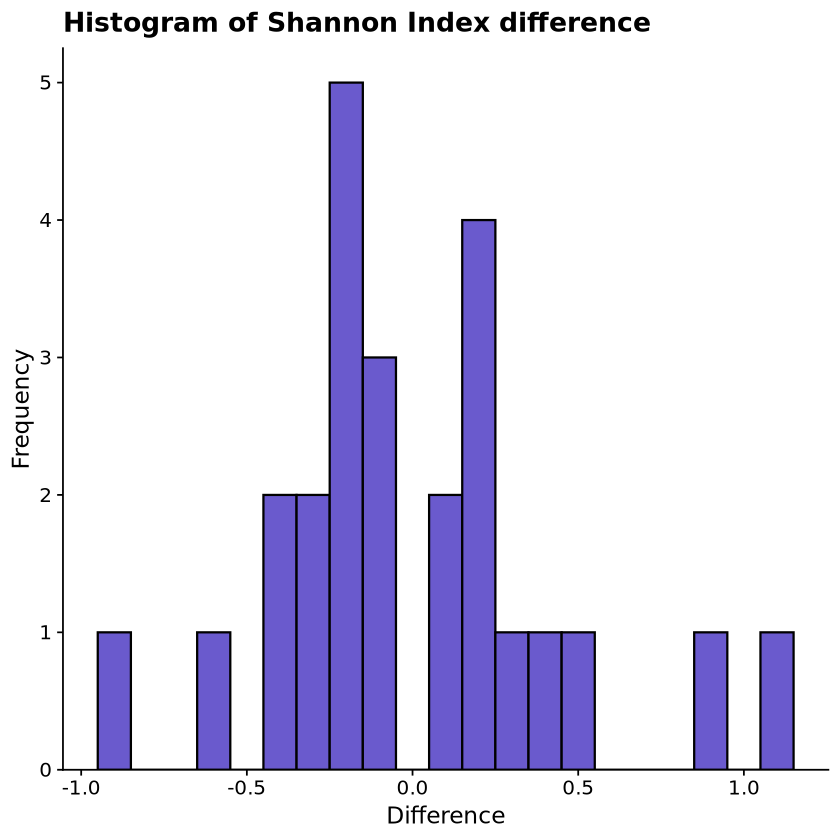

In [41]:
# View the distribution
shannon_wide_tp1 |> ggplot(aes(x = difference)) + 
  geom_histogram(binwidth = 0.1, position = "identity", fill = "slateblue", col = "black") + 
  labs(
    title = "Histogram of Shannon Index difference",
    x = "Difference",
    y = "Frequency"
  ) + 
  scale_y_continuous(
    # Don't expand y scale at the lower end
    expand = expansion(mult = c(0, 0.05))
  ) +
  theme_half_open()

In [374]:
result_shan_tp1 <- with(
  shannon_wide_tp1,
  wilcox.test(
    Nulliparous,
    Primiparous,
    paired = TRUE,
    conf.int = TRUE
  )
)
result_shan_tp1


	Wilcoxon signed rank exact test

data:  Nulliparous and Primiparous
V = 162, p-value = 1
alternative hypothesis: true location shift is not equal to 0
95 percent confidence interval:
 -0.1067174  0.1178760
sample estimates:
(pseudo)median 
 -0.0001335219 


In [375]:
shan_tp1_p <- result_shan_tp1$p.value
shan_tp1_p

[1] 1

In [43]:
summary(fp_sr_tp1)
summary(sp_sr_tp1)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  161.0   312.0   340.0   337.3   385.0   439.0 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  158.0   272.0   341.0   320.1   373.0   424.0 

In [376]:
# New df including richness
df_richness_tp1 <-  data.frame(Species_richness = c(fp_sr_tp1, sp_sr_tp1), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_sr_tp1), length(sp_sr_tp1))))
head(df_richness_tp1)

,Species_richness,Group
,<int>,<chr>
100000115046,406,Nulliparous
100000133514,416,Nulliparous
100000141564,304,Nulliparous
100000112861,336,Nulliparous
100000116982,385,Nulliparous
100000117590,380,Nulliparous


In [377]:
# Calculate difference for Shapiro test
df_richness_tp1_1 <- df_richness_tp1 |>
  rownames_to_column(var = "Sample_ID")
head(df_richness_tp1_1)

,Sample_ID,Species_richness,Group
,<chr>,<int>,<chr>
1,100000115046,406,Nulliparous
2,100000133514,416,Nulliparous
3,100000141564,304,Nulliparous
4,100000112861,336,Nulliparous
5,100000116982,385,Nulliparous
6,100000117590,380,Nulliparous


In [378]:
# Extract personal numbers for barcodes and add new column with pn to df_richness_1
df_richness_tp1_1 <- df_richness_tp1_1 |>
  left_join(
    combined_fp_sp_tp1 |>
      select(
        kit1.faecal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit1.faecal_sample.barcode")
  )
head(df_richness_tp1_1 )

,Sample_ID,Species_richness,Group,Q1_Personnummer
,<chr>,<int>,<chr>,<chr>
1,100000115046,406,Nulliparous,P719b21e
2,100000133514,416,Nulliparous,P97574f9
3,100000141564,304,Nulliparous,P3c0f6ee
4,100000112861,336,Nulliparous,Pa8f3b51
5,100000116982,385,Nulliparous,P92b4604
6,100000117590,380,Nulliparous,P9cdfd5a


In [379]:
richness_wide_tp1 <- df_richness_tp1_1 |>
  select(Q1_Personnummer, Group, Species_richness) |>
  pivot_wider(
             names_from = Group,
             values_from = Species_richness
           )
head(richness_wide_tp1 )

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<int>,<int>
P719b21e,406,424
P97574f9,416,388
P3c0f6ee,304,306
Pa8f3b51,336,341
P92b4604,385,363
P9cdfd5a,380,300


In [48]:
# Test data distribution
richness_wide_tp1$difference <- richness_wide_tp1$Primiparous - richness_wide_tp1$Nulliparous
shapiro.test(richness_wide_tp1$difference)


	Shapiro-Wilk normality test

data:  richness_wide_tp1$difference
W = 0.96929, p-value = 0.6271


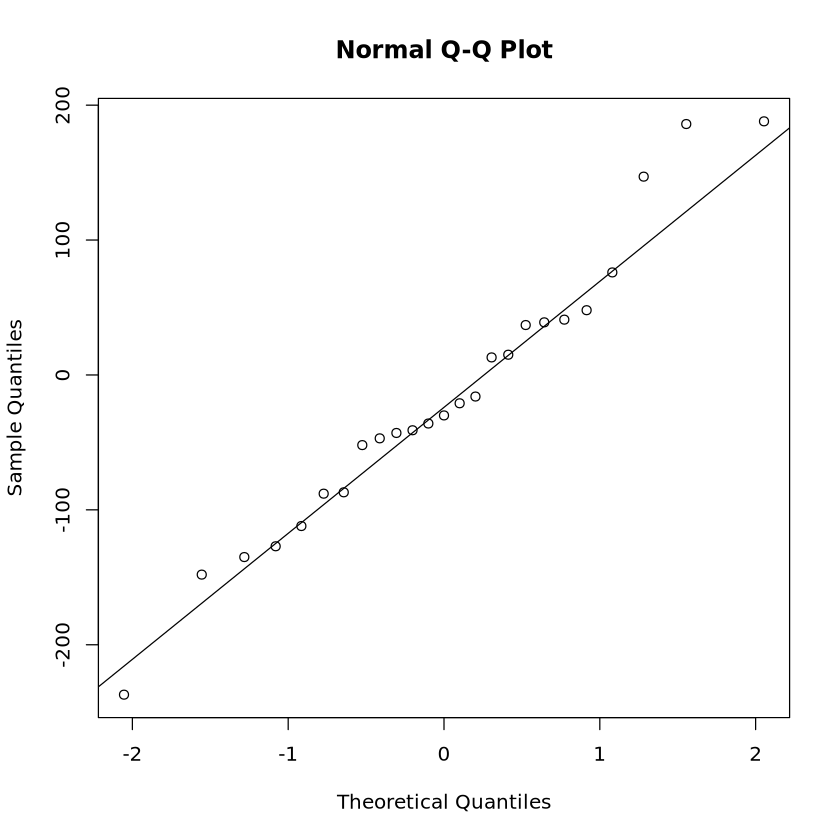

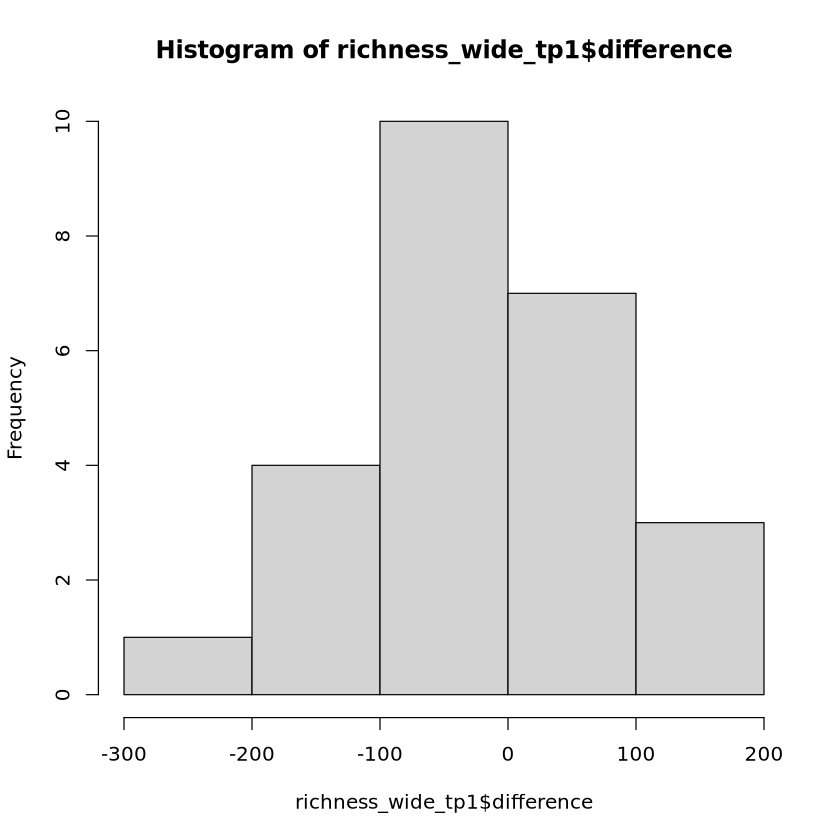

In [50]:
# Data distribution visualization
qqnorm(richness_wide_tp1$difference ); qqline(richness_wide_tp1$difference )
hist(richness_wide_tp1$difference )

In [188]:
head(shannon_wide_tp1)

Q1_Personnummer,Nulliparous,Primiparous,difference
<chr>,<dbl>,<dbl>,<dbl>
P719b21e,4.517399,4.481825,-0.03557360
P97574f9,4.461396,4.222842,-0.23855325
P3c0f6ee,4.007270,3.612441,-0.39482926
Pa8f3b51,3.939268,4.257400,0.31813230
P92b4604,4.340309,4.167370,-0.17293864
P9cdfd5a,4.061135,4.118748,0.05761296


In [380]:
result_rich_tp1 <- t.test(
  richness_wide_tp1$Nulliparous,
  richness_wide_tp1$Primiparous,
  paired = TRUE,
  conf.level = 0.95
)
result_rich_tp1


	Paired t-test

data:  richness_wide_tp1$Nulliparous and richness_wide_tp1$Primiparous
t = 1.6315, df = 24, p-value = 0.1158
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -4.558229 38.958229
sample estimates:
mean difference 
           17.2 


In [381]:
rich_tp1_p <- result_rich_tp1$p.value
rich_tp1_p

[1] 0.1158342

In [382]:
summary(fp_even_tp1)
summary(sp_even_tp1)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.5704  0.6856  0.7188  0.7097  0.7329  0.7783 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.6312  0.7112  0.7227  0.7179  0.7352  0.7496 

In [383]:
df_evenness_tp1 <-  data.frame(Evenness = c(fp_even_tp1, sp_even_tp1), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_even_tp1), length(sp_even_tp1))))
head(df_evenness_tp1)
class(df_evenness_tp1$Evenness)

,Evenness,Group
,<dbl>,<chr>
100000115046,0.7521035,Nulliparous
100000133514,0.7397825,Nulliparous
100000141564,0.7009359,Nulliparous
100000112861,0.6771863,Nulliparous
100000116982,0.7290663,Nulliparous
100000117590,0.6836731,Nulliparous


[1] "numeric"

In [384]:
df_evenness_tp1 <- df_evenness_tp1 |>
  rownames_to_column(var = "Sample_ID")
head(df_evenness_tp1)

,Sample_ID,Evenness,Group
,<chr>,<dbl>,<chr>
1,100000115046,0.7521035,Nulliparous
2,100000133514,0.7397825,Nulliparous
3,100000141564,0.7009359,Nulliparous
4,100000112861,0.6771863,Nulliparous
5,100000116982,0.7290663,Nulliparous
6,100000117590,0.6836731,Nulliparous


In [385]:
# Extract personal numbers for barcodes and add new column with pn
df_evenness_tp1 <- df_evenness_tp1|>
  left_join(
    combined_fp_sp_tp1 |>
      select(
        kit1.faecal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit1.faecal_sample.barcode")
  )
head(df_evenness_tp1 )

,Sample_ID,Evenness,Group,Q1_Personnummer
,<chr>,<dbl>,<chr>,<chr>
1,100000115046,0.7521035,Nulliparous,P719b21e
2,100000133514,0.7397825,Nulliparous,P97574f9
3,100000141564,0.7009359,Nulliparous,P3c0f6ee
4,100000112861,0.6771863,Nulliparous,Pa8f3b51
5,100000116982,0.7290663,Nulliparous,P92b4604
6,100000117590,0.6836731,Nulliparous,P9cdfd5a


In [386]:
evenness_wide_tp1 <- df_evenness_tp1 |>
  select(Q1_Personnummer, Group, Evenness) |>
  pivot_wider(
    names_from = Group,
    values_from = Evenness
  )
head(evenness_wide_tp1)

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<dbl>,<dbl>
P719b21e,0.7521035,0.7408302
P97574f9,0.7397825,0.7084111
P3c0f6ee,0.7009359,0.6311500
Pa8f3b51,0.6771863,0.7300216
P92b4604,0.7290663,0.7070047
P9cdfd5a,0.6836731,0.7221083


In [55]:
evenness_wide_tp1$difference <- evenness_wide_tp1$Primiparous - evenness_wide_tp1$Nulliparous
shapiro.test(evenness_wide_tp1$difference)


	Shapiro-Wilk normality test

data:  evenness_wide_tp1$difference
W = 0.94225, p-value = 0.1668


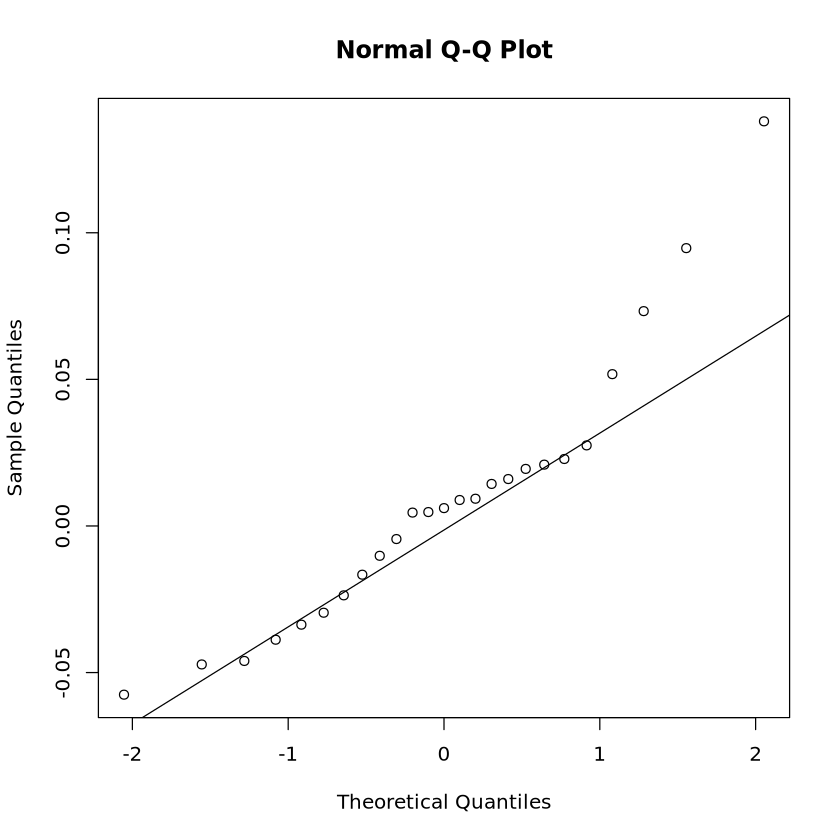

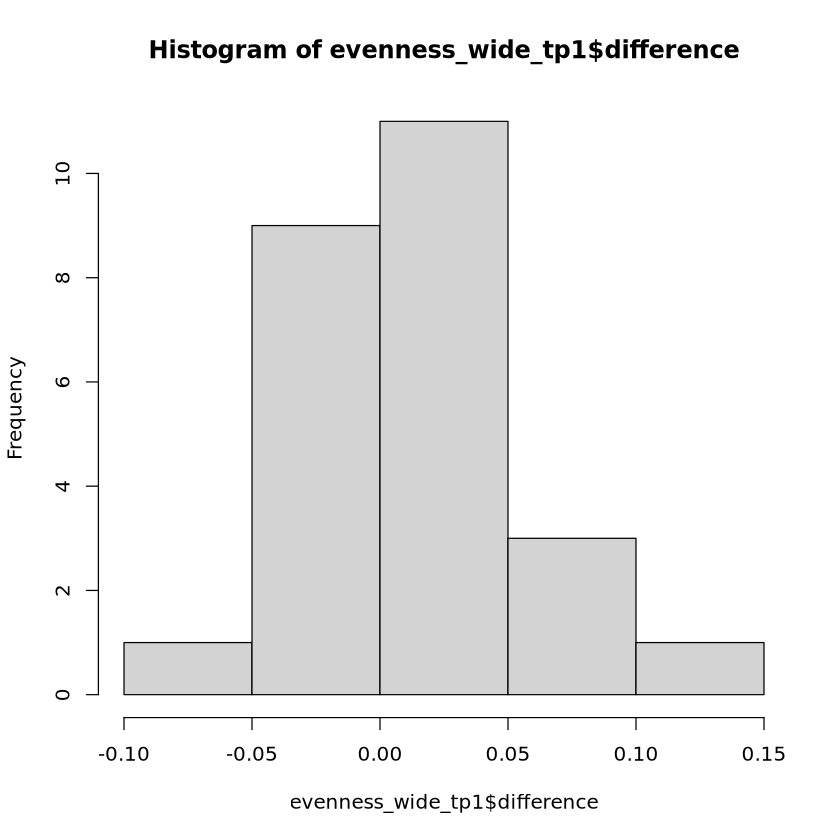

In [129]:
qqnorm(evenness_wide_tp1$difference); qqline(evenness_wide_tp1$difference)
hist(evenness_wide_tp1$difference)

In [387]:
result_evenness <- t.test(
  evenness_wide_tp1$Nulliparous,
  evenness_wide_tp1$Primiparous,
  paired = TRUE,
  conf.level = 0.95
)

result_evenness


	Paired t-test

data:  evenness_wide_tp1$Nulliparous and evenness_wide_tp1$Primiparous
t = -0.74673, df = 24, p-value = 0.4625
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -0.03080893  0.01443819
sample estimates:
mean difference 
   -0.008185367 


In [388]:
even_tp1_p <- result_evenness$p.value
even_tp1_p

[1] 0.4624776

### 4.3 Compare nulliparous vs primiparous at TP2 (paired)

In [58]:
summary(fp_shan_tp2)
summary(sp_shan_tp2)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  3.157   3.982   4.154   4.163   4.405   4.609 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  3.338   3.831   4.053   3.989   4.158   4.426 

In [389]:
# Save shannon index into one df
df_shannon_tp2 <- data.frame(Shannon = c(fp_shan_tp2, sp_shan_tp2), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_shan_tp2), length(sp_shan_tp2))))
head(df_shannon_tp2)

,Shannon,Group
,<dbl>,<chr>
100000112243,4.236528,Nulliparous
100000133958,4.277826,Nulliparous
100000168325,3.803011,Nulliparous
100000129494,3.971679,Nulliparous
100000126820,4.075306,Nulliparous
100000123362,4.105779,Nulliparous


In [390]:
df_shannon_tp2_1 <- df_shannon_tp2 |>
  rownames_to_column(var = "Sample_ID")
df_shannon_tp2_1 |> head()

,Sample_ID,Shannon,Group
,<chr>,<dbl>,<chr>
1,100000112243,4.236528,Nulliparous
2,100000133958,4.277826,Nulliparous
3,100000168325,3.803011,Nulliparous
4,100000129494,3.971679,Nulliparous
5,100000126820,4.075306,Nulliparous
6,100000123362,4.105779,Nulliparous


In [391]:
# Extract personal numbers for barcodes and add new column with pn 
df_shannon_tp2_1 <- df_shannon_tp2_1|>
  left_join(
    combined_fp_sp_tp2 |>
      select(
        kit2.faecal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit2.faecal_sample.barcode")
  )
head(df_shannon_tp2_1)

,Sample_ID,Shannon,Group,Q1_Personnummer
,<chr>,<dbl>,<chr>,<chr>
1,100000112243,4.236528,Nulliparous,P1f862a6
2,100000133958,4.277826,Nulliparous,P92b4604
3,100000168325,3.803011,Nulliparous,P3cac7b0
4,100000129494,3.971679,Nulliparous,P4de45e7
5,100000126820,4.075306,Nulliparous,P9cdfd5a
6,100000123362,4.105779,Nulliparous,P3db7da6


In [392]:
shannon_wide_tp2 <- df_shannon_tp2_1 |>
  select(Q1_Personnummer, Group, Shannon) |>
  pivot_wider(
    names_from = Group,
    values_from = Shannon
    )
shannon_wide_tp2 |> head()

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<dbl>,<dbl>
P1f862a6,4.236528,3.999929
P92b4604,4.277826,3.984390
P3cac7b0,3.803011,3.423942
P4de45e7,3.971679,3.734459
P9cdfd5a,4.075306,4.134483
P3db7da6,4.105779,3.883601


In [63]:
# Calculate the difference between groups and perform distribution test 
shannon_wide_tp2$difference <- shannon_wide_tp2$Primiparous - shannon_wide_tp2$Nulliparous
shapiro.test(shannon_wide_tp2$difference)


	Shapiro-Wilk normality test

data:  shannon_wide_tp2$difference
W = 0.94409, p-value = 0.2622


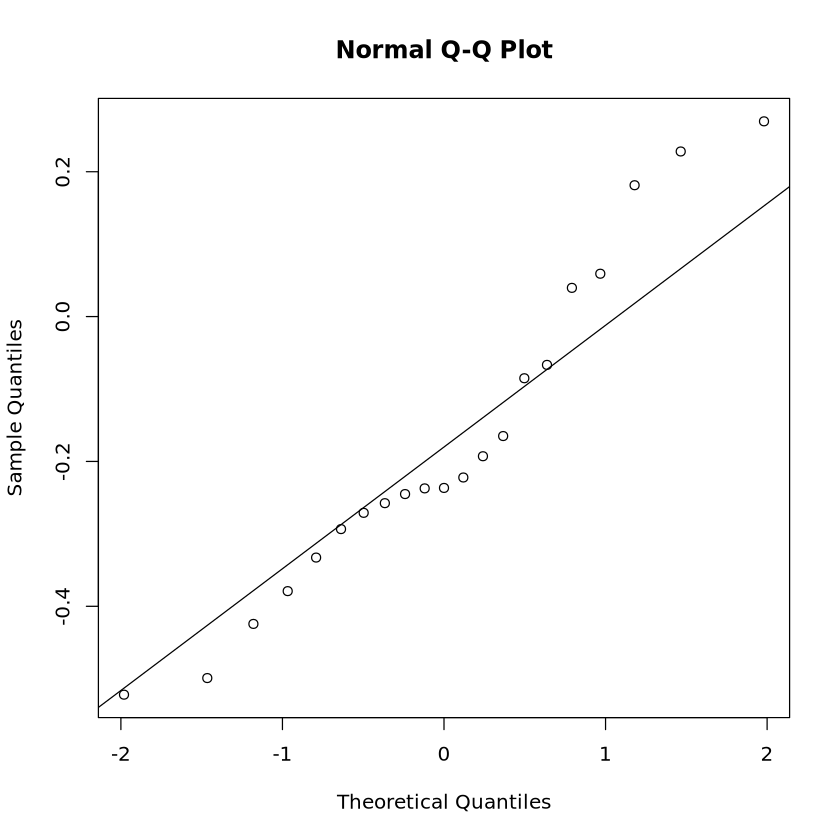

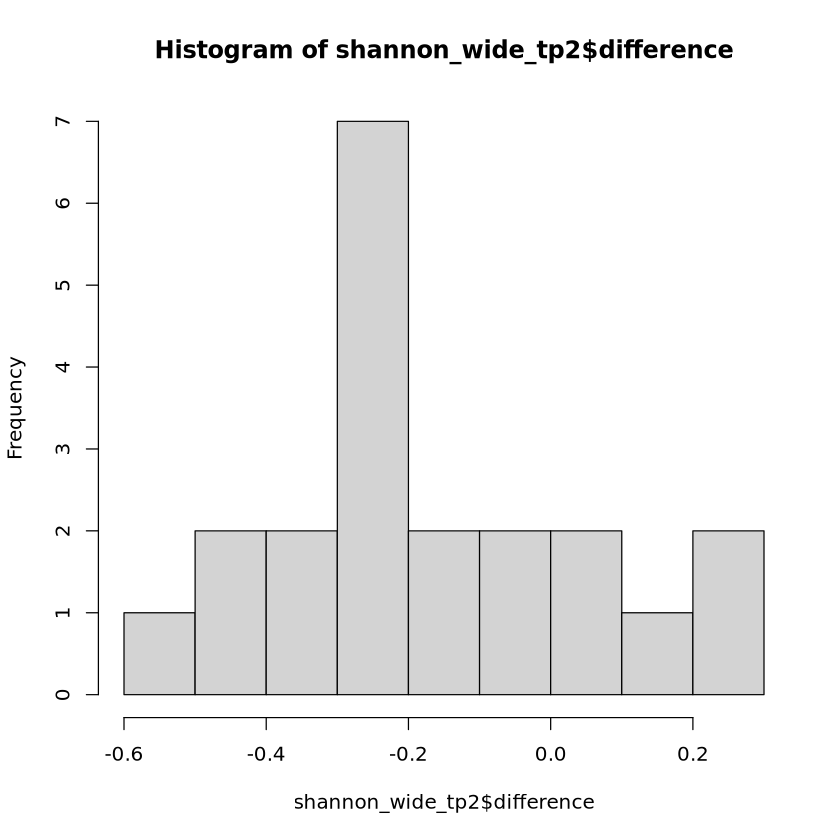

In [64]:
qqnorm(shannon_wide_tp2$difference); qqline(shannon_wide_tp2$difference)
hist(shannon_wide_tp2$difference)

In [393]:
result_shan_tp2 <- t.test(
  shannon_wide_tp2$Nulliparous,
  shannon_wide_tp2$Primiparous,
  paired = TRUE,
)

result_shan_tp2

shan_tp2_p <- result_shan_tp2$p.value
shan_tp2_p


	Paired t-test

data:  shannon_wide_tp2$Nulliparous and shannon_wide_tp2$Primiparous
t = 3.5515, df = 20, p-value = 0.002001
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 0.07176758 0.27606883
sample estimates:
mean difference 
      0.1739182 


[1] 0.002001473

In [66]:
summary(fp_sr_tp2)
summary(sp_sr_tp2)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  146.0   274.0   327.0   320.3   363.0   415.0 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  151.0   237.0   326.0   310.5   389.0   410.0 

In [394]:
df_richness_tp2 <-  data.frame(Species_richness = c(fp_sr_tp2, sp_sr_tp2), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_sr_tp2), length(sp_sr_tp2))))
head(df_richness_tp2)

,Species_richness,Group
,<int>,<chr>
100000112243,299,Nulliparous
100000133958,307,Nulliparous
100000168325,311,Nulliparous
100000129494,227,Nulliparous
100000126820,341,Nulliparous
100000123362,274,Nulliparous


In [395]:
# Calculate difference for Shapiro test
df_richness_tp2_1 <- df_richness_tp2 |>
  rownames_to_column(var = "Sample_ID")
df_richness_tp2_1 |> head()

,Sample_ID,Species_richness,Group
,<chr>,<int>,<chr>
1,100000112243,299,Nulliparous
2,100000133958,307,Nulliparous
3,100000168325,311,Nulliparous
4,100000129494,227,Nulliparous
5,100000126820,341,Nulliparous
6,100000123362,274,Nulliparous


In [396]:
# Extract personal numbers for barcodes and add new column with pn 
df_richness_tp2_1 <- df_richness_tp2_1 |>
  left_join(
    combined_fp_sp_tp2 |>
      select(
        kit2.faecal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit2.faecal_sample.barcode")
  )
head(df_richness_tp2_1)

,Sample_ID,Species_richness,Group,Q1_Personnummer
,<chr>,<int>,<chr>,<chr>
1,100000112243,299,Nulliparous,P1f862a6
2,100000133958,307,Nulliparous,P92b4604
3,100000168325,311,Nulliparous,P3cac7b0
4,100000129494,227,Nulliparous,P4de45e7
5,100000126820,341,Nulliparous,P9cdfd5a
6,100000123362,274,Nulliparous,P3db7da6


In [397]:
richness_wide_tp2 <- df_richness_tp2_1 |>
  select(Q1_Personnummer
, Group, Species_richness) |>
  pivot_wider(
             names_from = Group,
             values_from = Species_richness
           )
richness_wide_tp2 |> head()

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<int>,<int>
P1f862a6,299,338
P92b4604,307,304
P3cac7b0,311,178
P4de45e7,227,219
P9cdfd5a,341,364
P3db7da6,274,230


In [71]:
# Test data distribution
richness_wide_tp2$difference <- richness_wide_tp2$Primiparous - richness_wide_tp2$Nulliparous
shapiro.test(richness_wide_tp2$difference)


	Shapiro-Wilk normality test

data:  richness_wide_tp2$difference
W = 0.94126, p-value = 0.2308


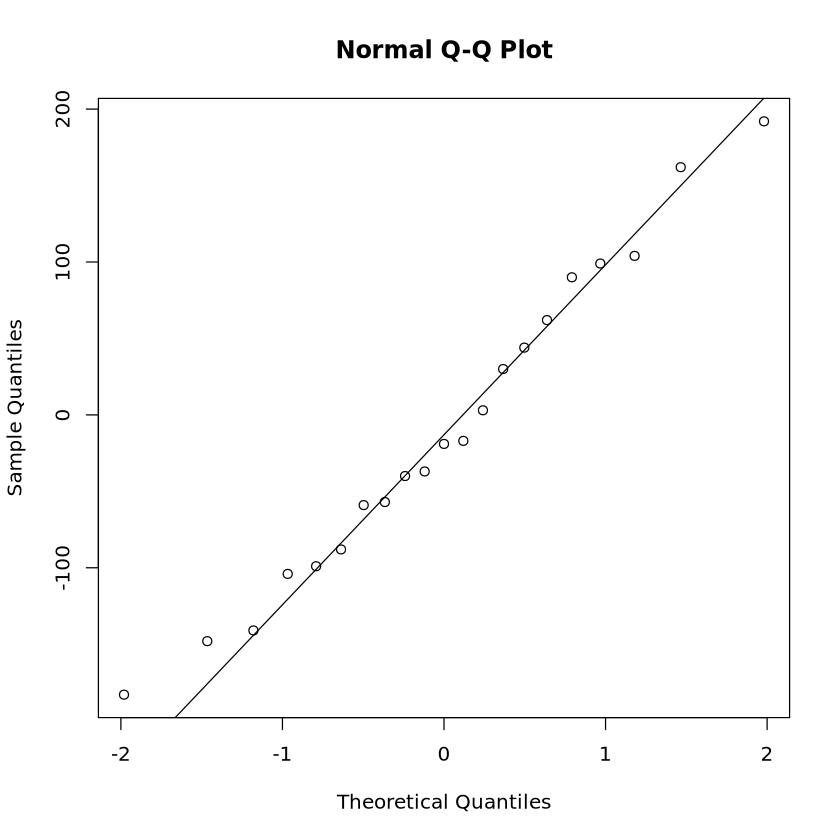

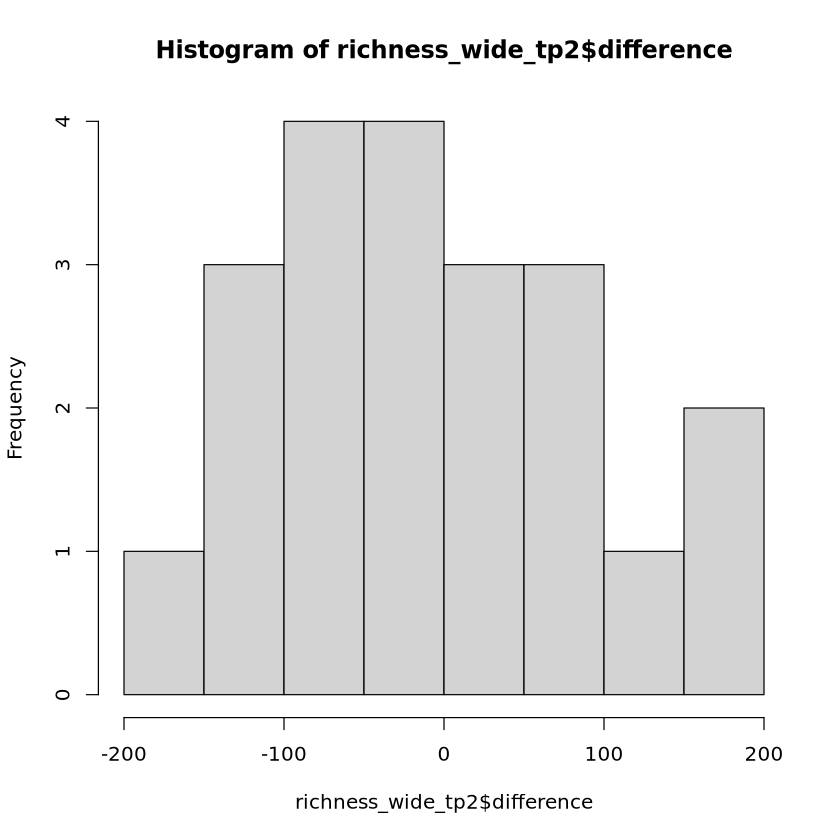

In [76]:
qqnorm(richness_wide_tp2$difference); qqline(richness_wide_tp2$difference)
hist(richness_wide_tp2$difference)

In [398]:
result_rich_tp2 <- t.test(
  richness_wide_tp2$Nulliparous,
  richness_wide_tp2$Primiparous,
  paired = TRUE
)

result_rich_tp2

# Extract p-value
rich_tp2_p <- result_rich_tp2$p.value
rich_tp2_p


	Paired t-test

data:  richness_wide_tp2$Nulliparous and richness_wide_tp2$Primiparous
t = 0.87261, df = 20, p-value = 0.3932
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -13.64012  33.25917
sample estimates:
mean difference 
       9.809524 


[1] 0.3932336

In [73]:
summary(fp_even_tp2)
summary(sp_even_tp2) 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.6335  0.6988  0.7315  0.7239  0.7470  0.7815 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.6072  0.6919  0.7011  0.6990  0.7141  0.7493 

In [399]:
df_evenness_tp2 <-  data.frame(Evenness = c(fp_even_tp2, sp_even_tp2), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_even_tp2), length(sp_even_tp2))))
head(df_evenness_tp2)
class(df_evenness_tp2$Evenness)

,Evenness,Group
,<dbl>,<chr>
100000112243,0.7431927,Nulliparous
100000133958,0.7469774,Nulliparous
100000168325,0.6625695,Nulliparous
100000129494,0.7321135,Nulliparous
100000126820,0.6987976,Nulliparous
100000123362,0.7314601,Nulliparous


[1] "numeric"

In [400]:
df_evenness_tp2_1 <- df_evenness_tp2 |>
  rownames_to_column(var = "Sample_ID")
head(df_evenness_tp2_1)

,Sample_ID,Evenness,Group
,<chr>,<dbl>,<chr>
1,100000112243,0.7431927,Nulliparous
2,100000133958,0.7469774,Nulliparous
3,100000168325,0.6625695,Nulliparous
4,100000129494,0.7321135,Nulliparous
5,100000126820,0.6987976,Nulliparous
6,100000123362,0.7314601,Nulliparous


In [401]:
# Extract personal numbers for barcodes and add new column with pn 
df_evenness_tp2_1 <- df_evenness_tp2_1|>
  left_join(
    combined_fp_sp_tp2 |>
      select(
        kit2.faecal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit2.faecal_sample.barcode")
  )
head(df_evenness_tp2_1)

,Sample_ID,Evenness,Group,Q1_Personnummer
,<chr>,<dbl>,<chr>,<chr>
1,100000112243,0.7431927,Nulliparous,P1f862a6
2,100000133958,0.7469774,Nulliparous,P92b4604
3,100000168325,0.6625695,Nulliparous,P3cac7b0
4,100000129494,0.7321135,Nulliparous,P4de45e7
5,100000126820,0.6987976,Nulliparous,P9cdfd5a
6,100000123362,0.7314601,Nulliparous,P3db7da6


In [402]:
evenness_wide_tp2 <- df_evenness_tp2_1 |>
  select(Q1_Personnummer, Group, Evenness) |>
  pivot_wider(
    names_from = Group,
    values_from = Evenness
  )
head(evenness_wide_tp2)

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<dbl>,<dbl>
P1f862a6,0.7431927,0.6869136
P92b4604,0.7469774,0.6969338
P3cac7b0,0.6625695,0.6607651
P4de45e7,0.7321135,0.6929690
P9cdfd5a,0.6987976,0.7010981
P3db7da6,0.7314601,0.7141494


In [79]:
evenness_wide_tp2$difference <- evenness_wide_tp2$Primiparous - evenness_wide_tp2$Nulliparous
shapiro.test(evenness_wide_tp2$difference)


	Shapiro-Wilk normality test

data:  evenness_wide_tp2$difference
W = 0.98316, p-value = 0.9632


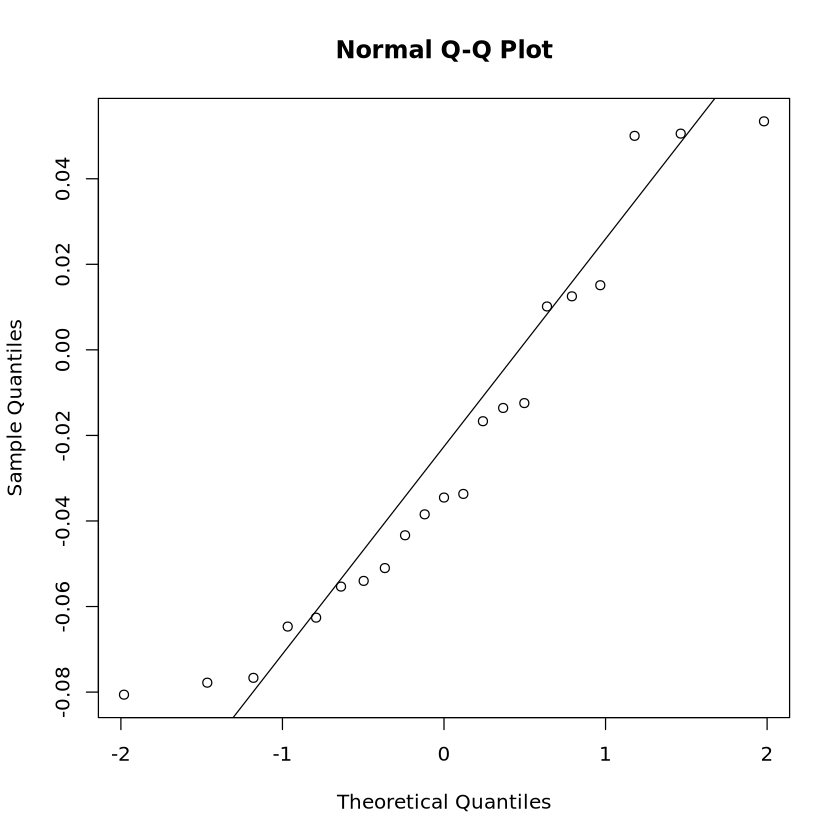

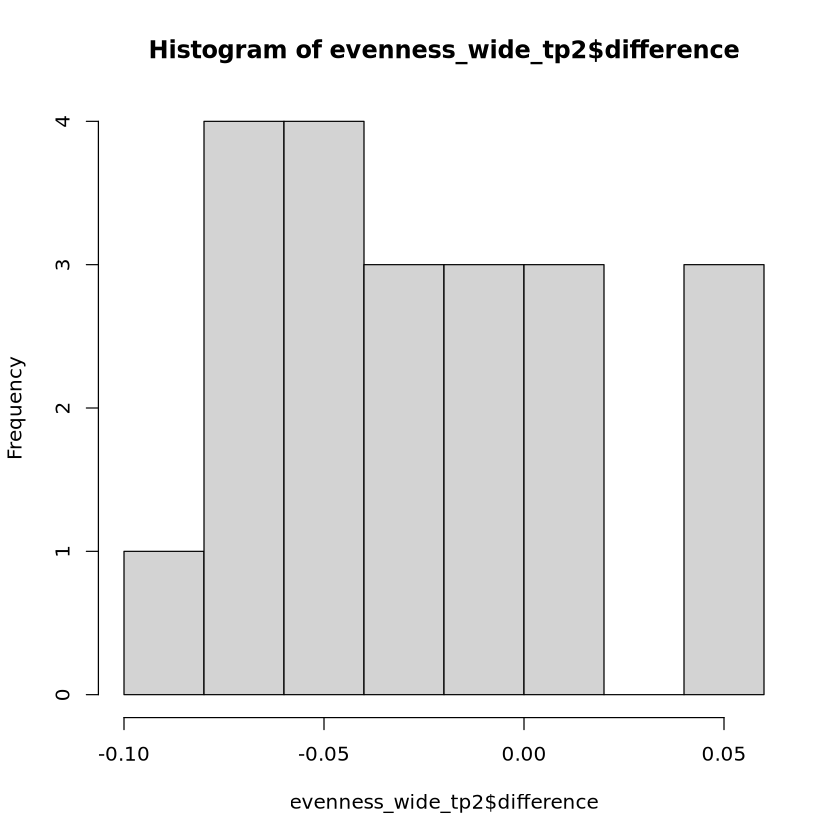

In [215]:
qqnorm(evenness_wide_tp2$difference); qqline(evenness_wide_tp2$difference)
hist(evenness_wide_tp2$difference)

In [403]:
# Paired t-test
result_evenness_tp2 <- t.test(
  evenness_wide_tp2$Nulliparous,
  evenness_wide_tp2$Primiparous,
  paired = TRUE)

result_evenness_tp2

# Extract p-value
evenness_p_tp2 <- result_evenness_tp2$p.value
evenness_p_tp2


	Paired t-test

data:  evenness_wide_tp2$Nulliparous and evenness_wide_tp2$Primiparous
t = 3.558, df = 20, p-value = 0.001971
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 0.01031689 0.03955571
sample estimates:
mean difference 
      0.0249363 


[1] 0.001971368

## 5. Delta alpha diversity (within-subject change, TP1→TP2)

For each woman, the change in each alpha diversity metric from TP1 to TP2,
calculated separately for her first and second pregnancy.

In [404]:
df_alpha_tp1 <- df_shannon_tp1_1 %>%
  full_join(df_richness_tp1_1, by = c("Sample_ID", "Group", "Q1_Personnummer")) %>%
  full_join(df_evenness_tp1,   by = c("Sample_ID", "Group", "Q1_Personnummer")) %>%
  mutate(Time_point = "TP1")

head(df_alpha_tp1)

,Sample_ID,Shannon,Group,Q1_Personnummer,Species_richness,Evenness,Time_point
,<chr>,<dbl>,<chr>,<chr>,<int>,<dbl>,<chr>
1,100000115046,4.517399,Nulliparous,P719b21e,406,0.7521035,TP1
2,100000133514,4.461396,Nulliparous,P97574f9,416,0.7397825,TP1
3,100000141564,4.007270,Nulliparous,P3c0f6ee,304,0.7009359,TP1
4,100000112861,3.939268,Nulliparous,Pa8f3b51,336,0.6771863,TP1
5,100000116982,4.340309,Nulliparous,P92b4604,385,0.7290663,TP1
6,100000117590,4.061135,Nulliparous,P9cdfd5a,380,0.6836731,TP1


In [405]:
nrow(df_alpha_tp1)          
nrow(df_shannon_tp1_1) 

[1] 50

[1] 50

In [406]:
df_alpha_tp2 <- df_shannon_tp2_1 %>%
  full_join(df_richness_tp2_1, by = c("Sample_ID", "Group", "Q1_Personnummer")) %>%
  full_join(df_evenness_tp2_1,   by = c("Sample_ID", "Group", "Q1_Personnummer")) %>%
  mutate(Time_point = "TP2")

head(df_alpha_tp2)

,Sample_ID,Shannon,Group,Q1_Personnummer,Species_richness,Evenness,Time_point
,<chr>,<dbl>,<chr>,<chr>,<int>,<dbl>,<chr>
1,100000112243,4.236528,Nulliparous,P1f862a6,299,0.7431927,TP2
2,100000133958,4.277826,Nulliparous,P92b4604,307,0.7469774,TP2
3,100000168325,3.803011,Nulliparous,P3cac7b0,311,0.6625695,TP2
4,100000129494,3.971679,Nulliparous,P4de45e7,227,0.7321135,TP2
5,100000126820,4.075306,Nulliparous,P9cdfd5a,341,0.6987976,TP2
6,100000123362,4.105779,Nulliparous,P3db7da6,274,0.7314601,TP2


In [407]:
nrow(df_alpha_tp2)          
nrow(df_shannon_tp2_1) 

[1] 42

[1] 42

In [408]:
df_alpha_tp1_1 <- df_alpha_tp1 %>% filter(Q1_Personnummer %in% df_alpha_tp2$Q1_Personnummer)
dim(df_alpha_tp1_1)

[1] 42  7

In [409]:
all_alpha <- bind_rows(df_alpha_tp1_1,df_alpha_tp2) 
head(all_alpha )

,Sample_ID,Shannon,Group,Q1_Personnummer,Species_richness,Evenness,Time_point
,<chr>,<dbl>,<chr>,<chr>,<int>,<dbl>,<chr>
1,100000115046,4.517399,Nulliparous,P719b21e,406,0.7521035,TP1
2,100000133514,4.461396,Nulliparous,P97574f9,416,0.7397825,TP1
3,100000116982,4.340309,Nulliparous,P92b4604,385,0.7290663,TP1
4,100000117590,4.061135,Nulliparous,P9cdfd5a,380,0.6836731,TP1
5,100000126486,3.276238,Nulliparous,Pdab1897,161,0.6447505,TP1
6,100000114162,3.861882,Nulliparous,P4de45e7,210,0.7222376,TP1


### 5.1 Calculate delta alpha (TP2 − TP1) per pregnancy

In [410]:
# Reshape so each woman/group has TP1 and TP2 side by side, for all three metrics
alpha_wide <- all_alpha %>%
  pivot_wider(
    id_cols = c(Q1_Personnummer	, Group),
    names_from = Time_point,
    values_from = c(Sample_ID, Shannon, Species_richness, Evenness)
  )

head(alpha_wide)

Q1_Personnummer,Group,Sample_ID_TP1,Sample_ID_TP2,Shannon_TP1,Shannon_TP2,Species_richness_TP1,Species_richness_TP2,Evenness_TP1,Evenness_TP2
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>
P719b21e,Nulliparous,100000115046,100000126714,4.517399,4.550494,406,385,0.7521035,0.7643723
P97574f9,Nulliparous,100000133514,100000148082,4.461396,4.153986,416,390,0.7397825,0.6962594
P92b4604,Nulliparous,100000116982,100000133958,4.340309,4.277826,385,307,0.7290663,0.7469774
P9cdfd5a,Nulliparous,100000117590,100000126820,4.061135,4.075306,380,341,0.6836731,0.6987976
Pdab1897,Nulliparous,100000126486,100000148693,3.276238,3.157082,161,146,0.6447505,0.6334935
P4de45e7,Nulliparous,100000114162,100000129494,3.861882,3.971679,210,227,0.7222376,0.7321135


In [411]:
# Calculate delta (TP2 - TP1) for each metric
alpha_delta <- alpha_wide %>%
  mutate(
    delta_Shannon  = Shannon_TP2  - Shannon_TP1,
    delta_Richness = Species_richness_TP2 - Species_richness_TP1,
    delta_Evenness = Evenness_TP2 - Evenness_TP1
  )

head(alpha_delta)


Q1_Personnummer,Group,Sample_ID_TP1,Sample_ID_TP2,Shannon_TP1,Shannon_TP2,Species_richness_TP1,Species_richness_TP2,Evenness_TP1,Evenness_TP2,delta_Shannon,delta_Richness,delta_Evenness
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
P719b21e,Nulliparous,100000115046,100000126714,4.517399,4.550494,406,385,0.7521035,0.7643723,0.03309508,-21,0.01226880
P97574f9,Nulliparous,100000133514,100000148082,4.461396,4.153986,416,390,0.7397825,0.6962594,-0.30740998,-26,-0.04352315
P92b4604,Nulliparous,100000116982,100000133958,4.340309,4.277826,385,307,0.7290663,0.7469774,-0.06248300,-78,0.01791114
P9cdfd5a,Nulliparous,100000117590,100000126820,4.061135,4.075306,380,341,0.6836731,0.6987976,0.01417016,-39,0.01512450
Pdab1897,Nulliparous,100000126486,100000148693,3.276238,3.157082,161,146,0.6447505,0.6334935,-0.11915587,-15,-0.01125705
P4de45e7,Nulliparous,100000114162,100000129494,3.861882,3.971679,210,227,0.7222376,0.7321135,0.10979698,17,0.00987589


In [412]:
dim(alpha_delta)

[1] 42 13

In [413]:
alpha_delta_N <- alpha_delta %>% filter(Group == "Nulliparous")
dim(alpha_delta_N )
#alpha_delta_N

[1] 21 13

In [414]:
alpha_delta_P <- alpha_delta %>% filter(Group == "Primiparous")
dim(alpha_delta_P )
#alpha_delta_P

[1] 21 13

### 5.2 Compare delta alpha between pregnancies (paired)

Tests whether the amount and direction of diversity change across gestation
differs between the first and second pregnancy.

In [93]:
shan_difference <- alpha_delta_P$delta_Shannon - alpha_delta_N$delta_Shannon
shapiro.test(shan_difference)


	Shapiro-Wilk normality test

data:  shan_difference
W = 0.96621, p-value = 0.6486


In [415]:
delta_shan <- t.test(alpha_delta_N$delta_Shannon, alpha_delta_P$delta_Shannon, paired = TRUE)
delta_shan 
delta_shan_p <- delta_shan$p.value


	Paired t-test

data:  alpha_delta_N$delta_Shannon and alpha_delta_P$delta_Shannon
t = 2.3749, df = 20, p-value = 0.02767
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 0.02159655 0.33337931
sample estimates:
mean difference 
      0.1774879 


In [95]:
rich_difference <- alpha_delta_P$delta_Richness - alpha_delta_N$delta_Richness
shapiro.test(rich_difference)


	Shapiro-Wilk normality test

data:  rich_difference
W = 0.94976, p-value = 0.3371


In [416]:
delta_rich <- t.test(alpha_delta_N$delta_Richness, alpha_delta_P$delta_Richness, paired = TRUE)
delta_rich 
delta_rich_p <- delta_rich$p.value


	Paired t-test

data:  alpha_delta_N$delta_Richness and alpha_delta_P$delta_Richness
t = -0.73529, df = 20, p-value = 0.4707
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -41.29250  19.76869
sample estimates:
mean difference 
       -10.7619 


In [97]:
even_difference <- alpha_delta_P$delta_Evenness - alpha_delta_N$delta_Evenness
shapiro.test(even_difference)


	Shapiro-Wilk normality test

data:  even_difference
W = 0.9278, p-value = 0.1243


In [417]:
delta_even <- t.test(alpha_delta_N$delta_Evenness, alpha_delta_P$delta_Evenness, paired = TRUE)
delta_even 
delta_even_p <- delta_even$p.value


	Paired t-test

data:  alpha_delta_N$delta_Evenness and alpha_delta_P$delta_Evenness
t = 3.261, df = 20, p-value = 0.00391
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 0.01246999 0.05674253
sample estimates:
mean difference 
     0.03460626 


## 6. Beta diversity 

In [184]:
combined_fp_sp_tp1$Time_point <- "TP1"
combined_fp_sp_tp2$Time_point <- "TP2"

In [185]:
combined_fp_sp_tp1 <- combined_fp_sp_tp1 %>%
  rename(Sample_id = kit1.faecal_sample.barcode)

combined_fp_sp_tp2<- combined_fp_sp_tp2 %>%
  rename(Sample_id = kit2.faecal_sample.barcode)

In [186]:
meta_tp1 <- combined_fp_sp_tp1 %>% 
            select(Studienummer,Q1_Personnummer,Sample_id, Group, Time_point)
meta_tp2 <- combined_fp_sp_tp2 %>% 
           select(Studienummer,Q1_Personnummer,Sample_id, Group, Time_point)

In [187]:
rownames(meta_tp1) <- meta_tp1$Sample_id
rownames(meta_tp2) <- meta_tp2$Sample_id

In [188]:
dim(meta_tp1)
dim(meta_tp2)

[1] 50  5

[1] 42  5

In [189]:
head(meta_tp1)

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>
100000128343,S194e21b,P159f9c8,100000128343,Nulliparous,TP1
100000158999,S1a267fa,P1a267fa,100000158999,Nulliparous,TP1
100000101469,Sa8397fa,P1ef420d,100000101469,Nulliparous,TP1
100000103241,S1f862a6,P1f862a6,100000103241,Nulliparous,TP1
100000141564,S3c0f6ee,P3c0f6ee,100000141564,Nulliparous,TP1
100000157404,S2b86cc0,P3cac7b0,100000157404,Nulliparous,TP1


In [190]:
head(taxa_tab_tp1)

,100000115046,100000133514,100000138427,100000416914,100000416341,100000417300,100000141564,100000112861,100000116982,100000117590,⋯,100000404683,100000410189,100000180006,100000410554,100000422410,100000424421,100000167687,100000422946,100000165058,100000419175
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Coprococcus eutactus,1.92768,0.15521,0.05160,0.02486,6.62230,0.30236,2.25139,0.00000,0.00000,0.42317,⋯,0.16779,2.72513,0.00000,0.93544,0.00000,4.42402,0.00000,4.46554,0.00000,0.00000
Faecalibacterium prausnitzii,3.20883,4.32581,4.53698,3.39437,3.26358,7.13674,4.51069,7.70578,4.33970,0.19672,⋯,2.84157,3.24886,5.24076,1.91233,6.89058,7.44669,2.90277,6.99612,6.78398,7.72660
Ruminococcus bromii,12.75072,0.84583,5.68254,2.92580,0.00044,4.13723,5.12663,4.96465,1.35757,8.26843,⋯,4.74826,12.33869,7.39686,0.00842,0.00135,1.89198,7.79235,0.00361,13.89218,0.00000
Ruminococcus bicirculans,0.64417,0.04445,2.55341,0.11893,0.09988,1.25623,1.32888,0.00064,4.66429,0.70478,⋯,0.19760,0.28484,0.00000,0.01427,0.10956,1.09689,0.10850,3.50633,0.00000,0.00000
Eubacterium rectale,0.95028,1.20350,5.57078,0.13382,2.26475,3.46031,0.59886,0.63884,2.51539,0.09724,⋯,0.12479,3.22173,1.25968,0.10241,4.25136,1.03758,21.90512,0.20310,2.13466,8.66076
Phocaeicola vulgatus,1.31137,1.54361,0.37413,0.28747,0.96566,2.37364,2.17415,3.13447,0.00000,2.93263,⋯,2.52242,2.21001,5.07246,3.08527,2.57127,1.68231,0.00026,3.65610,4.75778,4.36198


In [27]:
head(taxa_tab_tp2)

,100000112243,100000133958,100000418123,100000168325,100000129494,100000126820,100000123362,100000126714,100000421192,100000427415,⋯,100000426050,100000433645,100000106303,100000106341,100000103470,100000106136,100000108482,100000157503,100000148082,100000148693
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Acidaminococcus intestini,0.00000,1.32773,0.00000,0,0,0.00000,0,0.00000,0.00000,0.00000,⋯,0,0.00000,0.00000,0.00000,0e+00,0.00000,0.00000,0.00000,0.00000,0.0000
Acinetobacter SGB65105,0.00000,0.00000,0.00000,0,0,0.00000,0,0.00000,0.00000,0.00000,⋯,0,0.00000,0.00000,0.00000,0e+00,0.00000,0.00000,0.05408,0.00000,0.0000
Actinobaculum sp_oral_taxon_183,0.00000,0.00000,0.00000,0,0,0.00010,0,0.00000,0.00000,0.00000,⋯,0,0.00000,0.00000,0.00000,0e+00,0.00000,0.00000,0.00000,0.00000,0.0000
Actinomyces bouchesdurhonensis,0.00000,0.00000,0.00000,0,0,0.00674,0,0.00000,0.00000,0.00073,⋯,0,0.00000,0.00000,0.00188,7e-05,0.00000,0.00492,0.00222,0.00059,0.0000
Actinomyces graevenitzii,0.00211,0.00000,0.00203,0,0,0.00000,0,0.00279,0.00143,0.00254,⋯,0,0.00695,0.00094,0.00045,0e+00,0.00093,0.00036,0.00000,0.00032,0.0011
Actinomyces naeslundii,0.00000,0.00000,0.00000,0,0,0.00000,0,0.00000,0.00000,0.00234,⋯,0,0.00258,0.00000,0.00000,0e+00,0.00000,0.00000,0.00000,0.00000,0.0000


In [191]:
taxa_tp1 <- as.data.frame(t(taxa_tab_tp1))
class(taxa_tp1)
head(taxa_tp1)

[1] "data.frame"

,Coprococcus eutactus,Faecalibacterium prausnitzii,Ruminococcus bromii,Ruminococcus bicirculans,Eubacterium rectale,Phocaeicola vulgatus,Candidatus Cibionibacter_quicibialis,Lachnospira pectinoschiza,Clostridium sp_AF34_10BH,Catenibacterium SGB4425,⋯,GGB3111 SGB4123,Staphylococcus aureus,GGB9522 SGB98319,Candidatus Alangreenwoodia_gallinarii,GGB4723 SGB6540,GGB28474 SGB41058,GGB6123 SGB8767,GGB9060 SGB13977,Oscillospiraceae unclassified_SGB15252,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100000115046,1.92768,3.20883,12.75072,0.64417,0.95028,1.31137,1.09072,0.27629,2.24122,0.00000,⋯,0,0,0.00000,0,0,0.00000,0,0,0,2.36071
100000133514,0.15521,4.32581,0.84583,0.04445,1.20350,1.54361,4.83623,0.00000,0.05056,0.00000,⋯,0,0,0.00000,0,0,0.00000,0,0,0,4.74968
100000138427,0.05160,4.53698,5.68254,2.55341,5.57078,0.37413,0.25773,0.37810,0.00317,0.00000,⋯,0,0,0.00000,0,0,0.00000,0,0,0,2.96481
100000416914,0.02486,3.39437,2.92580,0.11893,0.13382,0.28747,7.79970,0.08632,0.03749,0.13595,⋯,0,0,0.01279,0,0,0.00532,0,0,0,0.07106
100000416341,6.62230,3.26358,0.00044,0.09988,2.26475,0.96566,0.68823,0.03252,0.17014,0.00000,⋯,0,0,0.00766,0,0,0.00000,0,0,0,2.25795
100000417300,0.30236,7.13674,4.13723,1.25623,3.46031,2.37364,1.02179,0.00095,3.69770,1.54096,⋯,0,0,0.00000,0,0,0.00573,0,0,0,7.41692


In [192]:
taxa_tp2 <- as.data.frame(t(taxa_tab_tp2))
class(taxa_tp2)
head(taxa_tp2)

[1] "data.frame"

,Acidaminococcus intestini,Acinetobacter SGB65105,Actinobaculum sp_oral_taxon_183,Actinomyces bouchesdurhonensis,Actinomyces graevenitzii,Actinomyces naeslundii,Actinomyces oris,Actinomyces SGB17132,Actinomyces SGB17154,Actinomyces SGB17157,⋯,Veillonella parvula,Veillonella rogosae,Vescimonas coprocola,Vescimonas fastidiosa,Vescimonas SGB15086,Vescimonas SGB15087,Victivallis lenta,Victivallis vadensis,Waltera intestinalis,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100000112243,0.00000,0,0e+00,0.00000,0.00211,0,0.00082,0.00000,0.00247,0,⋯,0.00234,0,0.01998,0,0,0.00359,0.01133,0.00000,0.00387,2.47230
100000133958,1.32773,0,0e+00,0.00000,0.00000,0,0.00000,0.00000,0.00000,0,⋯,0.00000,0,0.10240,0,0,0.00000,0.00000,0.01186,0.05861,5.82934
100000418123,0.00000,0,0e+00,0.00000,0.00203,0,0.00000,0.00000,0.00000,0,⋯,0.00025,0,0.19758,0,0,0.00000,0.00000,0.00000,0.00700,0.86371
100000168325,0.00000,0,0e+00,0.00000,0.00000,0,0.00100,0.00000,0.00000,0,⋯,0.00000,0,0.11860,0,0,0.00000,0.00000,0.00000,0.01722,0.42482
100000129494,0.00000,0,0e+00,0.00000,0.00000,0,0.00000,0.00000,0.00000,0,⋯,0.00000,0,0.10710,0,0,0.00000,0.00000,0.00000,0.05579,1.55244
100000126820,0.00000,0,1e-04,0.00674,0.00000,0,0.00159,0.00064,0.00967,0,⋯,0.00000,0,0.00621,0,0,0.00000,0.02110,0.00000,0.00000,1.72654


In [193]:
ordered_taxa_tp1 <- taxa_tp1[rownames(meta_tp1), ]
head(ordered_taxa_tp1)

,Coprococcus eutactus,Faecalibacterium prausnitzii,Ruminococcus bromii,Ruminococcus bicirculans,Eubacterium rectale,Phocaeicola vulgatus,Candidatus Cibionibacter_quicibialis,Lachnospira pectinoschiza,Clostridium sp_AF34_10BH,Catenibacterium SGB4425,⋯,GGB3111 SGB4123,Staphylococcus aureus,GGB9522 SGB98319,Candidatus Alangreenwoodia_gallinarii,GGB4723 SGB6540,GGB28474 SGB41058,GGB6123 SGB8767,GGB9060 SGB13977,Oscillospiraceae unclassified_SGB15252,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100000128343,0.59547,6.82400,1.38387,0.00654,0.46567,0.25955,1.49173,0.00504,0.00789,0.00000,⋯,0.00000,0,0,0,0.00000,0.00000,0,0,0,6.16479
100000158999,6.72788,7.04024,3.76092,0.13935,7.38137,3.14812,0.20532,0.00000,3.49831,0.00000,⋯,0.00000,0,0,0,0.00000,0.00000,0,0,0,1.37777
100000101469,4.80249,4.01328,1.34922,0.30952,0.05896,1.08699,0.53858,1.38728,0.00316,0.00000,⋯,0.00000,0,0,0,0.04517,0.00000,0,0,0,17.92002
100000103241,0.03544,2.66174,0.00155,1.77788,1.37398,0.14914,0.95643,0.16198,0.00491,0.00000,⋯,0.21458,0,0,0,0.00000,0.00000,0,0,0,8.35886
100000141564,2.25139,4.51069,5.12663,1.32888,0.59886,2.17415,2.84426,0.64394,1.32398,0.32968,⋯,0.00000,0,0,0,0.00000,0.00011,0,0,0,8.73482
100000157404,1.70440,8.60404,5.88083,3.50807,10.22686,0.53735,0.78280,0.00000,0.05273,0.00000,⋯,0.00000,0,0,0,0.00000,0.00000,0,0,0,0.21623


In [194]:
ordered_taxa_tp2 <- taxa_tp2[rownames(meta_tp2), ]
head(ordered_taxa_tp2)

,Acidaminococcus intestini,Acinetobacter SGB65105,Actinobaculum sp_oral_taxon_183,Actinomyces bouchesdurhonensis,Actinomyces graevenitzii,Actinomyces naeslundii,Actinomyces oris,Actinomyces SGB17132,Actinomyces SGB17154,Actinomyces SGB17157,⋯,Veillonella parvula,Veillonella rogosae,Vescimonas coprocola,Vescimonas fastidiosa,Vescimonas SGB15086,Vescimonas SGB15087,Victivallis lenta,Victivallis vadensis,Waltera intestinalis,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100000144381,0,0,0,0.00445,0.00103,0.00014,0.00060,0.00000,0.00000,0,⋯,0.06635,0.02263,0.16424,0.05982,0,0.00000,0.00000,0,4.37013,0.83921
100000172865,0,0,0,0.00000,0.00044,0.00000,0.00094,0.00038,0.00000,0,⋯,0.04345,0.00338,0.35493,0.00000,0,0.00000,0.00000,0,0.00404,1.26158
100000112243,0,0,0,0.00000,0.00211,0.00000,0.00082,0.00000,0.00247,0,⋯,0.00234,0.00000,0.01998,0.00000,0,0.00359,0.01133,0,0.00387,2.47230
100000168325,0,0,0,0.00000,0.00000,0.00000,0.00100,0.00000,0.00000,0,⋯,0.00000,0.00000,0.11860,0.00000,0,0.00000,0.00000,0,0.01722,0.42482
100000123362,0,0,0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0,⋯,0.00000,0.00000,0.02722,0.00000,0,0.00000,0.00000,0,0.22885,1.59920
100000106341,0,0,0,0.00188,0.00045,0.00000,0.00158,0.00000,0.00463,0,⋯,0.00264,0.00000,0.62222,0.00000,0,0.00000,0.24265,0,0.94727,0.57416


In [195]:
all(rownames(ordered_taxa_tp1) == rownames(meta_tp1))
all(rownames(ordered_taxa_tp2) == rownames(meta_tp2))

[1] TRUE

[1] TRUE

### 6.1 Calculate distance matrices

In [53]:
dist_bc_tp1 <- vegdist(ordered_taxa_tp1, method = "bray")
dist_jac_tp1 <- vegdist(ordered_taxa_tp1, method = "jaccard", binary = TRUE)
dist_ait_tp1 <- vegdist(ordered_taxa_tp1, method = "robust.aitchison")

In [274]:
dist_bc_tp2 <- vegdist(ordered_taxa_tp2, method = "bray")
dist_jac_tp2 <- vegdist(ordered_taxa_tp2, method = "jaccard", binary = TRUE)
dist_ait_tp2 <- vegdist(ordered_taxa_tp2, method = "robust.aitchison")

In [55]:
all(labels(dist_bc_tp1) == rownames(meta_tp1))
all(labels(dist_jac_tp1) == rownames(meta_tp1))
all(labels(dist_ait_tp1) == rownames(meta_tp1))

[1] TRUE

[1] TRUE

[1] TRUE

In [275]:
all(labels(dist_bc_tp2) == rownames(meta_tp2))
all(labels(dist_jac_tp2) == rownames(meta_tp2))
all(labels(dist_ait_tp2) == rownames(meta_tp2))

[1] TRUE

[1] TRUE

[1] TRUE

### 6.2. Dispersion check (betadisper)

In [37]:
set.seed(123)
dispersion_J_tp1 <- vegan::betadisper(dist_jac_tp1, meta_tp1$Group)
permutest(dispersion_J_tp1)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq   Mean Sq      F N.Perm Pr(>F)
Groups     1 0.000428 0.0004283 0.1491    999  0.683
Residuals 48 0.137893 0.0028728                     

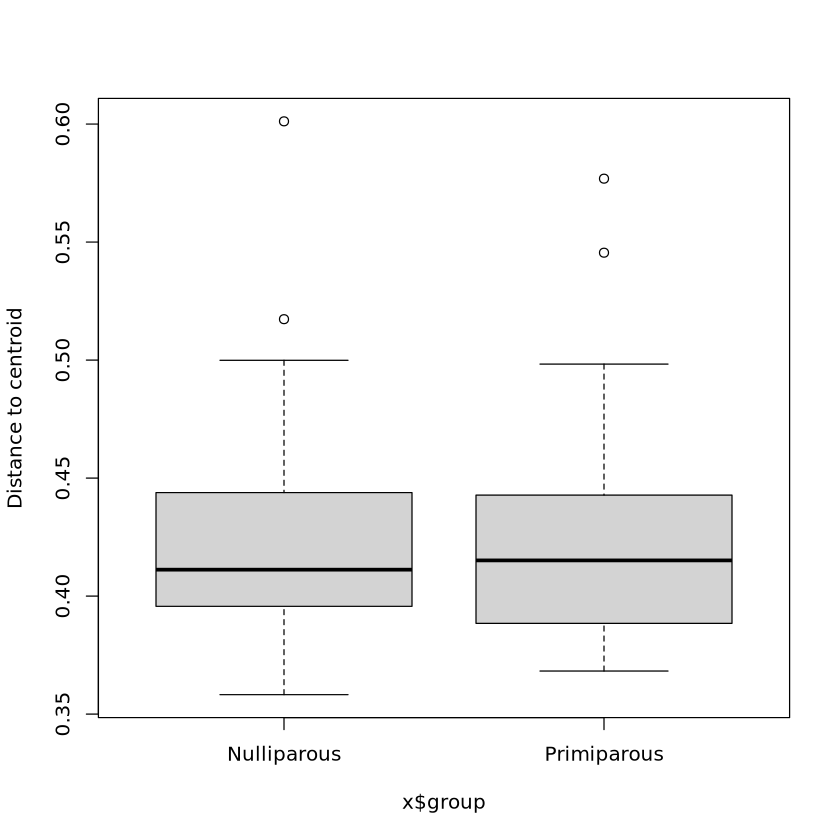

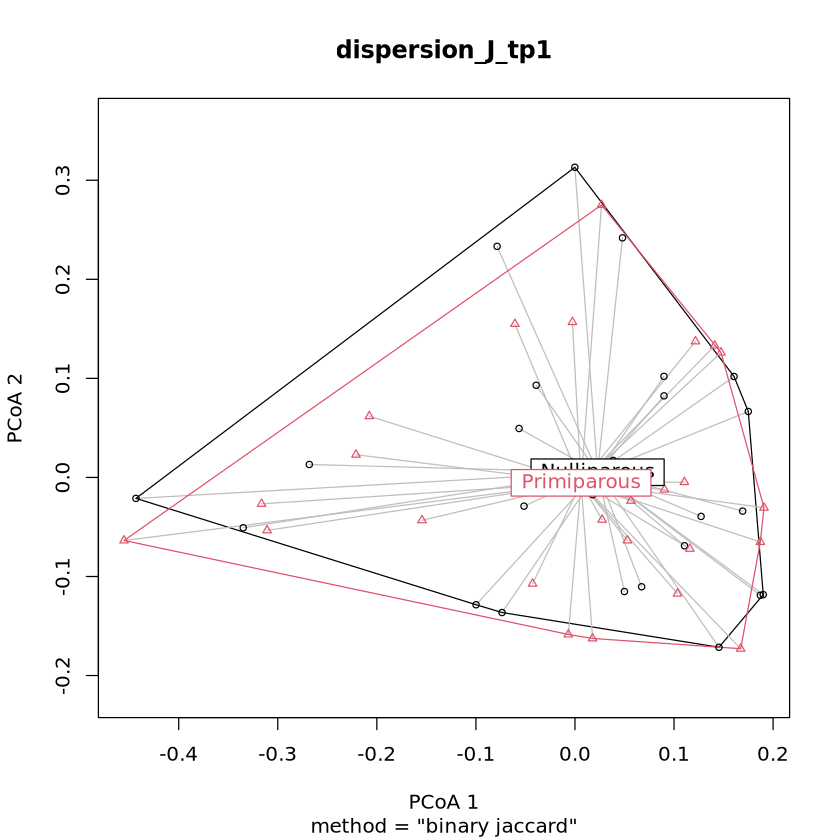

In [163]:
boxplot(dispersion_J_tp1 )
plot(dispersion_J_tp1 )

In [38]:
set.seed(123)
dispersion_tp1_At <- vegan::betadisper(dist_ait_tp1 , meta_tp1$Group)
permutest(dispersion_tp1_At)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df  Sum Sq Mean Sq      F N.Perm Pr(>F)
Groups     1   34.16  34.164 0.7277    999  0.413
Residuals 48 2253.44  46.947                     

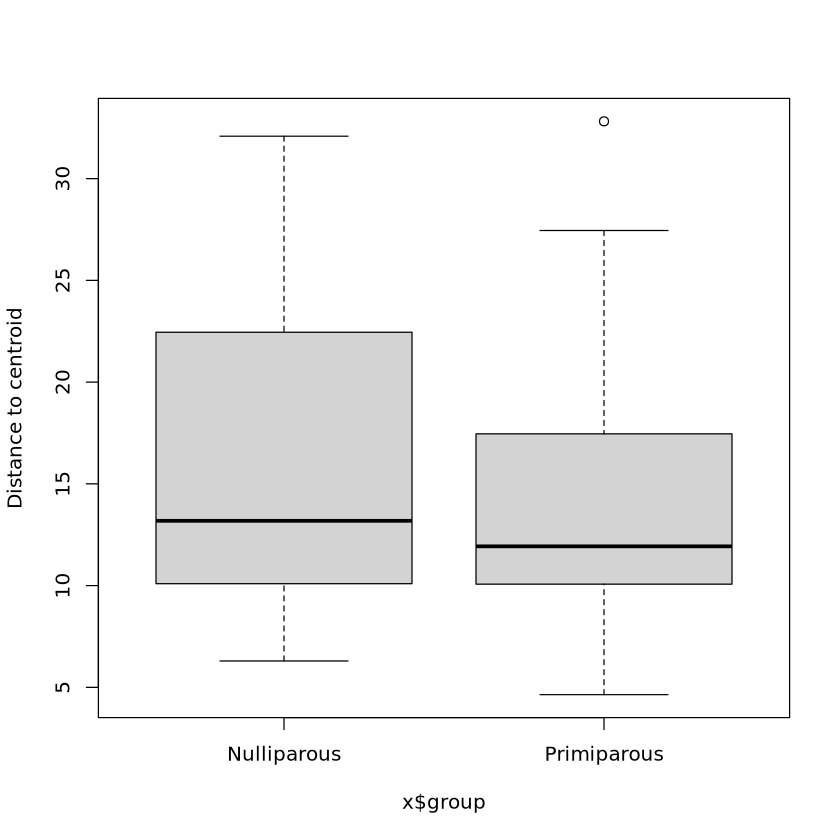

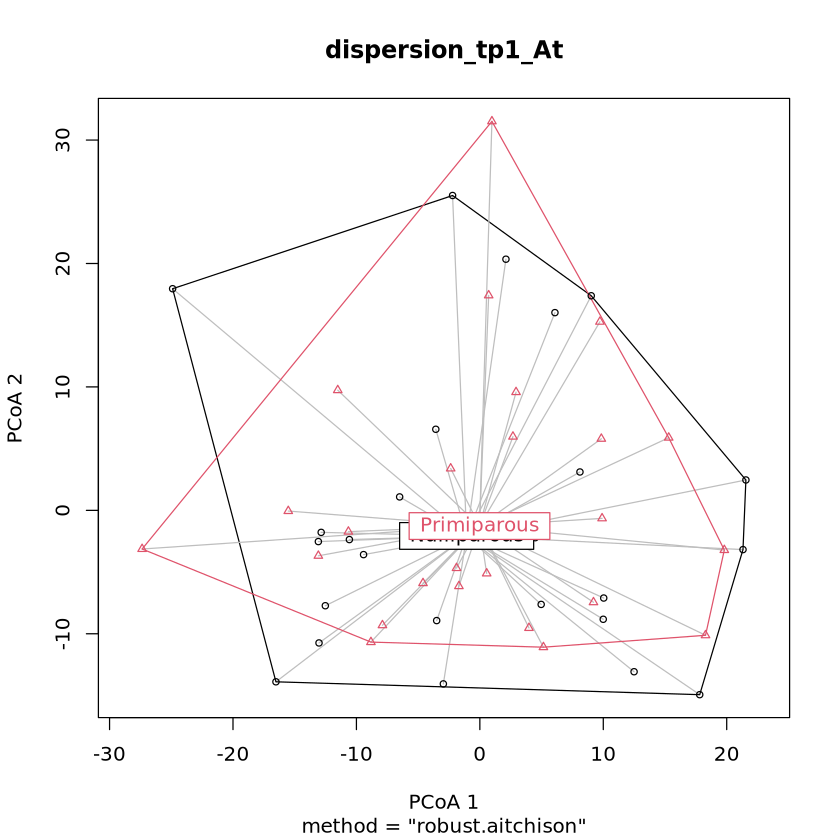

In [165]:
boxplot(dispersion_tp1_At)
plot(dispersion_tp1_At)

In [39]:
set.seed(123)
dispersion_tp1_BC <- vegan::betadisper(dist_bc_tp1, meta_tp1$Group)
permutest(dispersion_tp1_BC )


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq   Mean Sq      F N.Perm Pr(>F)
Groups     1 0.008022 0.0080216 2.6794    999  0.122
Residuals 48 0.143702 0.0029938                     

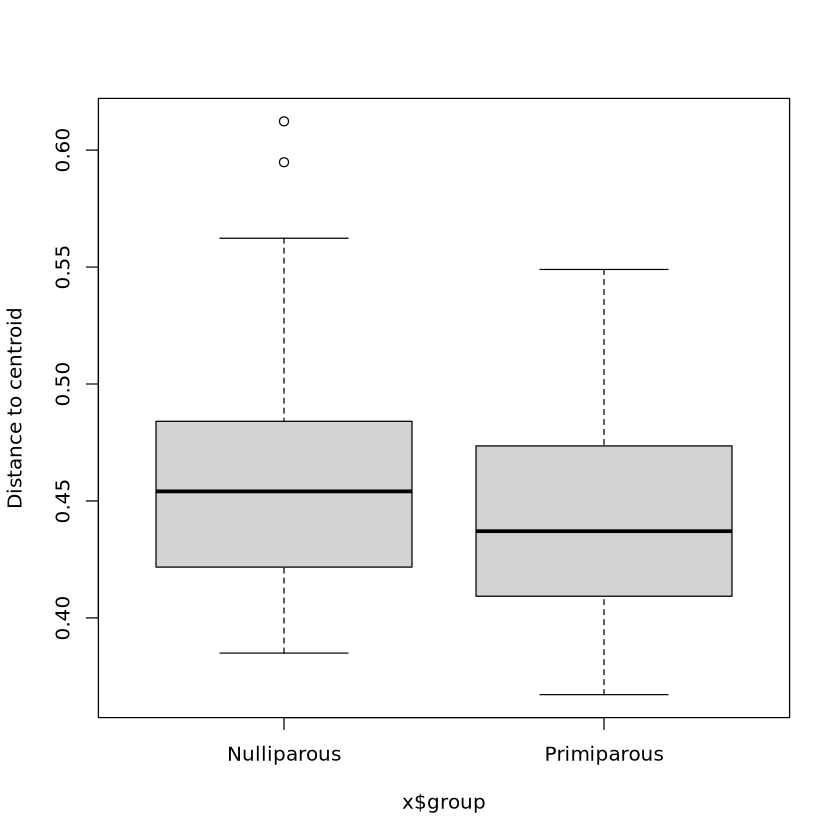

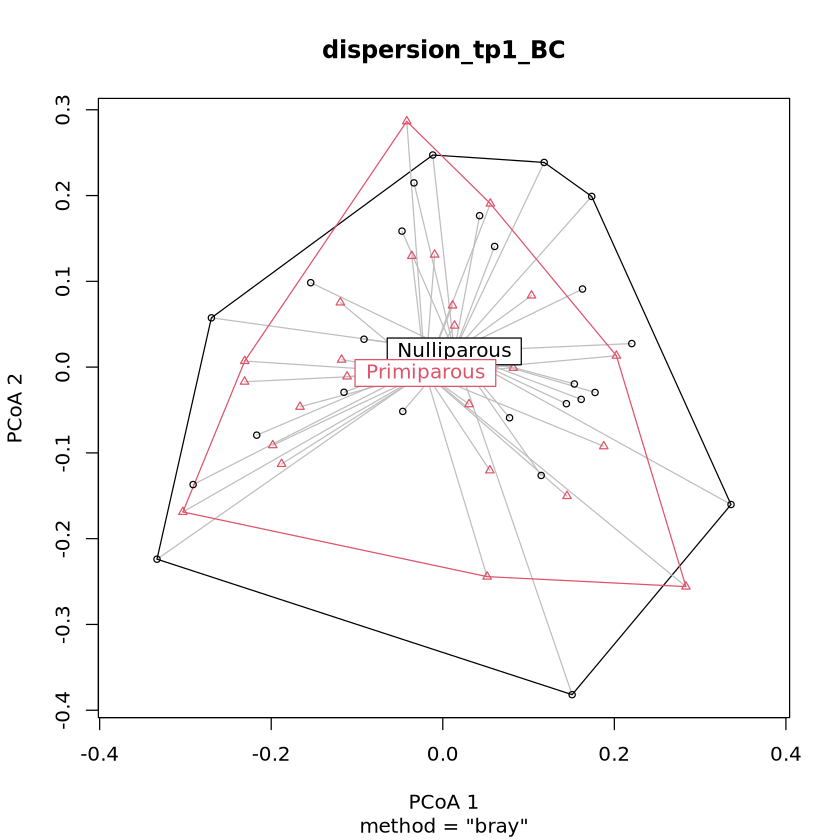

In [167]:
boxplot(dispersion_tp1_BC)
plot(dispersion_tp1_BC)

In [40]:
set.seed(123)
dispersion_J_tp2 <- vegan::betadisper(dist_jac_tp2, meta_tp2$Group)
permutest(dispersion_J_tp2)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq   Mean Sq      F N.Perm Pr(>F)
Groups     1 0.001662 0.0016619 0.4855    999  0.481
Residuals 40 0.136930 0.0034232                     

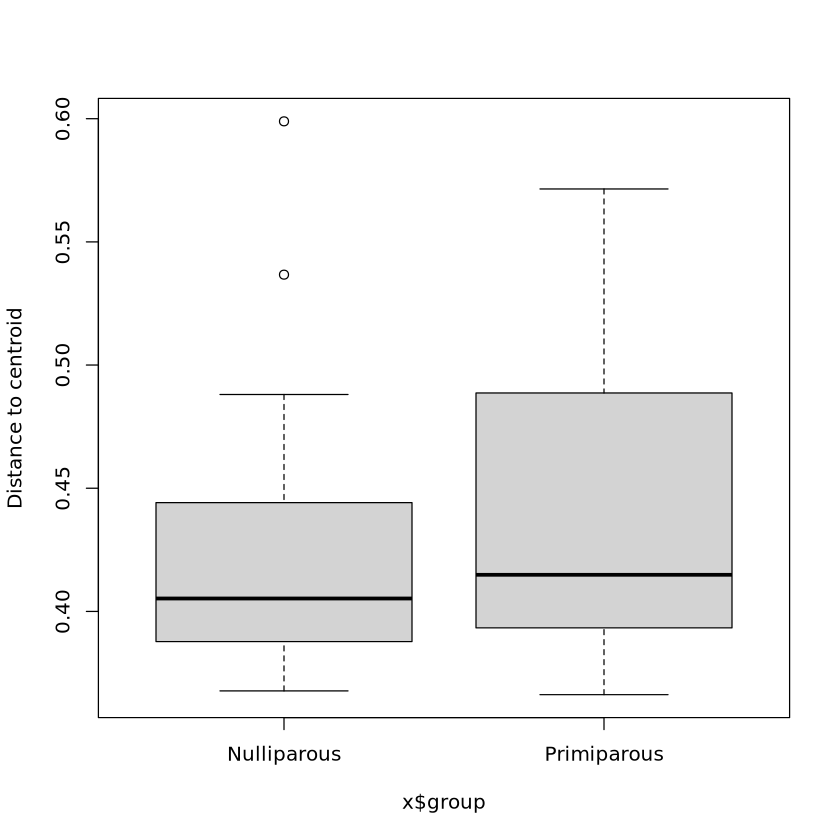

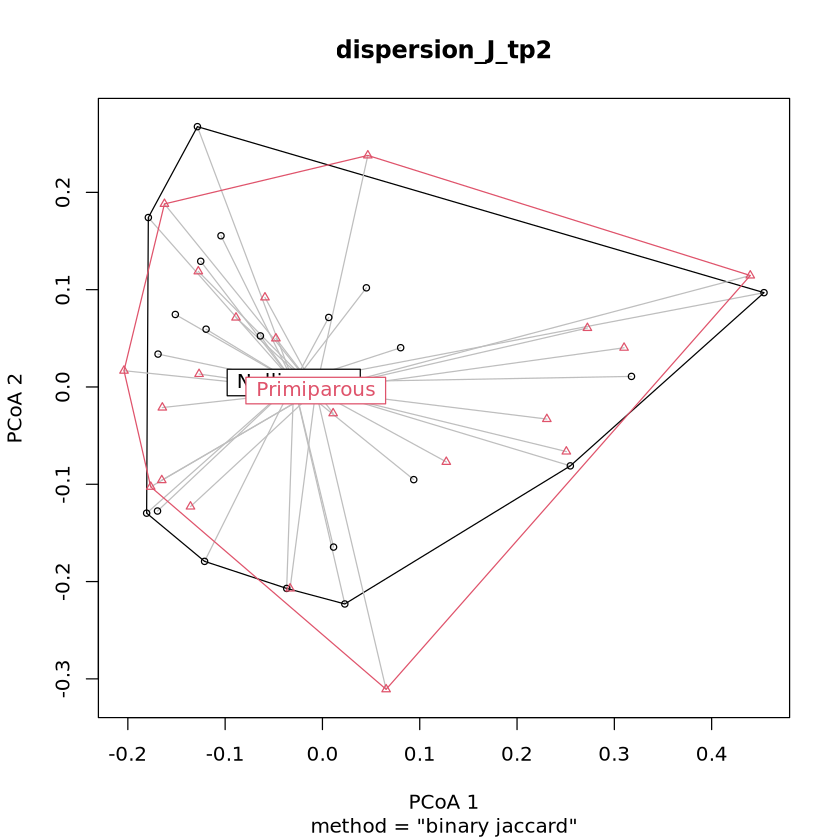

In [175]:
boxplot(dispersion_J_tp2)
plot(dispersion_J_tp2)

In [41]:
set.seed(123)
dispersion_tp2_At <- vegan::betadisper(dist_ait_tp2 , meta_tp2$Group)
permutest(dispersion_tp2_At)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df  Sum Sq Mean Sq      F N.Perm Pr(>F)
Groups     1    1.04   1.040 0.0207    999  0.869
Residuals 40 2014.68  50.367                     

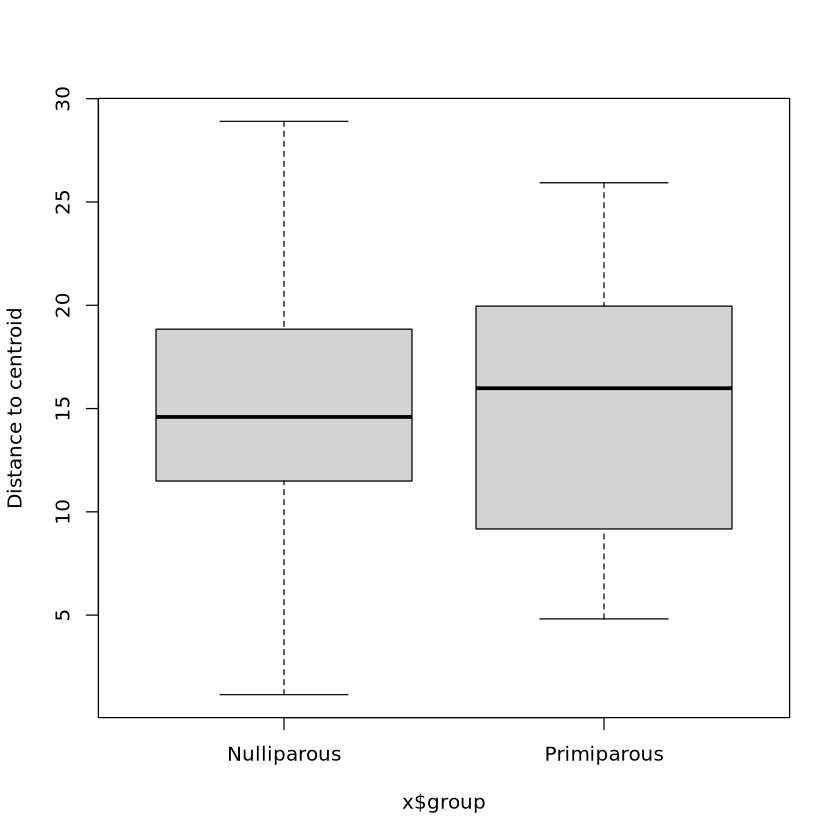

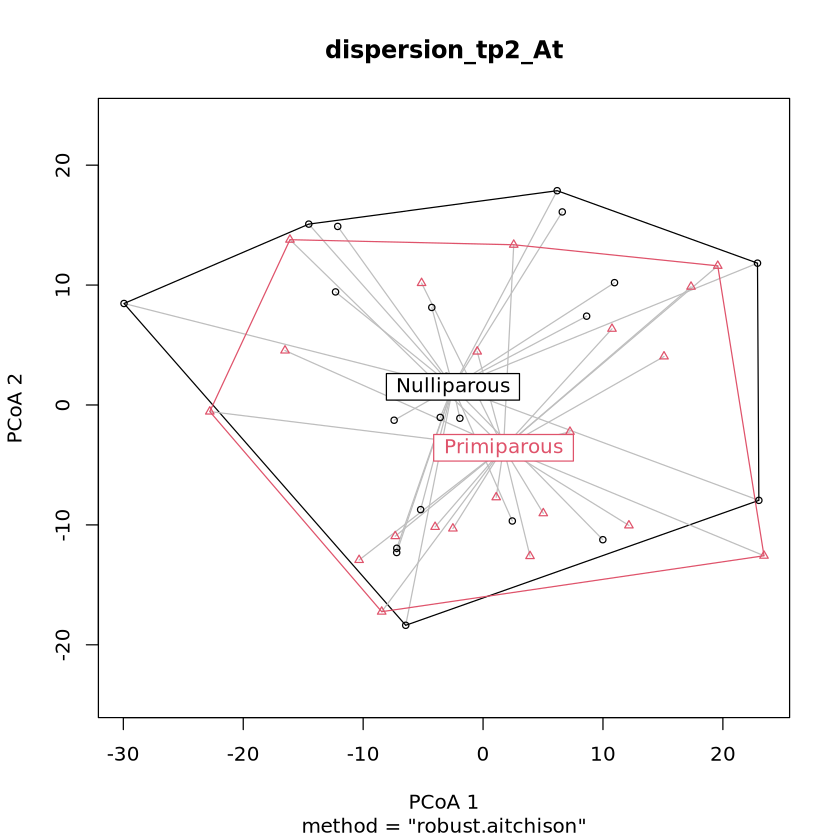

In [177]:
boxplot(dispersion_tp2_At)
plot(dispersion_tp2_At)

In [42]:
set.seed(123)
dispersion_tp2_BC <- vegan::betadisper(dist_bc_tp2, meta_tp2$Group)
permutest(dispersion_tp2_BC )


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq   Mean Sq      F N.Perm Pr(>F)
Groups     1 0.000372 0.0003724 0.0946    999  0.769
Residuals 40 0.157481 0.0039370                     

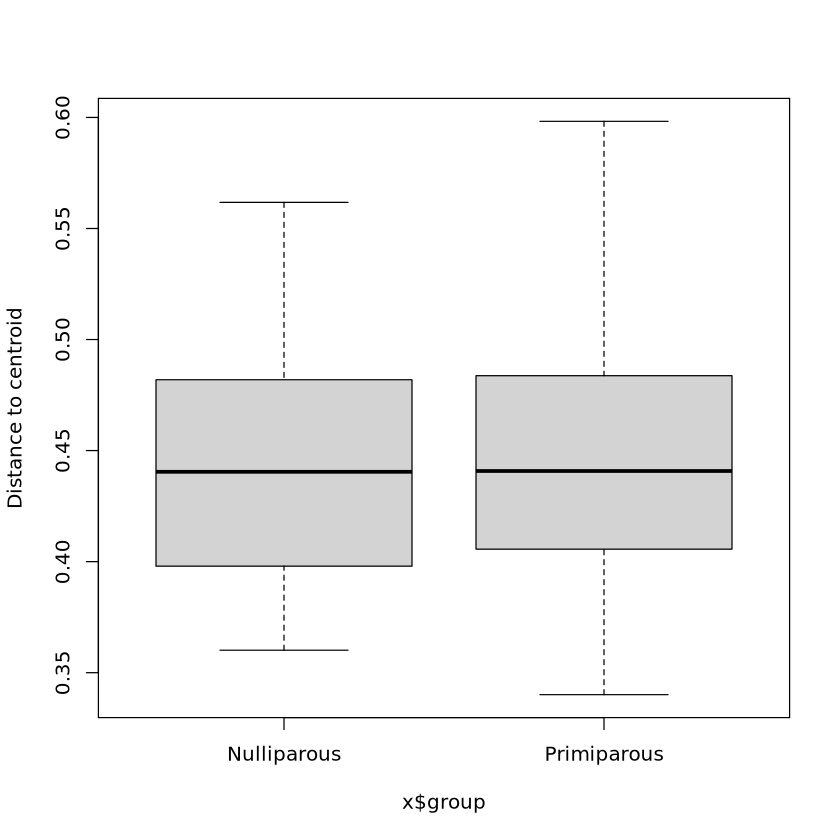

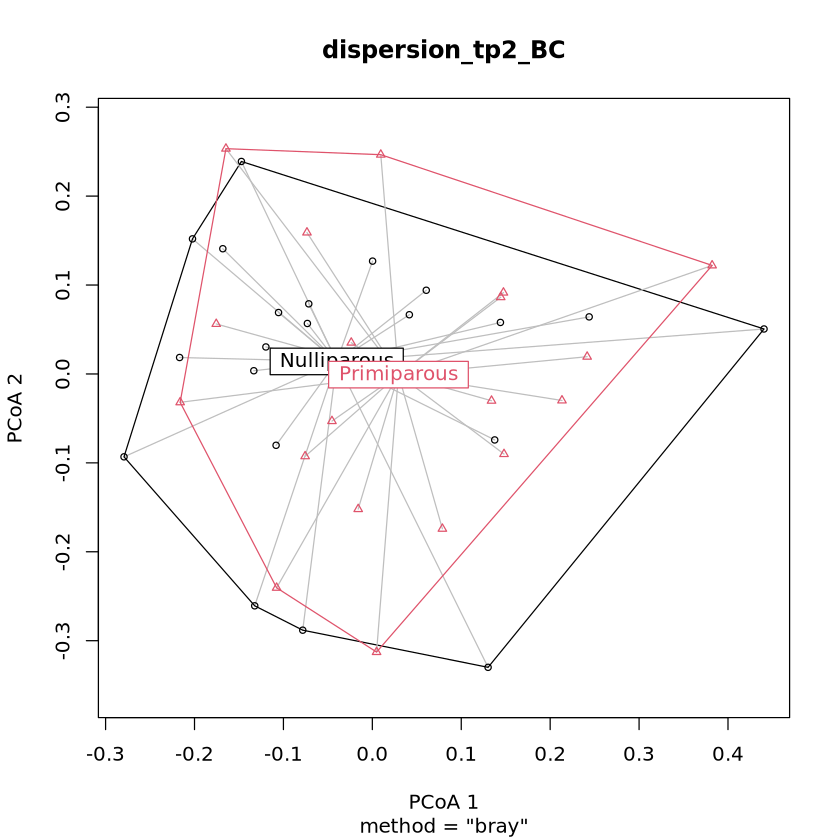

In [180]:
boxplot(dispersion_tp2_BC)
plot(dispersion_tp2_BC)

### 6.3 PERMANOVA — nulliparous vs primiparous at TP1

In [58]:
ctrl_tp1 <- how(plots  = Plots(strata = meta_tp1$Q1_Personnummer, type = "none"),
                within = Within(type = "free"), nperm = 999)



In [59]:
set.seed(1234)
tp1_adonis_J <- adonis2(dist_jac_tp1 ~ Q1_Personnummer + Group, data = meta_tp1,
        permutations = ctrl_tp1, by = "terms")
tp1_adonis_J 
r2_j_tp1 <- tp1_adonis_J["Group", "R2"]
p_j_tp1  <- tp1_adonis_J["Group", "Pr(>F)"]
r2_j_tp1
p_j_tp1 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,24,7.36520173,0.793226433,4.002442,0.331
Group,1,0.07974016,0.008587952,1.039989,0.331
Residual,24,1.84017700,0.198185615,NA,NA
Total,49,9.28511888,1.000000000,NA,NA


[1] 0.008587952

[1] 0.331

In [60]:
set.seed(1234)
tp1_adonis_AT <- adonis2(dist_ait_tp1  ~ Q1_Personnummer + Group, data = meta_tp1,
        permutations = ctrl_tp1, by = "terms")
tp1_adonis_AT 
r2_AT_tp1 <- tp1_adonis_AT["Group", "R2"]
p_AT_tp1  <- tp1_adonis_AT["Group", "Pr(>F)"]
r2_AT_tp1
p_AT_tp1 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,24,11746.66852,0.8967485297,8.769933,0.851
Group,1,13.08434,0.0009988672,0.234447,0.851
Residual,24,1339.42504,0.1022526031,NA,NA
Total,49,13099.17790,1.0000000000,NA,NA


[1] 0.0009988672

[1] 0.851

In [61]:
set.seed(1234)
tp1_adonis_BC <- adonis2(dist_bc_tp1 ~ Q1_Personnummer + Group, data = meta_tp1,
        permutations = ctrl_tp1, by = "terms")
tp1_adonis_BC
r2_BC_tp1 <- tp1_adonis_BC["Group", "R2"]
p_BC_tp1  <- tp1_adonis_BC["Group", "Pr(>F)"]
r2_BC_tp1
p_BC_tp1 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,24,7.5828703,0.71671228,2.644679,0.318
Group,1,0.1299875,0.01228607,1.088058,0.318
Residual,24,2.8672181,0.27100166,NA,NA
Total,49,10.5800759,1.00000000,NA,NA


[1] 0.01228607

[1] 0.318

### 6.4 PERMANOVA — nulliparous vs primiparous at TP2

In [198]:
ctrl_tp2 <- how(plots  = Plots(strata = meta_tp2$Q1_Personnummer, type = "none"),
                within = Within(type = "free"), nperm = 999)



In [199]:
set.seed(1234)
 tp2_adonis_J <- adonis2(dist_jac_tp2 ~ Q1_Personnummer + Group, data = meta_tp2,
        permutations = ctrl_tp2, by = "terms")

r2_j_tp2 <- tp2_adonis_J["Group", "R2"]
p_j_tp2  <- tp2_adonis_J["Group", "Pr(>F)"]
 tp2_adonis_J
r2_j_tp2
p_j_tp2 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,20,6.58867642,0.816802096,4.6615554,0.71
Group,1,0.06434565,0.007976969,0.9105041,0.71
Residual,20,1.41340730,0.175220935,NA,NA
Total,41,8.06642937,1.000000000,NA,NA


[1] 0.007976969

[1] 0.71

In [200]:
set.seed(1234)
tp2_adonis_AT <- adonis2(dist_ait_tp2  ~ Q1_Personnummer + Group, data = meta_tp2,
        permutations = ctrl_tp2, by = "terms")

r2_AT_tp2 <- tp2_adonis_AT["Group", "R2"]
p_AT_tp2  <- tp2_adonis_AT["Group", "Pr(>F)"]
tp2_adonis_AT
r2_AT_tp2
p_AT_tp2 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,20,9455.1255,0.80280183,4.449857,0.142
Group,1,197.7172,0.01678748,1.861029,0.142
Residual,20,2124.8154,0.18041069,NA,NA
Total,41,11777.6581,1.00000000,NA,NA


[1] 0.01678748

[1] 0.142

In [201]:
set.seed(1234)
tp2_adonis_BC <- adonis2(dist_bc_tp2 ~ Q1_Personnummer + Group, data = meta_tp2,
        permutations = ctrl_tp2, by = "terms")
r2_BC_tp2 <- tp2_adonis_BC["Group", "R2"]
p_BC_tp2  <- tp2_adonis_BC["Group", "Pr(>F)"]
tp2_adonis_BC
r2_BC_tp2
p_BC_tp2 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,20,6.5411959,0.74143852,3.101805,0.019
Group,1,0.1722725,0.01952693,1.633816,0.019
Residual,20,2.1088355,0.23903456,NA,NA
Total,41,8.8223038,1.00000000,NA,NA


[1] 0.01952693

[1] 0.019

## 7. Compositional change from TP1 to TP2

In [258]:
filt_meta_tp1 <- meta_tp1 %>% filter(Q1_Personnummer %in% meta_tp2$Q1_Personnummer)
dim(filt_meta_tp1 )
head(filt_meta_tp1 )

[1] 42  5

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>
100000128343,S194e21b,P159f9c8,100000128343,Nulliparous,TP1
100000158999,S1a267fa,P1a267fa,100000158999,Nulliparous,TP1
100000103241,S1f862a6,P1f862a6,100000103241,Nulliparous,TP1
100000157404,S2b86cc0,P3cac7b0,100000157404,Nulliparous,TP1
100000108109,S39fe1d7,P3db7da6,100000108109,Nulliparous,TP1
100000101155,S7e4a963,P424fd61,100000101155,Nulliparous,TP1


In [259]:


taxa_tab_tp1_delta <- taxa_tab_tp1[,colnames(taxa_tab_tp1) %in% rownames(filt_meta_tp1)]
head(taxa_tab_tp1_delta )

,100000115046,100000133514,100000138427,100000416914,100000416341,100000116982,100000117590,100000126486,100000114162,100000108109,⋯,100000404683,100000410189,100000180006,100000410554,100000422410,100000424421,100000167687,100000422946,100000165058,100000419175
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Coprococcus eutactus,1.92768,0.15521,0.05160,0.02486,6.62230,0.00000,0.42317,0.00000,0.00000,0.00000,⋯,0.16779,2.72513,0.00000,0.93544,0.00000,4.42402,0.00000,4.46554,0.00000,0.00000
Faecalibacterium prausnitzii,3.20883,4.32581,4.53698,3.39437,3.26358,4.33970,0.19672,0.01837,7.51137,3.50037,⋯,2.84157,3.24886,5.24076,1.91233,6.89058,7.44669,2.90277,6.99612,6.78398,7.72660
Ruminococcus bromii,12.75072,0.84583,5.68254,2.92580,0.00044,1.35757,8.26843,17.42771,7.18371,7.60447,⋯,4.74826,12.33869,7.39686,0.00842,0.00135,1.89198,7.79235,0.00361,13.89218,0.00000
Ruminococcus bicirculans,0.64417,0.04445,2.55341,0.11893,0.09988,4.66429,0.70478,0.00000,3.43167,3.15675,⋯,0.19760,0.28484,0.00000,0.01427,0.10956,1.09689,0.10850,3.50633,0.00000,0.00000
Eubacterium rectale,0.95028,1.20350,5.57078,0.13382,2.26475,2.51539,0.09724,14.00771,9.53995,0.75065,⋯,0.12479,3.22173,1.25968,0.10241,4.25136,1.03758,21.90512,0.20310,2.13466,8.66076
Phocaeicola vulgatus,1.31137,1.54361,0.37413,0.28747,0.96566,0.00000,2.93263,5.87496,3.58501,3.66160,⋯,2.52242,2.21001,5.07246,3.08527,2.57127,1.68231,0.00026,3.65610,4.75778,4.36198


In [260]:
delta_all_taxa <-
  taxa_tab_tp1_delta %>%
  rownames_to_column("Species") %>%
  full_join(
    taxa_tab_tp2 %>% rownames_to_column("Species"),
    by = "Species"
  ) %>%
  column_to_rownames("Species")

delta_all_taxa[is.na(delta_all_taxa)] <- 0
dim(delta_all_taxa)

[1] 984  84

In [261]:
head(delta_all_taxa)

,100000115046,100000133514,100000138427,100000416914,100000416341,100000116982,100000117590,100000126486,100000114162,100000108109,⋯,100000426050,100000433645,100000106303,100000106341,100000103470,100000106136,100000108482,100000157503,100000148082,100000148693
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Coprococcus eutactus,1.92768,0.15521,0.05160,0.02486,6.62230,0.00000,0.42317,0.00000,0.00000,0.00000,⋯,2.55429,0.11716,0.00000,0.04897,0.00000,0.09931,1.73453,0.11897,0.97567,0.00000
Faecalibacterium prausnitzii,3.20883,4.32581,4.53698,3.39437,3.26358,4.33970,0.19672,0.01837,7.51137,3.50037,⋯,7.62246,1.80675,9.17951,0.89253,0.87042,0.82008,4.85611,7.37675,4.02013,0.10691
Ruminococcus bromii,12.75072,0.84583,5.68254,2.92580,0.00044,1.35757,8.26843,17.42771,7.18371,7.60447,⋯,1.08793,3.43820,16.08984,0.00003,5.19552,0.00300,0.12595,8.01588,2.68541,9.84294
Ruminococcus bicirculans,0.64417,0.04445,2.55341,0.11893,0.09988,4.66429,0.70478,0.00000,3.43167,3.15675,⋯,0.21098,0.07484,1.15836,0.03441,0.00000,0.06032,0.19898,2.36575,0.08132,0.00000
Eubacterium rectale,0.95028,1.20350,5.57078,0.13382,2.26475,2.51539,0.09724,14.00771,9.53995,0.75065,⋯,4.34366,6.92718,3.43674,0.70261,2.03968,3.08540,2.24303,3.53821,0.90551,23.43773
Phocaeicola vulgatus,1.31137,1.54361,0.37413,0.28747,0.96566,0.00000,2.93263,5.87496,3.58501,3.66160,⋯,0.75686,0.09220,3.38202,0.75360,6.61693,0.32515,0.91304,0.30660,0.46497,6.38991


In [262]:
delta_all_taxa_1 <- as.data.frame(t(delta_all_taxa))
class(delta_all_taxa_1)
head(delta_all_taxa_1)

[1] "data.frame"

,Coprococcus eutactus,Faecalibacterium prausnitzii,Ruminococcus bromii,Ruminococcus bicirculans,Eubacterium rectale,Phocaeicola vulgatus,Candidatus Cibionibacter_quicibialis,Lachnospira pectinoschiza,Clostridium sp_AF34_10BH,Catenibacterium SGB4425,⋯,GGB3111 SGB4123,Staphylococcus aureus,GGB9522 SGB98319,Candidatus Alangreenwoodia_gallinarii,GGB4723 SGB6540,GGB28474 SGB41058,GGB6123 SGB8767,GGB9060 SGB13977,Oscillospiraceae unclassified_SGB15252,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100000115046,1.92768,3.20883,12.75072,0.64417,0.95028,1.31137,1.09072,0.27629,2.24122,0.00000,⋯,0,0,0.00000,0,0,0.00000,0,0,0,2.36071
100000133514,0.15521,4.32581,0.84583,0.04445,1.20350,1.54361,4.83623,0.00000,0.05056,0.00000,⋯,0,0,0.00000,0,0,0.00000,0,0,0,4.74968
100000138427,0.05160,4.53698,5.68254,2.55341,5.57078,0.37413,0.25773,0.37810,0.00317,0.00000,⋯,0,0,0.00000,0,0,0.00000,0,0,0,2.96481
100000416914,0.02486,3.39437,2.92580,0.11893,0.13382,0.28747,7.79970,0.08632,0.03749,0.13595,⋯,0,0,0.01279,0,0,0.00532,0,0,0,0.07106
100000416341,6.62230,3.26358,0.00044,0.09988,2.26475,0.96566,0.68823,0.03252,0.17014,0.00000,⋯,0,0,0.00766,0,0,0.00000,0,0,0,2.25795
100000116982,0.00000,4.33970,1.35757,4.66429,2.51539,0.00000,0.23508,0.53207,0.41498,0.00000,⋯,0,0,0.00000,0,0,0.00000,0,0,0,2.60627


In [263]:
delta_meta <- bind_rows(filt_meta_tp1, meta_tp2)
head(delta_meta )

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>
100000128343,S194e21b,P159f9c8,100000128343,Nulliparous,TP1
100000158999,S1a267fa,P1a267fa,100000158999,Nulliparous,TP1
100000103241,S1f862a6,P1f862a6,100000103241,Nulliparous,TP1
100000157404,S2b86cc0,P3cac7b0,100000157404,Nulliparous,TP1
100000108109,S39fe1d7,P3db7da6,100000108109,Nulliparous,TP1
100000101155,S7e4a963,P424fd61,100000101155,Nulliparous,TP1


In [264]:
delta_all_taxa_2 <- delta_all_taxa_1[rownames(delta_meta), ]
head(delta_all_taxa_2)

,Coprococcus eutactus,Faecalibacterium prausnitzii,Ruminococcus bromii,Ruminococcus bicirculans,Eubacterium rectale,Phocaeicola vulgatus,Candidatus Cibionibacter_quicibialis,Lachnospira pectinoschiza,Clostridium sp_AF34_10BH,Catenibacterium SGB4425,⋯,GGB3111 SGB4123,Staphylococcus aureus,GGB9522 SGB98319,Candidatus Alangreenwoodia_gallinarii,GGB4723 SGB6540,GGB28474 SGB41058,GGB6123 SGB8767,GGB9060 SGB13977,Oscillospiraceae unclassified_SGB15252,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100000128343,0.59547,6.82400,1.38387,0.00654,0.46567,0.25955,1.49173,0.00504,0.00789,0,⋯,0.00000,0,0,0,0,0.00000,0,0,0,6.16479
100000158999,6.72788,7.04024,3.76092,0.13935,7.38137,3.14812,0.20532,0.00000,3.49831,0,⋯,0.00000,0,0,0,0,0.00000,0,0,0,1.37777
100000103241,0.03544,2.66174,0.00155,1.77788,1.37398,0.14914,0.95643,0.16198,0.00491,0,⋯,0.21458,0,0,0,0,0.00000,0,0,0,8.35886
100000157404,1.70440,8.60404,5.88083,3.50807,10.22686,0.53735,0.78280,0.00000,0.05273,0,⋯,0.00000,0,0,0,0,0.00000,0,0,0,0.21623
100000108109,0.00000,3.50037,7.60447,3.15675,0.75065,3.66160,0.44790,0.63021,0.33543,0,⋯,0.00000,0,0,0,0,0.00176,0,0,0,4.57193
100000101155,1.45919,0.45560,0.00081,0.14822,0.97807,0.43779,1.80356,0.02909,0.03630,0,⋯,0.00000,0,0,0,0,0.00000,0,0,0,0.39470


In [265]:
all(rownames(delta_all_taxa_2) == rownames(delta_meta))

[1] TRUE

In [266]:
delta_dist_bc <- vegdist(delta_all_taxa_2, method = "bray")
delta_dist_jac <- vegdist(delta_all_taxa_2, method = "jaccard", binary = TRUE)
delta_dist_ait <- vegdist(delta_all_taxa_2, method = "robust.aitchison")

In [267]:
ctrl_all <- how(plots  = Plots(strata = delta_meta$Q1_Personnummer, type = "none"),
                within = Within(type = "free"), nperm = 999)


In [268]:
set.seed(1234)
adonis_within_bc <- adonis2(delta_dist_bc ~ Group * Time_point, data = delta_meta,
        permutations = ctrl_all, by = "terms")
adonis_within_bc 

r2_bc <- adonis_within_bc["Group:Time_point", "R2"]
p_bc  <- adonis_within_bc["Group:Time_point", "Pr(>F)"]
r2_bc 
p_bc

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Group,1,0.24659098,0.013768971,1.1277689,0.001
Time_point,1,0.10575578,0.005905116,0.4836676,0.462
Group:Time_point,1,0.06452767,0.003603050,0.2951134,0.963
Residual,80,17.49230502,0.976722863,NA,NA
Total,83,17.90917945,1.000000000,NA,NA


[1] 0.00360305

[1] 0.963

In [269]:
all(labels(delta_dist_bc) == rownames(delta_meta))
table(delta_meta$Q1_Personnummer, delta_meta$Group, delta_meta$Time_point)

[1] TRUE

, ,  = TP1

          
           Nulliparous Primiparous
  P159f9c8           1           1
  P1a267fa           1           1
  P1f862a6           1           1
  P3cac7b0           1           1
  P3db7da6           1           1
  P424fd61           1           1
  P4a05456           1           1
  P4de45e7           1           1
  P5b98b6c           1           1
  P62ea0b2           1           1
  P719b21e           1           1
  P7ece52e           1           1
  P92b4604           1           1
  P97574f9           1           1
  P9cdfd5a           1           1
  Pbe289c8           1           1
  Pc44e366           1           1
  Pc77a35c           1           1
  Pcd2c0d1           1           1
  Pdab1897           1           1
  Pe706703           1           1

, ,  = TP2

          
           Nulliparous Primiparous
  P159f9c8           1           1
  P1a267fa           1           1
  P1f862a6           1           1
  P3cac7b0           1           1
  P3db7d

In [270]:
set.seed(1234)
adonis_within_jac <- adonis2(delta_dist_jac ~ Group * Time_point, data = delta_meta,
        permutations = ctrl_all, by = "terms")
adonis_within_jac 
r2_J <- adonis_within_jac["Group:Time_point", "R2"]
p_J  <- adonis_within_jac["Group:Time_point", "Pr(>F)"]

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Group,1,0.11227663,0.007015938,0.5688777,0.005
Time_point,1,0.06258079,0.003910546,0.3170813,0.508
Group:Time_point,1,0.03901171,0.002437762,0.1976626,0.978
Residual,80,15.78921258,0.986635753,NA,NA
Total,83,16.00308171,1.000000000,NA,NA


In [271]:
set.seed(1234)
adonis_within_At <- adonis2(delta_dist_ait ~ Group * Time_point, data = delta_meta,
        permutations = ctrl_all, by = "terms")
adonis_within_At
r2_AT <- adonis_within_At["Group:Time_point", "R2"]
p_AT  <- adonis_within_At["Group:Time_point", "Pr(>F)"]

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Group,1,113.30385,0.005971563,0.4879382,0.144
Time_point,1,224.38216,0.011825830,0.9662921,0.030
Group:Time_point,1,59.46194,0.003133880,0.2560703,0.406
Residual,80,18576.75600,0.979068728,NA,NA
Total,83,18973.90395,1.000000000,NA,NA


## 8. Differential Abundance

In [33]:
read_depth <- read.csv(file.path(base_path, "Consecutive_preg/Anusha_redo_folder_260728/vagina/data/240625_superset_allswemami.csv"))
head(read_depth)

,project_id,sequencer_id,flowcell_id,lane_id,adapter_id,sample_id,extraction_plate_id,dna_concentration,library_concentration,duplication,fragment_size,reads_post_qc,host_proportion,reads_post_hr,not_sequenced
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,010_SweMaMi,R1100600190018,E100033372,1,13,010_extraction10_pos_ext,Extraction10,4.0385,25.7120,0.0226733,422,3835,88.45,443,
2,010_SweMaMi,R1100600190018,E100033372,1,115,010_extraction10_pos_seq,Extraction10,30.0000,7.4192,0.0242305,425,59430144,0.63,59053867,
3,010_SweMaMi,R1100600190018,E100033371,1,125,010_extraction11_pos_ext,Extraction11,-1.0000,7.2408,0.0409590,477,78186865,0.65,77680170,
4,010_SweMaMi,R1100600190018,E100033371,1,115,010_extraction11_pos_seq,Extraction11,30.0000,9.6370,0.0349191,490,54260749,0.63,53918821,
5,010_SweMaMi,R1100600190018,E100033353,1,84,010_extraction12_pos_ext,Extraction12,2.9796,38.5400,0.0192193,484,69340052,0.53,68972932,
6,010_SweMaMi,R1100600190018,E100033353,1,39,010_extraction12_pos_seq,Extraction12,30.0000,6.5941,0.0179227,482,48073669,0.55,47810555,


In [34]:
head(meta_tp2)

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<dbl>,<chr>,<chr>
100000144381,S194e21b,P159f9c8,100000144381,Nulliparous,TP2
100000172865,S1a267fa,P1a267fa,100000172865,Nulliparous,TP2
100000112243,S1f862a6,P1f862a6,100000112243,Nulliparous,TP2
100000168325,S2b86cc0,P3cac7b0,100000168325,Nulliparous,TP2
100000123362,S39fe1d7,P3db7da6,100000123362,Nulliparous,TP2
100000106341,S7e4a963,P424fd61,100000106341,Nulliparous,TP2


In [38]:
read_depth_1 <- read_depth %>%
  mutate(
    Sample_ID = sub(".*(100000\\d{6}).*", "\\1", sample_id)
  )

head(read_depth_1)

,project_id,sequencer_id,flowcell_id,lane_id,adapter_id,sample_id,extraction_plate_id,dna_concentration,library_concentration,duplication,fragment_size,reads_post_qc,host_proportion,reads_post_hr,not_sequenced,Sample_ID
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
1,010_SweMaMi,R1100600190018,E100033372,1,13,010_extraction10_pos_ext,Extraction10,4.0385,25.7120,0.0226733,422,3835,88.45,443,,010_extraction10_pos_ext
2,010_SweMaMi,R1100600190018,E100033372,1,115,010_extraction10_pos_seq,Extraction10,30.0000,7.4192,0.0242305,425,59430144,0.63,59053867,,010_extraction10_pos_seq
3,010_SweMaMi,R1100600190018,E100033371,1,125,010_extraction11_pos_ext,Extraction11,-1.0000,7.2408,0.0409590,477,78186865,0.65,77680170,,010_extraction11_pos_ext
4,010_SweMaMi,R1100600190018,E100033371,1,115,010_extraction11_pos_seq,Extraction11,30.0000,9.6370,0.0349191,490,54260749,0.63,53918821,,010_extraction11_pos_seq
5,010_SweMaMi,R1100600190018,E100033353,1,84,010_extraction12_pos_ext,Extraction12,2.9796,38.5400,0.0192193,484,69340052,0.53,68972932,,010_extraction12_pos_ext
6,010_SweMaMi,R1100600190018,E100033353,1,39,010_extraction12_pos_seq,Extraction12,30.0000,6.5941,0.0179227,482,48073669,0.55,47810555,,010_extraction12_pos_seq


In [39]:
read_depth_2 <- read_depth_1 %>% filter(Sample_ID %in% rownames(meta_tp2)) %>% 
                                        select(c(Sample_ID, reads_post_hr))

head(read_depth_2)


,Sample_ID,reads_post_hr
,<chr>,<dbl>
1,100000103470,66694794
2,100000106136,52542574
3,100000106303,40577119
4,100000106341,59865388
5,100000108482,71967330
6,100000112243,54936085


In [40]:
read_depth_3 <- read_depth_2 %>% rename(read_depth = reads_post_hr)
head(read_depth_3)
dim(read_depth_3 )

,Sample_ID,read_depth
,<chr>,<dbl>
1,100000103470,66694794
2,100000106136,52542574
3,100000106303,40577119
4,100000106341,59865388
5,100000108482,71967330
6,100000112243,54936085


[1] 45  2

In [41]:
read_depth_4 <- read_depth_3 %>%
  group_by(Sample_ID) %>%
  slice_max(order_by = read_depth, n = 1, with_ties = FALSE) %>%
  ungroup()
dim(read_depth_4)
head(read_depth_4)

[1] 42  2

Sample_ID,read_depth
<chr>,<dbl>
100000103470,66694794
100000106136,52542574
100000106303,40577119
100000106341,59865388
100000108482,71967330
100000112243,54936085


In [42]:
meta_tp2_M <- meta_tp2 %>%
  rownames_to_column(var = "Row.names")

In [45]:
update_meta_tp2 <- full_join(
  meta_tp2_M,
  read_depth_4,
  by = c("Row.names" = "Sample_ID")
)

update_meta_tp2 <- update_meta_tp2 %>%
  column_to_rownames(var = "Row.names")
head(update_meta_tp2)

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point,read_depth
,<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>
100000144381,S194e21b,P159f9c8,100000144381,Nulliparous,TP2,83078532
100000172865,S1a267fa,P1a267fa,100000172865,Nulliparous,TP2,80308726
100000112243,S1f862a6,P1f862a6,100000112243,Nulliparous,TP2,54936085
100000168325,S2b86cc0,P3cac7b0,100000168325,Nulliparous,TP2,90566940
100000123362,S39fe1d7,P3db7da6,100000123362,Nulliparous,TP2,56337600
100000106341,S7e4a963,P424fd61,100000106341,Nulliparous,TP2,59865388


In [46]:
all(rownames(ordered_taxa_tp2) == rownames(update_meta_tp2 ))

[1] TRUE

In [47]:
update_meta_tp2$Group <- factor(update_meta_tp2$Group, levels = c("Nulliparous", "Primiparous"))

In [48]:
DA_TP2 <- file.path(base_path, "Consecutive_preg/Github_version/Gut/data")

In [49]:
tp2_DA <- maaslin3(
  input_data     = ordered_taxa_tp2,
  input_metadata = update_meta_tp2,
  output         = "DA_TP2",
  
  # Group is your primary variable; read_depth is a required technical covariate
  fixed_effects  = c("Group", "read_depth"), 
  # Q1_Personnummer links the paired samples for each woman
  random_effects = c("Q1_Personnummer"),   
  # Baseline for comparison
  reference      = "Group,Nulliparous",
  # Handling the paired design with only 2 samples per person
  small_random_effects = TRUE,
  # Recommended defaults 
  normalization  = "TSS",
  transform      = "LOG",
  median_comparison_abundance = TRUE
)

2026-10-20 13:07:09.795689 INFO::Writing function arguments to log file
2026-10-20 13:07:09.813131 INFO::Verifying options selected are valid
2026-10-20 13:07:09.814305 INFO::Determining format of input files
2026-10-20 13:07:09.814816 INFO::Input format is data samples as rows and metadata samples as rows
2026-10-20 13:07:09.820642 INFO::Formula for random effects: expr ~ (1 | Q1_Personnummer)
2026-10-20 13:07:09.821316 INFO::Formula for fixed effects: expr ~  Group + read_depth
2026-10-20 13:07:09.822254 INFO::Running selected normalization method: TSS
2026-10-20 13:07:09.835119 INFO::Creating output feature tables folder
2026-10-20 13:07:09.836018 INFO::Writing normalized data to file DA_TP2/features/data_norm.tsv
2026-10-20 13:07:09.850627 INFO::Filter data based on min abundance, min prevalence, and max prevalence
2026-10-20 13:07:09.851157 INFO::Total samples in data: 42
2026-10-20 13:07:09.851561 INFO::Min samples required with min abundance for a feature not to be filtered: 0.0

Warning message:
“the ‘findbars’ function has moved to the reformulas package. Please update your imports, or ask an upstream package maintainter to do so.
This warning is displayed once per session.”


2026-10-20 13:07:31.319078 INFO::Fitting model to feature number 2, Acinetobacter SGB65105
2026-10-20 13:07:31.334713 WARNING::Fitting problem for feature 2 returning NA
2026-10-20 13:07:31.33724 INFO::Fitting model to feature number 3, Actinobaculum sp_oral_taxon_183
2026-10-20 13:07:31.357912 WARNING::Fitting problem for feature 3 returning NA
2026-10-20 13:07:31.360962 INFO::Fitting model to feature number 4, Actinomyces bouchesdurhonensis


boundary (singular) fit: see help('isSingular')



2026-10-20 13:07:31.421599 INFO::Fitting model to feature number 5, Actinomyces graevenitzii
2026-10-20 13:07:31.458573 INFO::Fitting model to feature number 6, Actinomyces naeslundii


Feature Actinomyces naeslundii : simpleWarning in as_lmerModLT(model, devfun): Model may not have converged with 1 eigenvalue close to zero: 8.6e-12




... (1,203 outputs left out)

boundary (singular) fit: see help('isSingular')



2026-10-20 13:14:20.540858 INFO::Fitting model to feature number 894, Streptococcus vestibularis
2026-10-20 13:14:20.572202 INFO::Fitting model to feature number 895, Sutterella wadsworthensis
2026-10-20 13:14:20.616816 INFO::Fitting model to feature number 896, Synechococcus SGB14295
2026-10-20 13:14:20.631458 WARNING::Fitting problem for feature 896 returning NA
2026-10-20 13:14:20.63339 INFO::Fitting model to feature number 897, TM7 phylum_sp_oral_taxon_352
2026-10-20 13:14:20.664771 INFO::Fitting model to feature number 898, Traorella massiliensis
2026-10-20 13:14:20.74631 WARNING::Fitting problem for feature 898 returning NA
2026-10-20 13:14:20.748589 INFO::Fitting model to feature number 899, Turicibacter bilis
2026-10-20 13:14:20.779262 INFO::Fitting model to feature number 900, Turicibacter sanguinis
2026-10-20 13:14:20.811555 INFO::Fitting model to feature number 901, Veillonella atypica
2026-10-20 13:14:20.843113 INFO::Fitting model to feature number 902, Veillonella dispar
2

boundary (singular) fit: see help('isSingular')



2026-10-20 13:14:21.000333 INFO::Fitting model to feature number 907, Victivallis lenta
2026-10-20 13:14:21.03184 INFO::Fitting model to feature number 908, Victivallis vadensis
2026-10-20 13:14:21.061944 INFO::Fitting model to feature number 909, Waltera intestinalis
2026-10-20 13:14:21.092559 INFO::Fitting model to feature number 910, Other_taxa
2026-10-20 13:14:21.291731 INFO::Creating fits folder
2026-10-20 13:14:21.292735 INFO::Writing residuals to file DA_TP2/fits/residuals_linear.rds
2026-10-20 13:14:21.301623 INFO::Writing fitted values to file DA_TP2/fits/fitted_linear.rds
2026-10-20 13:14:21.309636 INFO::Writing extracted random effects to file DA_TP2/fits/ranef_linear.rds
2026-10-20 13:14:21.314572 INFO::Writing residuals to file DA_TP2/fits/residuals_logistic.rds
2026-10-20 13:14:21.35653 INFO::Writing fitted values to file DA_TP2/fits/fitted_logistic.rds
2026-10-20 13:14:21.398393 INFO::Writing extracted random effects to file DA_TP2/fits/ranef_logistic.rds
2026-10-20 13:1

## 9. Figures/plots

In [ ]:
#Main Figure: Important results- TP2 alpha results and delta alpha results.


### 9.1 Main figures

In [505]:
shared_theme <- theme(
  axis.title.x = element_text(size = 14, color = "black", face = "bold"),
  axis.text.x  = element_text(size = 12, color = "black"),
  axis.title.y = element_text(size = 14, color = "black", face = "bold"),
  axis.text.y  = element_text(size = 12, color = "black"),
  plot.title   = element_text(size = 14, color = "black", face = "bold"),
  legend.title = element_text(size = 14, color = "black", face = "bold"),
  legend.text  = element_text(size = 12, color = "black")
)

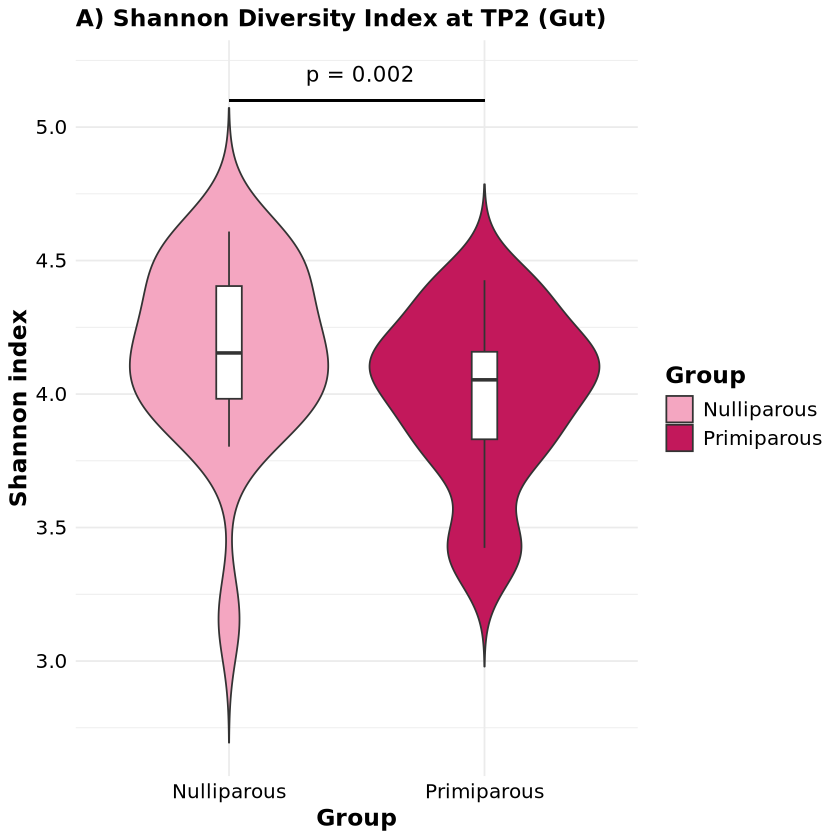

In [506]:
#Shannon diversity Violin plot
my_plot_shan_tp2 <- ggplot(df_shannon_tp2, aes(x = Group, y = Shannon, fill = Group)) +
  geom_violin(trim = FALSE) +
  geom_boxplot(width = 0.1, fill = "white", outlier.shape = NA) +
  scale_fill_manual(values = c("Nulliparous" = "#F4A6C1", "Primiparous" = "#C2185B")) +
  labs(title = "A) Shannon Diversity Index at TP2 (Gut)", x = "Group", y = "Shannon index") +
  theme_minimal() +
  shared_theme

plot_p_shan_tp2 <- my_plot_shan_tp2 +
  annotate("text", x = 1.3, y = 5.2,
           label = paste("p =", round(shan_tp2_p, 3)),
           color = "black", size = 4.5, hjust = 0) +
  geom_segment(aes(x = 1, xend = 2, y = 5.1, yend = 5.1),
               color = "black", size = 0.4)

plot_p_shan_tp2


[1] 0.001971368

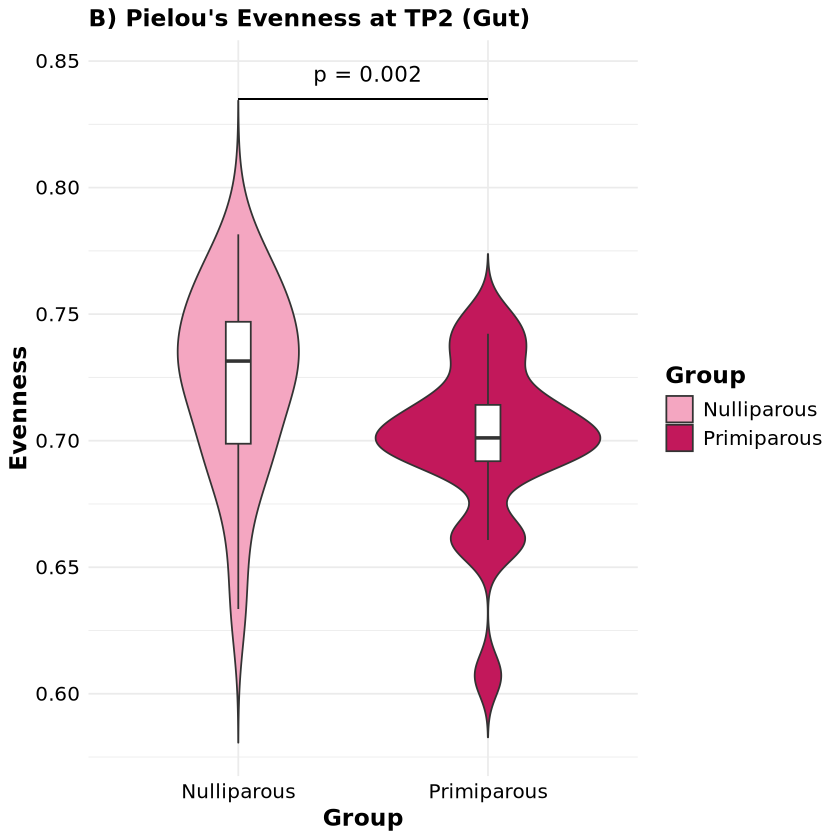

In [507]:
#Evenness Violin plot
my_plot_even_tp2 <- ggplot(df_evenness_tp2, aes(x = Group, y = Evenness, fill = Group)) +
  geom_violin(trim = FALSE) +
  geom_boxplot(width = 0.1, fill = "white", outlier.shape = NA) +
  scale_fill_manual(values = c("Nulliparous" = "#F4A6C1", "Primiparous" = "#C2185B")) +
  labs(title = "B) Pielou's Evenness at TP2 (Gut)", x = "Group", y = "Evenness") +
  theme_minimal() +
  shared_theme

my_plot_even_tp2 <- my_plot_even_tp2 +
  annotate("text", x = 1.30, y = 0.845,
           label = paste("p =", round(evenness_p_tp2, 3)),
           color = "black", size = 4.5, hjust = 0) +
  geom_segment(aes(x = 1, xend = 2, y = 0.835, yend = 0.835),
               color = "black", size = 0.4)

my_plot_even_tp2

In [508]:
plot_even_tp2 <- my_plot_even_tp2
plot_shan_tp2 <- plot_p_shan_tp2

In [509]:
# Reshape wide to long
alpha_long <- alpha_delta %>%
  select(Q1_Personnummer, Group, Shannon_TP1, Shannon_TP2,
        Species_richness_TP1, Species_richness_TP2,
        Evenness_TP1, Evenness_TP2) %>%
  pivot_longer(
    cols = -c(Q1_Personnummer, Group),
    names_to = c(".value", "Time_point"),
    names_pattern = "(.*)_(TP1|TP2)"
  ) %>%
  mutate(pair_id = paste(Q1_Personnummer, Group, sep = "_"))
head(alpha_long)

Q1_Personnummer,Group,Time_point,Shannon,Species_richness,Evenness,pair_id
<chr>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
P719b21e,Nulliparous,TP1,4.517399,406,0.7521035,P719b21e_Nulliparous
P719b21e,Nulliparous,TP2,4.550494,385,0.7643723,P719b21e_Nulliparous
P97574f9,Nulliparous,TP1,4.461396,416,0.7397825,P97574f9_Nulliparous
P97574f9,Nulliparous,TP2,4.153986,390,0.6962594,P97574f9_Nulliparous
P92b4604,Nulliparous,TP1,4.340309,385,0.7290663,P92b4604_Nulliparous
P92b4604,Nulliparous,TP2,4.277826,307,0.7469774,P92b4604_Nulliparous


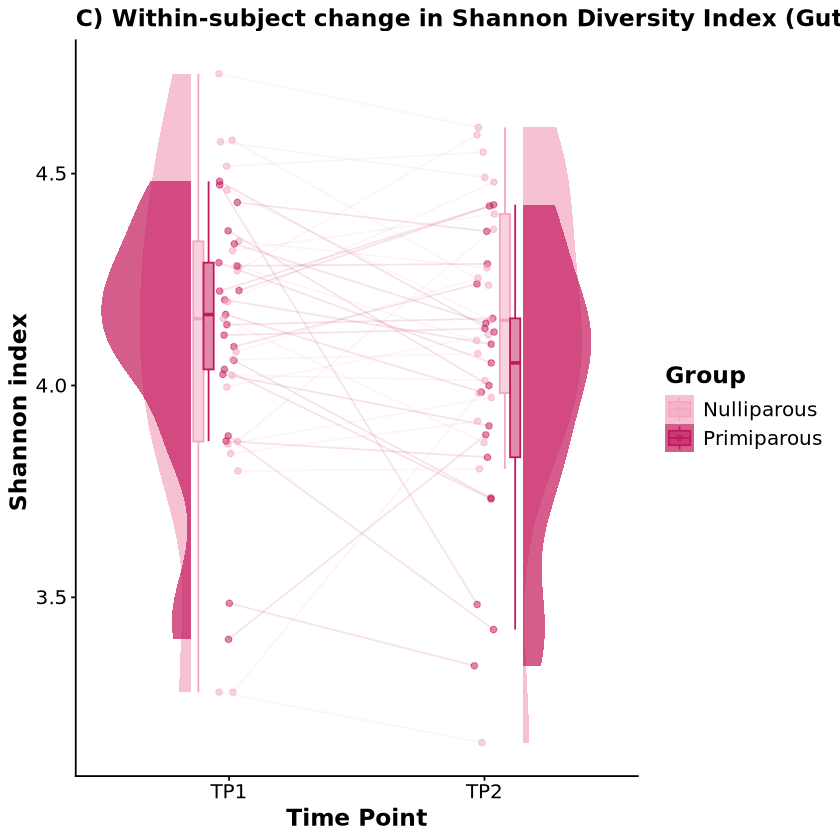

In [510]:
plot_shan <- ggplot(
  alpha_long,
  aes(x = Time_point, y = Shannon, fill = Group, color = Group)) +
  geom_rain(
    alpha = 0.5,
    rain.side = 'f2x2',
    id.long.var = "pair_id",
    violin.args = list(color = NA, alpha = 0.7),
    line.args = list(alpha = 0.12)
  ) +
  theme_classic() +
  scale_fill_manual(values = c("Nulliparous" = "#F4A6C1", "Primiparous" = "#C2185B")) +
  scale_color_manual(values = c("Nulliparous" = "#F4A6C1", "Primiparous" = "#C2185B"), name = "Group") +
  labs(x = "Time Point", y = "Shannon index ", title = "C) Within-subject change in Shannon Diversity Index (Gut)") +
  shared_theme

plot_shan

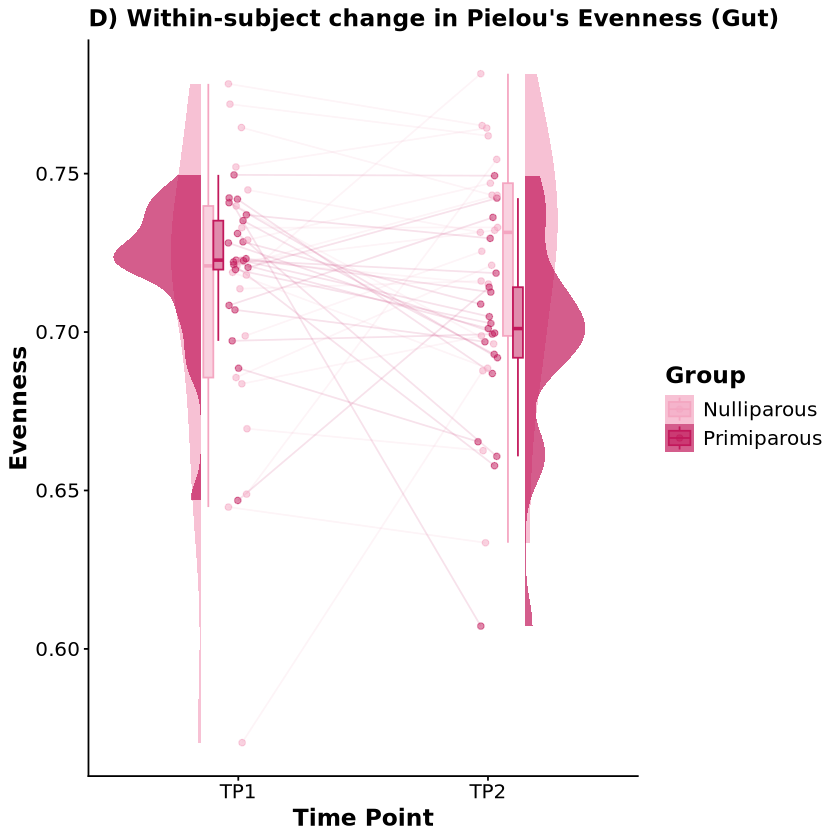

In [511]:
plot_even <- ggplot(
  alpha_long,
  aes(x = Time_point, y = Evenness, fill = Group, color = Group)) +
  geom_rain(
    alpha = 0.5,
    rain.side = 'f2x2',
    id.long.var = "pair_id",
    violin.args = list(color = NA, alpha = 0.7),
    line.args = list(alpha = 0.12)
  ) +
  theme_classic() +
  scale_fill_manual(values = c("Nulliparous" = "#F4A6C1", "Primiparous" = "#C2185B")) +
  scale_color_manual(values = c("Nulliparous" = "#F4A6C1", "Primiparous" = "#C2185B"), name = "Group") +
  labs(x = "Time Point", y = "Evenness", title = "D) Within-subject change in Pielou's Evenness (Gut)") +
  shared_theme

plot_even

In [512]:
add_pvalue_top <- function(plot, p_value, data_col) {
  
  y_top <- max(plot$data[[data_col]], na.rm = TRUE)
  y_range <- diff(range(plot$data[[data_col]], na.rm = TRUE))
  
  plot +
    annotate("segment", x = 1, xend = 2,
             y = y_top + 0.05 * y_range, yend = y_top + 0.05 * y_range,
             color = "black") +
    annotate("text", x = 1.5, y = y_top + 0.09 * y_range,
             label = paste("p =", round(p_value, 3)),
             size = 4.5) +
    coord_cartesian(clip = "off") +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.15)))
}



In [513]:
plot_even <- add_pvalue_top(plot_even, delta_even_p, "Evenness")
plot_shan <- add_pvalue_top(plot_shan, delta_shan_p, "Shannon")

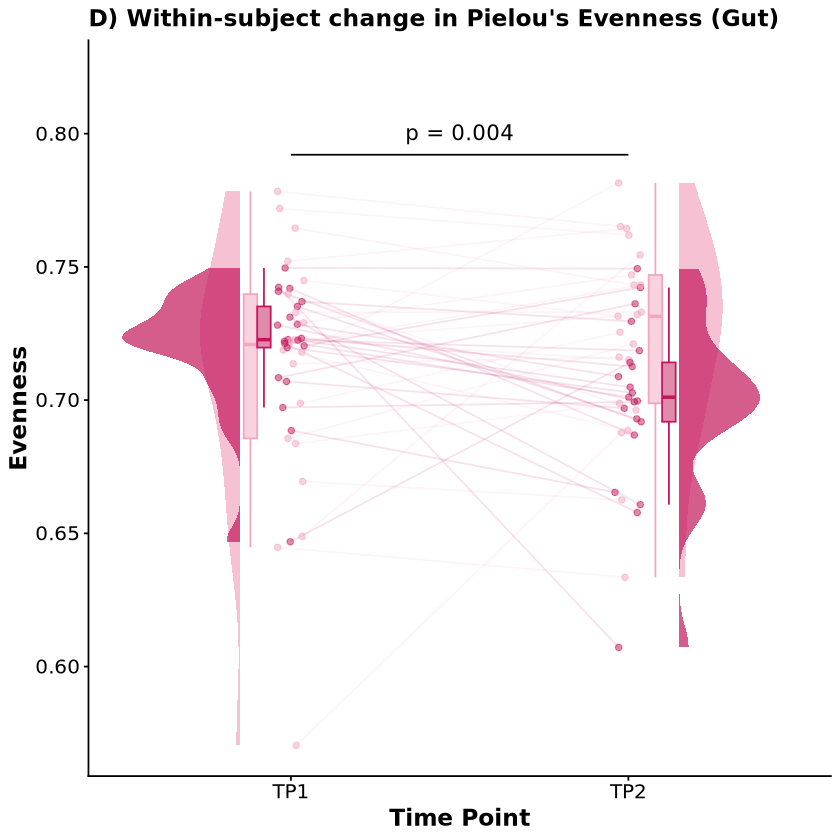

In [514]:
plot_even_nl <- plot_even + theme(legend.position = "none")
plot_even_nl

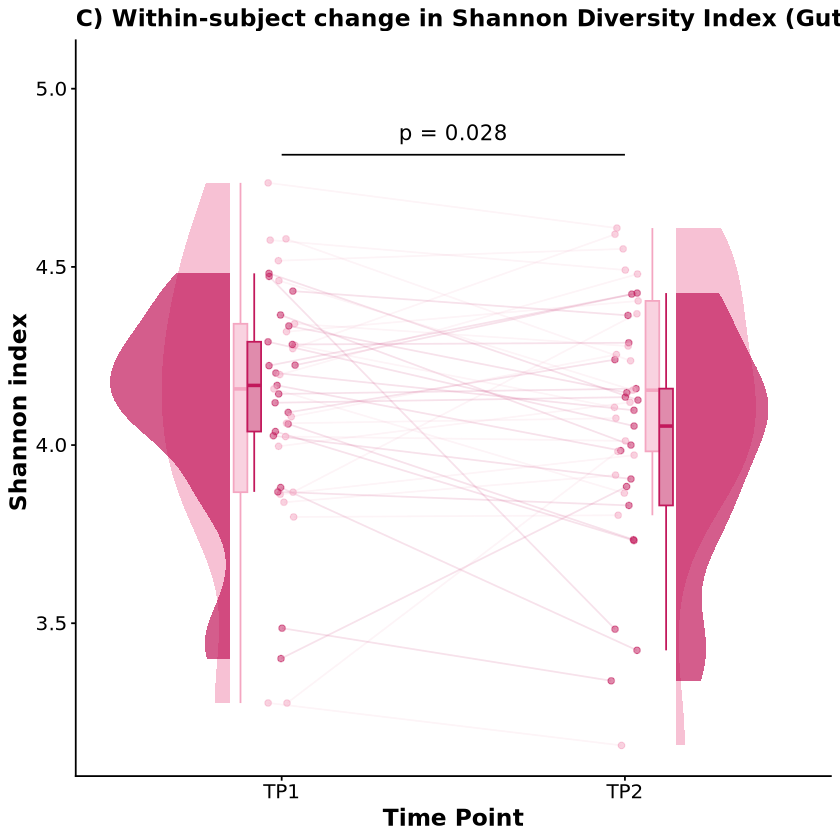

In [515]:
plot_shan_nl <- plot_shan+ theme(legend.position = "none")
plot_shan_nl

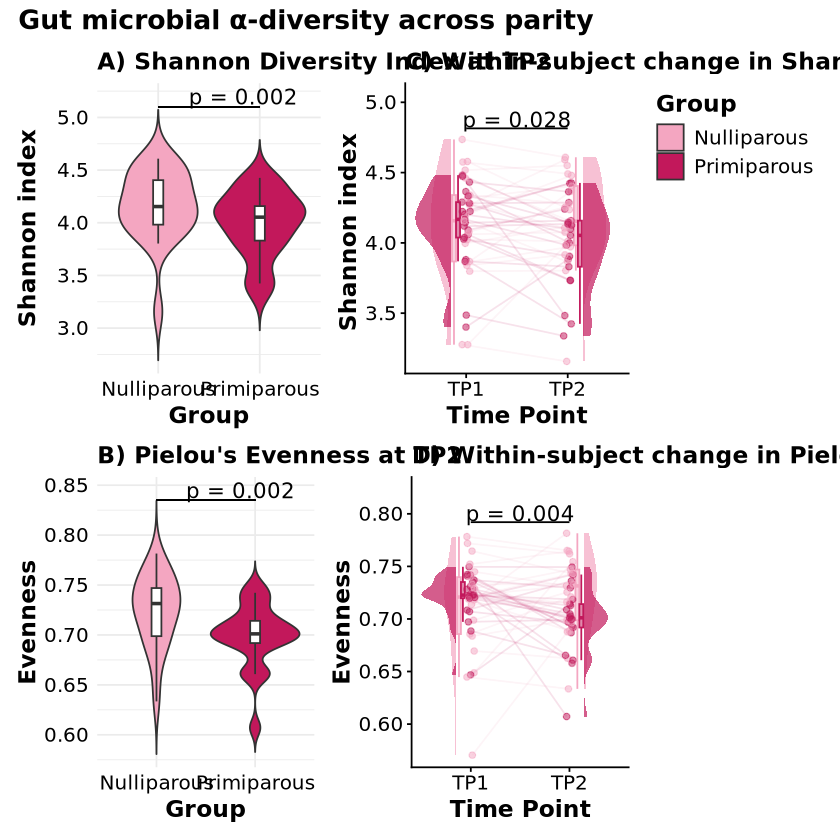

In [176]:
Figure_2 <- (
  (plot_shan_tp2 + plot_shan_nl) /
  (plot_even_tp2 + plot_even_nl)
) +
  plot_layout(guides = "collect") +
  plot_annotation(
    title = "Gut microbial α-diversity across parity",
    theme = theme(plot.title = element_text(size = 16, face = "bold"),
                 legend.position = "right",
        legend.justification = "top")
  )
Figure_2

#### I need vaginal data here

In [439]:
taxa_tab_vag <- read.table(
  file.path(
    base_path,
    "Consecutive_preg/Anusha_redo_folder_260728/vagina/data/2025-11-11_vaginal_taxa_filtered.tsv"),
  header = TRUE,
  sep = "\t",
  check.names = FALSE,
  quote = '"'
)

head(taxa_tab_vag )
dim(taxa_tab_vag )

,FF00653546,FF00653544,FB02825409,FF03817116,FF01566745,FF02556135,FF03818430,FF01571976,FF06040450,FF06039085,⋯,FF05044395,FF04760422,FF00531801,FF08440403,FF08440398,FF08440427,FF03818480,FF08440674,FF08440393,FF06039070
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Actinobaculum massiliense,0.00000,0,0.00000,0,0.00000,0,0.00000,0,0,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0,0.38593,0.00000,0.00000,0.00000
Aerococcus christensenii,0.00000,0,0.37028,0,0.00000,0,0.00000,0,0,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0,0.00000,0.00000,0.23952,0.00000
Alloscardovia omnicolens,0.00000,0,0.00000,0,0.00000,0,0.00000,0,0,0.00000,⋯,0,0.00197,0.00000,0,1.74307,0,0.00000,0.00509,0.00000,0.71791
Anaerococcus hydrogenalis,0.00697,0,0.00000,0,0.00000,0,0.00000,0,0,0.00000,⋯,0,0.00000,0.00000,0,0.00420,0,0.00319,0.00000,0.00000,0.00000
Anaerococcus lactolyticus,0.01879,0,0.00000,0,0.00000,0,0.00013,0,0,0.00035,⋯,0,0.00000,0.00062,0,0.02457,0,0.00000,0.00166,0.00000,0.00000
Anaerococcus prevotii,0.00000,0,0.00000,0,0.01267,0,0.00000,0,0,0.00000,⋯,0,0.00000,0.00000,0,0.00989,0,0.00000,0.00000,0.00000,0.00000


[1]  65 175

In [440]:
combined_fp_sp_tp1_V <- read.csv(file.path(base_path,"Consecutive_preg/Anusha_redo_folder_260728/vagina/data/TP1/meta/2025-11-11_combined_tp1_filt_nulliparous.csv"), header = TRUE)
combined_fp_sp_tp1_V$Time_point <- "TP1"
head(combined_fp_sp_tp1_V)
dim(combined_fp_sp_tp1_V)

,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP1
2,5301,S1f862a6,NA,0,0,0,2018-03-07,P1f862a6,0,32,⋯,NA,NA,NA,31,Spontaneous,very_w28_31,1,0,First pregnancy,TP1
3,5258,S1f95844,NA,0,0,0,2018-04-10,P1f95844,0,30,⋯,NA,NA,NA,40,Spontaneous,NA,NA,0,First pregnancy,TP1
4,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,First pregnancy,TP1
5,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP1
6,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,First pregnancy,TP1


[1]  52 568

In [441]:
combined_fp_sp_tp1_V$Group <- trimws(as.character(combined_fp_sp_tp1_V$Group))

In [442]:
# Rename groups for ease of reading plots
combined_fp_sp_tp1_V$Group <- ifelse(combined_fp_sp_tp1_V$Group == "First pregnancy", "Nulliparous", 
                                   ifelse(combined_fp_sp_tp1_V$Group == "Second pregnancy", "Primiparous", NA))

In [444]:
combined_fp_sp_tp1_V$kit1.vaginal_sample.barcode <- as.character(combined_fp_sp_tp1_V$kit1.vaginal_sample.barcode)

In [445]:
# Data structure for Alpha diversity
combined_fp_sp_tp1_V$Group
fp_bc_tp1_v <- combined_fp_sp_tp1_V |>
  filter(Group == "Nulliparous") |>
  pull(kit1.vaginal_sample.barcode)

sp_bc_tp1_v <- combined_fp_sp_tp1_V |>
  filter(Group == "Primiparous") |>
  pull(kit1.vaginal_sample.barcode)


[1] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
 [6] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[11] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[16] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[21] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[26] "Nulliparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[31] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[36] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[41] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[46] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[51] "Primiparous" "Primiparous"

In [447]:
fp_taxa_tp1_v <- taxa_tab_vag [, colnames(taxa_tab_vag ) %in% fp_bc_tp1_v]
dim(fp_taxa_tp1_v)  

[1] 65 26

In [448]:
sp_taxa_tp1_v <- taxa_tab_vag[, colnames(taxa_tab_vag) %in% sp_bc_tp1_v]
dim(sp_taxa_tp1_v)
head(sp_taxa_tp1_v)

[1] 65 26

,FF01566745,FF06039085,FF06039601,FF06039627,FF03817982,FF05044855,FF06032885,FF06040007,FF06579566,FF01571067,⋯,FF04023664,FF06580399,FF04761460,FF01570782,FF01570777,FF05043003,FF05025300,FF05043036,FF00530247,FF03816924
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Actinobaculum massiliense,0.00000,0.00000,0,0.00000,0.00000,0.00000,0,0,0,0,⋯,0,0.00000,0.09208,0,0,0,0.00000,0.00000,0.00000,0
Aerococcus christensenii,0.00000,0.00000,0,4.20791,0.79648,0.00000,0,0,0,0,⋯,0,0.00000,0.00000,0,0,0,0.00000,2.06919,1.85412,0
Alloscardovia omnicolens,0.00000,0.00000,0,0.00000,0.00000,1.63137,0,0,0,0,⋯,0,0.04067,0.00000,0,0,0,0.00000,0.17180,0.00000,0
Anaerococcus hydrogenalis,0.00000,0.00000,0,0.00000,0.00000,0.00000,0,0,0,0,⋯,0,0.00000,0.00000,0,0,0,0.00000,0.00000,0.00000,0
Anaerococcus lactolyticus,0.00000,0.00035,0,0.00000,0.00000,0.11236,0,0,0,0,⋯,0,0.12813,0.00000,0,0,0,0.01611,0.00000,0.00000,0
Anaerococcus prevotii,0.01267,0.00000,0,0.00000,0.00000,0.00000,0,0,0,0,⋯,0,0.00000,0.00000,0,0,0,0.00000,0.00000,0.00000,0


In [450]:
# 2 for columns, column = sample
fp_sr_tp1_v <- apply(fp_taxa_tp1_v, 2, specnumber)
head(fp_sr_tp1_v)

FF00653546 FB02825409 FF02015345 FF00653065 FF02014263 FF02015432 
        29         24         17          8          3         37

In [452]:
sp_sr_tp1_v <- apply(sp_taxa_tp1_v, 2, specnumber)
head(sp_sr_tp1_v)

FF01566745 FF06039085 FF06039601 FF06039627 FF03817982 FF05044855 
        10          9          4         16         10         25

In [454]:
# New df including richness
df_richness_tp1_v <-  data.frame(Species_richness = c(fp_sr_tp1_v, sp_sr_tp1_v), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_sr_tp1_v), length(sp_sr_tp1_v))))
head(df_richness_tp1_v)

,Species_richness,Group
,<int>,<chr>
FF00653546,29,Nulliparous
FB02825409,24,Nulliparous
FF02015345,17,Nulliparous
FF00653065,8,Nulliparous
FF02014263,3,Nulliparous
FF02015432,37,Nulliparous


In [455]:
# Calculate difference for Shapiro test
df_richness_tp1_1_v <- df_richness_tp1_v |>
  rownames_to_column(var = "Sample_ID")
head(df_richness_tp1_1_v)

,Sample_ID,Species_richness,Group
,<chr>,<int>,<chr>
1,FF00653546,29,Nulliparous
2,FB02825409,24,Nulliparous
3,FF02015345,17,Nulliparous
4,FF00653065,8,Nulliparous
5,FF02014263,3,Nulliparous
6,FF02015432,37,Nulliparous


In [457]:
# Extract personal numbers for barcodes and add new column with pn to df_richness_1
df_richness_tp1_1_v <- df_richness_tp1_1_v |>
  left_join(
    combined_fp_sp_tp1_V |>
      select(
        kit1.vaginal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit1.vaginal_sample.barcode")
  )
head(df_richness_tp1_1_v )

,Sample_ID,Species_richness,Group,Q1_Personnummer
,<chr>,<int>,<chr>,<chr>
1,FF00653546,29,Nulliparous,P1f95844
2,FB02825409,24,Nulliparous,P3db7da6
3,FF02015345,17,Nulliparous,Pf573f67
4,FF00653065,8,Nulliparous,P92b4604
5,FF02014263,3,Nulliparous,P159f9c8
6,FF02015432,37,Nulliparous,Pbe289c8


In [460]:
richness_wide_tp1_v <- df_richness_tp1_1_v |>
  select(Q1_Personnummer, Group, Species_richness) |>
  pivot_wider(
    names_from = Group,
    values_from = Species_richness
    )
richness_wide_tp1_v |> head()

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<int>,<int>
P1f95844,29,21
P3db7da6,24,10
Pf573f67,17,5
P92b4604,8,18
P159f9c8,3,9
Pbe289c8,37,22


In [461]:
# Test data distribution
richness_wide_tp1_v$difference <- richness_wide_tp1_v$Primiparous - richness_wide_tp1_v$Nulliparous
shapiro.test(richness_wide_tp1_v$difference)


	Shapiro-Wilk normality test

data:  richness_wide_tp1_v$difference
W = 0.98671, p-value = 0.9763


In [462]:
result_rich_tp1_v <- t.test(
  richness_wide_tp1_v$Nulliparous,
  richness_wide_tp1_v$Primiparous,
  paired = TRUE)
result_rich_tp1_v


	Paired t-test

data:  richness_wide_tp1_v$Nulliparous and richness_wide_tp1_v$Primiparous
t = 2.7089, df = 25, p-value = 0.01201
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 1.290842 9.478388
sample estimates:
mean difference 
       5.384615 


In [463]:
rich_tp1_p_v <- result_rich_tp1_v$p.value
rich_tp1_p_v

[1] 0.01200676

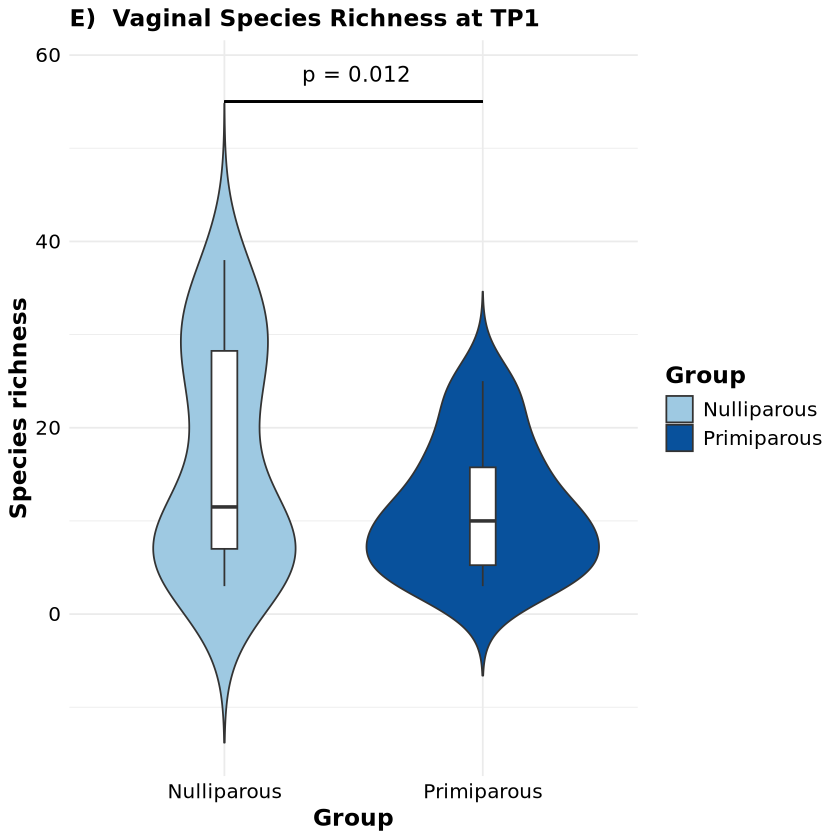

In [469]:
#Richness diversity Violin plot at TP1
my_plot_rich_tp1_v <- ggplot(df_richness_tp1_v, aes(x = Group, y = Species_richness, fill = Group)) +
  geom_violin(trim = FALSE) +
  geom_boxplot(width = 0.1, fill = "white", outlier.shape = NA) +
  scale_fill_manual(values = c("Nulliparous" = "#9EC9E2", "Primiparous" = "#08519C")) +
  labs(title = "E)  Vaginal Species Richness at TP1", x = "Group", y = "Species richness") +
  theme_minimal() +
  shared_theme

my_plot_rich_tp1_v <-  my_plot_rich_tp1_v  +
  annotate("text", x = 1.3, y = 58,
           label = paste("p =", round(rich_tp1_p_v, 3)),
           color = "black", size = 4.5, hjust = 0) +
  geom_segment(aes(x = 1, xend = 2, y = 55, yend = 55),
               color = "black", size = 0.4)

my_plot_rich_tp1_v

### Generate figure 2

In [518]:
my_plot_rich_tp1_v <- my_plot_rich_tp1_v +
  theme(legend.position = "right")

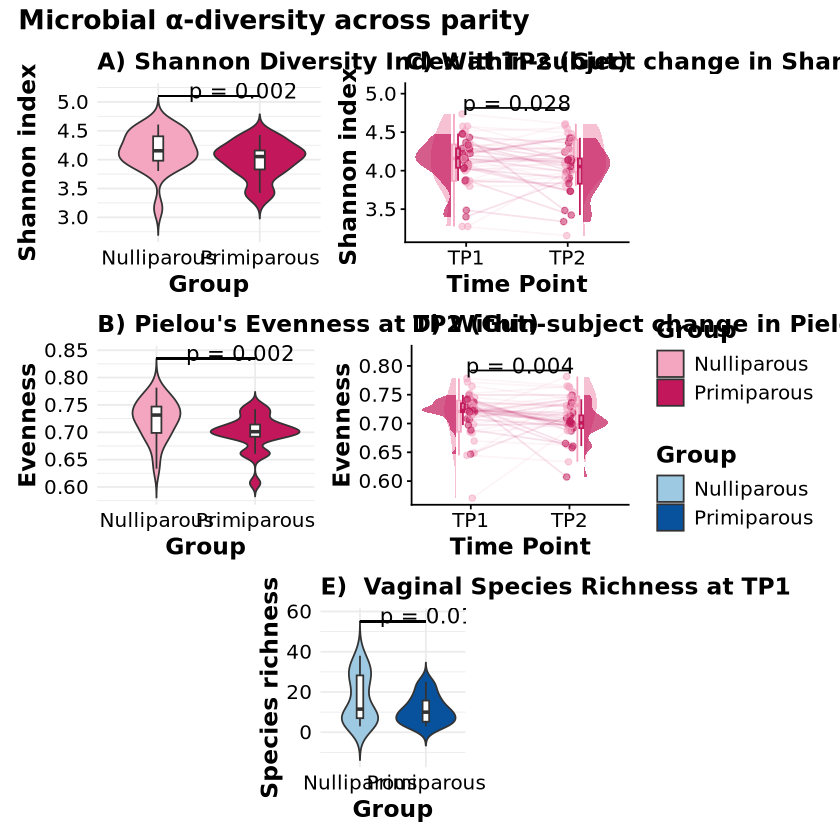

In [516]:
Figure_2_final <-
  (plot_shan_tp2 | plot_shan_nl) /
  (plot_even_tp2 | plot_even_nl) /
  (plot_spacer() | my_plot_rich_tp1_v | plot_spacer()) +
  plot_layout(
    heights = c(1, 1, 1),
    widths = c(1, 1, 1),
    guides = "collect"
  ) +
  plot_annotation(
    title = "Microbial α-diversity across parity",
    theme = theme(
      plot.title = element_text(face = "bold", size = 16)
    )
  )

Figure_2_final

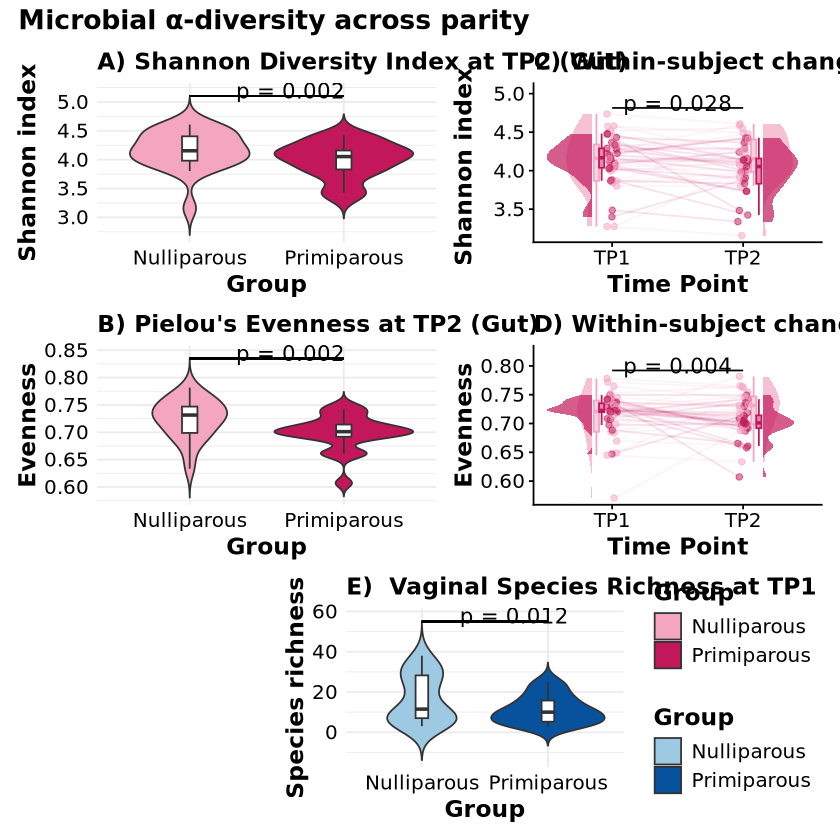

In [527]:
library(patchwork)

design <- "
AAABBB
CCCDDD
##EEFF
"

Figure_2_final <-
  plot_shan_tp2 + plot_shan_nl +
  plot_even_tp2 + plot_even_nl +
  my_plot_rich_tp1_v +
  guide_area() +
  plot_layout(
    design = design,
    guides = "collect"
  ) +
  plot_annotation(
    title = "Microbial α-diversity across parity",
    theme = theme(
      plot.title = element_text(face = "bold", size = 16)
    )
  )

Figure_2_final

In [528]:
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Gut/data/Figure_2_final.pdf"),
      Figure_2_final,
       width  = 500,
       height = 450,
       units  = "mm",
       device = cairo_pdf)

In [529]:
ggsave(
  filename = file.path(base_path, "Consecutive_preg/Github_version/Gut/data/Figure_2_final.eps"),
  plot     = Figure_2,
  width    = 500,
  height   = 450,
  units    = "mm",
  device   = cairo_ps
)

In [530]:
ggsave(
  filename = file.path(base_path, "Consecutive_preg/Github_version/Gut/data/Figure_2_final.tiff"),
  plot     = Figure_2,
  width    = 500,
  height   = 450,
  units    = "mm",
  dpi      = 800,
  device   = "tiff",
  compression = "lzw"
)

In [531]:
#Sahred theme for the PCOA plot
shared_theme <- theme(
  axis.title.x = element_text(size = 14, color = "black"),
  axis.text.x  = element_text(size = 12, color = "black"),
  axis.title.y = element_text(size = 14, color = "black"),
  axis.text.y  = element_text(size = 12, color = "black"),
  plot.title   = element_text(size = 12, color = "black", face = "bold"),
  legend.title = element_text(size = 14, color = "black", face = "bold"),
  legend.text  = element_text(size = 12, color = "black")
)

In [532]:
#PCOA plot
plot_pcoa <- function(dist_obj, meta, title = NULL, r2_val = NULL, p_val = NULL) {
  
  pcoa <- cmdscale(dist_obj, k = 2, eig = TRUE)
  var_exp <- round(100 * pcoa$eig[1:2] / sum(pcoa$eig[pcoa$eig > 0]), 1)
  
  plot_df <- data.frame(
    PC1 = pcoa$points[, 1],
    PC2 = pcoa$points[, 2],
    Group = meta$Group
  )
  
  p <- ggplot(plot_df, aes(PC1, PC2, colour = Group)) +
    geom_point(size = 2.5, alpha = 0.85) +
    stat_ellipse(level = 0.95, linewidth = 0.5) +
    scale_colour_manual(values = c(
      Nulliparous = "#F4A6C1",
      Primiparous = "#C2185B"
    )) +
    labs(title = title,
        x = paste0("PCoA1 [", var_exp[1], "%]"),
        y = paste0("PCoA2 [", var_exp[2], "%]")) +
        theme_minimal() +
    shared_theme +
    theme(
     plot.title   = element_text(face = "plain"),
      axis.title.x = element_text(face = "plain"),
      axis.title.y = element_text(face = "plain")
    )  
  if (!is.null(r2_val) & !is.null(p_val)) {
    label_text <- paste0("R\u00B2 = ", sprintf("%.3f", r2_val), "\np = ", sprintf("%.3f", p_val))
    
    p <- p + annotate("text", x = Inf, y = Inf,
                      label = label_text,
                      hjust = 1.1, vjust = 1.5,
                      size = 3.5, fontface = "bold", color = "black")
  }
  
  p
}

In [533]:
plot_jac_tp2 <- plot_pcoa (dist_jac_tp2, meta_tp2, "Jaccard dissimilarity",r2_j_tp2,p_j_tp2 )
plot_ait_tp2 <- plot_pcoa (dist_ait_tp2, meta_tp2, "Robust Aitchison distance", r2_AT_tp2, p_AT_tp2)
plot_bc_tp2  <- plot_pcoa (dist_bc_tp2,  meta_tp2, "Bray-Curtis dissimilarity",r2_BC_tp2, p_BC_tp2)

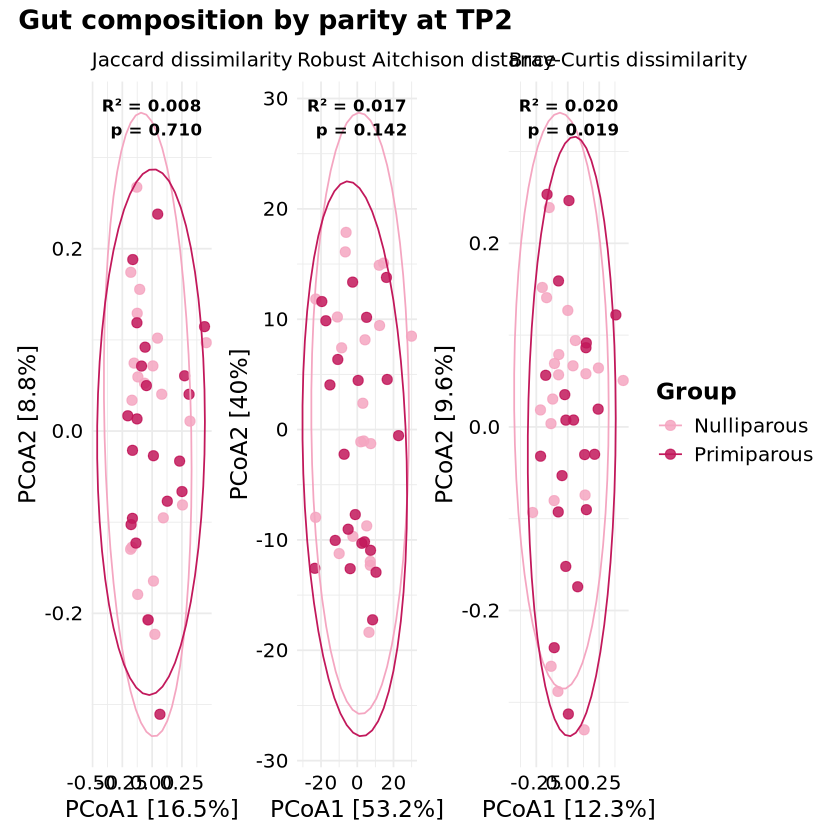

In [534]:

Figure_pcoa_combined_tp2 <- (
  plot_jac_tp2 | plot_ait_tp2 | plot_bc_tp2
) +
  plot_layout(guides = "collect") +
  plot_annotation(
    title = "Gut composition by parity at TP2",
    theme = theme(
      plot.title = element_text(size = 16, face = "bold")
    )
  ) &
  theme(legend.position = "right")

Figure_pcoa_combined_tp2


In [535]:
ggsave(
  filename = file.path(
    base_path,
    "Consecutive_preg/Github_version/Gut/data/gut_pcoa_combined_tp2.pdf"
  ),
  plot   = Figure_pcoa_combined_tp2,
  width  = 400,
  height = 200,
  units  = "mm",
  device = cairo_pdf
)

In [536]:
ggsave(
  filename = file.path(
    base_path,
    "Consecutive_preg/Github_version/Gut/data/gut_pcoa_combined_tp2.eps"
  ),
  plot   = Figure_pcoa_combined_tp2,
  width  = 400,
  height = 200,
  units  = "mm",
  device = cairo_ps
)

In [537]:
ggsave(
  filename = file.path(
    base_path,
    "Consecutive_preg/Github_version/Gut/data/gut_pcoa_combined_tp2.tiff"
  ),
  plot   = Figure_pcoa_combined_tp2,
  width  = 400,
  height = 200,
  units  = "mm",
  device = "tiff",
  dpi    = 600,
  compression = "lzw"
)

In [239]:
# Combine the figures
# Import the first page of each PDF
fig_A <- image_read_pdf(file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/tp1_richness.pdf"
  ), pages = 1, density = 300)
fig_B <- image_read_pdf(file.path(
    base_path,
    "Consecutive_preg/Github_version/Gut/data/gut_pcoa_combined_tp2.pdf"
  ), pages = 1, density = 300)



In [240]:
fig_a <- image_background(fig_A, "white")
fig_b <- image_background(fig_B, "white")

In [241]:
# a bit of white space between A and B
fig_a <- image_border(fig_a, "white", "0x30")

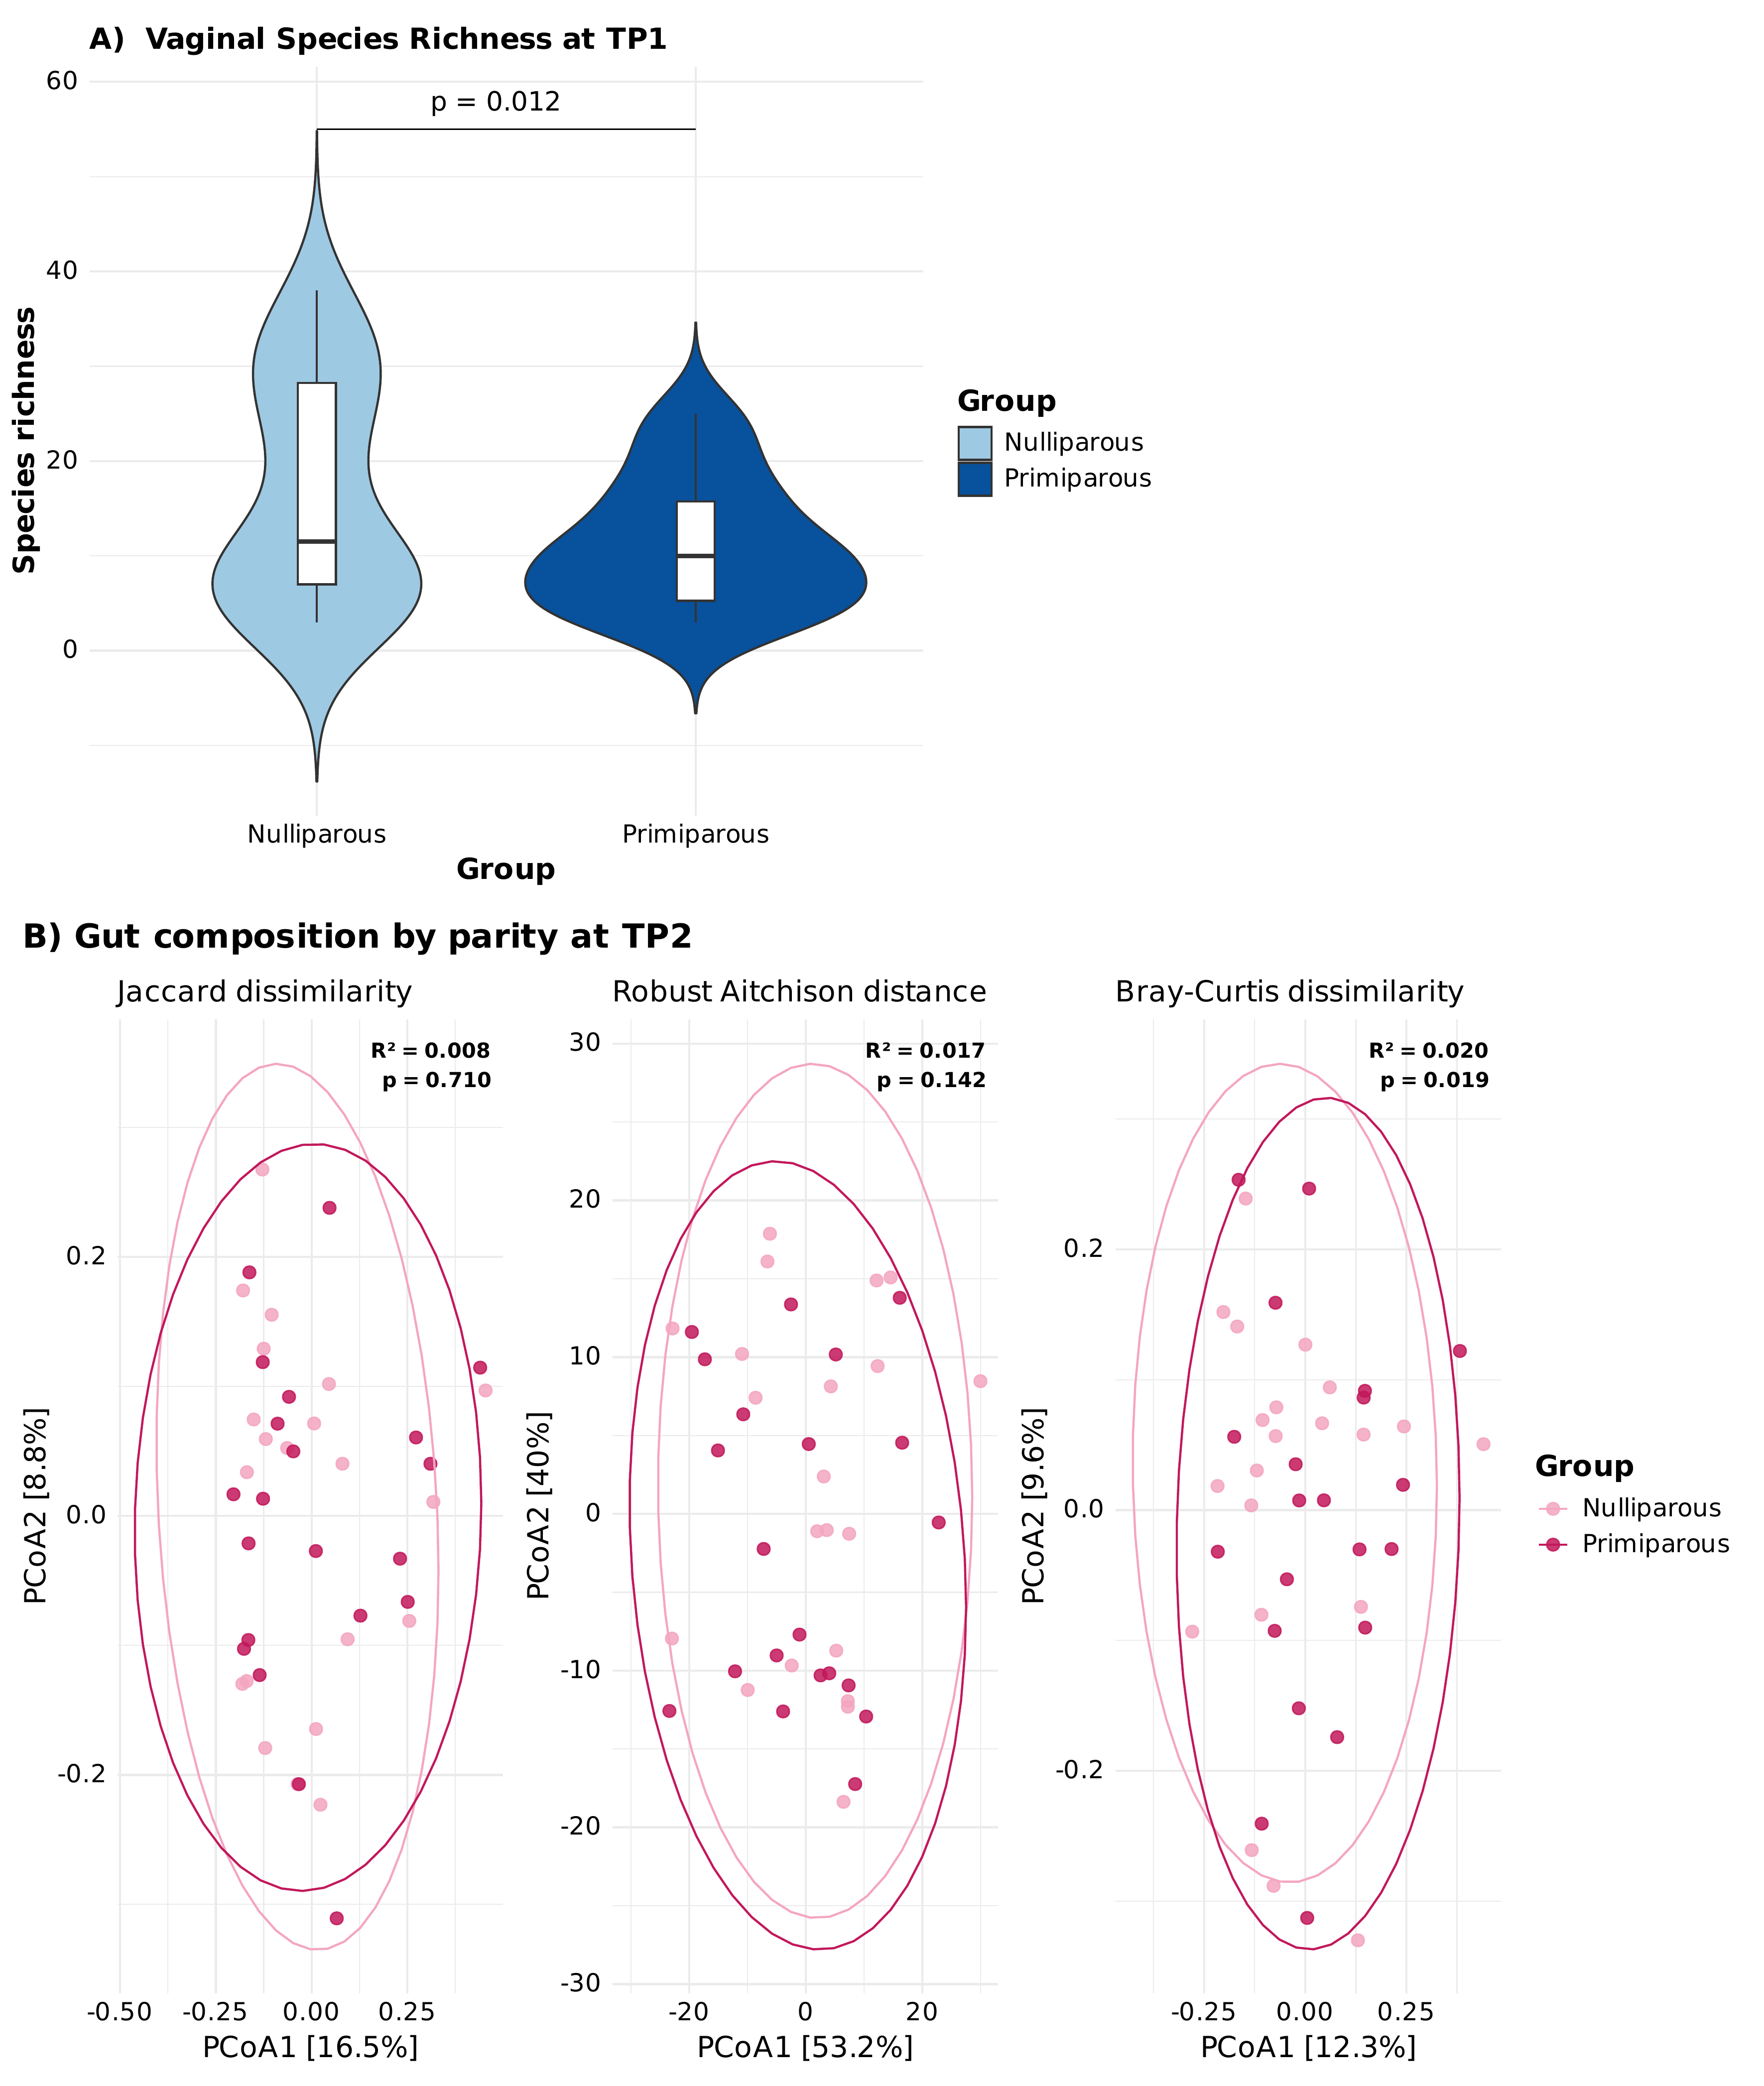

# A tibble: 1 × 7
  format width height colorspace matte filesize density  
  <chr>  <int>  <int> <chr>      <lgl>    <int> <chr>    
1 PNG     3542   4189 sRGB       TRUE         0 +300x+300

In [242]:
A_B_merged <- image_append(c(fig_a, fig_b), stack = TRUE)
A_B_merged

In [236]:
#image_write(A_B_merged, "Figure_3.pdf", format = "pdf", density = 300)

In [243]:
fig_A <- image_annotate(
  fig_A, "A",
  gravity = "northwest",
  location = "+30+30",
  size = 80,
  weight = 700,
  color = "black"
)

fig_B <- image_annotate(
  fig_B, "B",
  gravity = "northwest",
  location = "+30+30",
  size = 80,
  weight = 700,
  color = "black"
)

In [244]:
image_write(
  A_B_merged,
  path = file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/Figure_3.pdf"),
  format = "pdf"
)

In [245]:
image_write(A_B_merged, file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/Figure_3.tiff"),
            format = "tiff", density = 300, compression = "LZW")


In [246]:
image_write(A_B_merged, file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/Figure_3.eps"),
            format = "eps", density = 300)

### Supplementary figures/Data

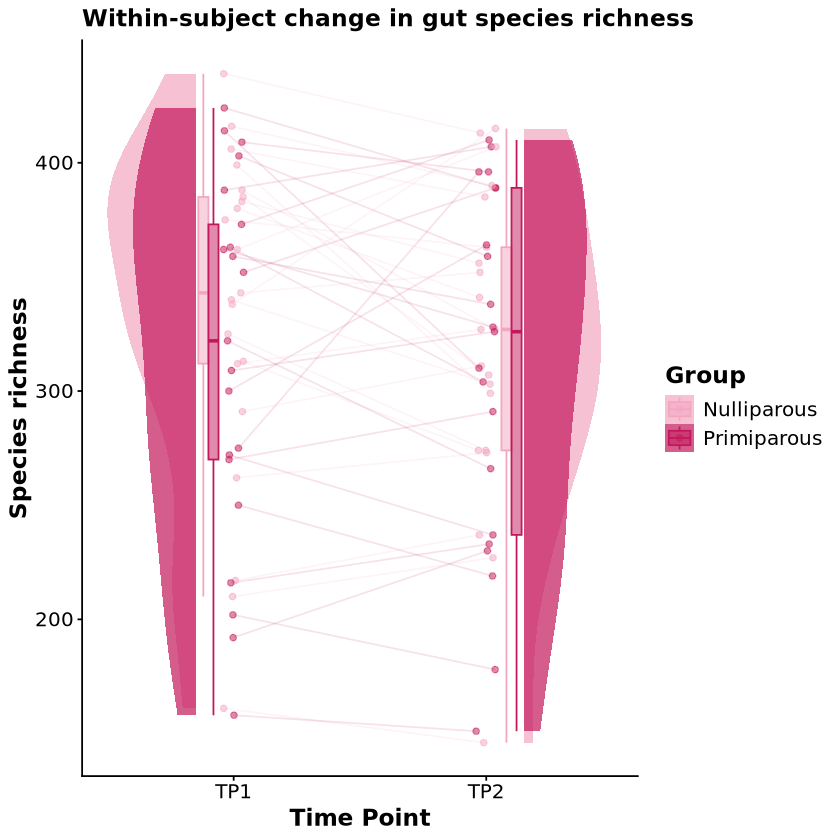

In [251]:
plot_rich <- ggplot(
  alpha_long,
  aes(x = Time_point, y = Species_richness, fill = Group, color = Group)) +
  geom_rain(
    alpha = 0.5,
    rain.side = 'f2x2',
    id.long.var = "pair_id",
    violin.args = list(color = NA, alpha = 0.7),
    line.args = list(alpha = 0.12)
  ) +
  theme_classic() +
  scale_fill_manual(values = c("Nulliparous" = "#F4A6C1", "Primiparous" = "#C2185B")) +
  scale_color_manual(values = c("Nulliparous" = "#F4A6C1", "Primiparous" = "#C2185B"), name = "Group") +
  labs(x = "Time Point", y = "Species richness", title = "Within-subject change in gut species richness") +
  shared_theme

plot_rich

In [252]:
plot_rich <- add_pvalue_top(plot_rich, delta_rich_p, "Species_richness")


In [253]:
plot_rich_nl <- plot_rich + theme(legend.position = "none")




In [254]:
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Gut/data/delta_rich_S1.pdf"),
       plot_rich_nl,
       width  = 200,
       height = 150,
       units  = "mm",
       device = cairo_pdf)

In [256]:
# TIFF 
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Gut/data/delta_rich_S1.tiff"),
       plot_rich_nl,
       width       = 200,
       height      = 150,
       units       = "mm",
       limitsize   = FALSE,
       device      = "tiff",
       dpi         = 300,
       compression = "lzw")

# EPS
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Gut/data/delta_rich_S1.eps"),
       plot_rich_nl,
       width     = 200,
       height    = 150,
       units     = "mm",
       limitsize = FALSE,
       device    = cairo_ps)

In [304]:
#Sahred theme for the PCOA plot
shared_theme_1 <- theme(
  axis.title.x = element_text(size = 12, color = "black"),
  axis.text.x  = element_text(size = 11, color = "black"),
  axis.title.y = element_text(size = 12, color = "black"),
  axis.text.y  = element_text(size = 11, color = "black"),
  plot.title   = element_text(size = 12, color = "black", face = "bold"),
  legend.title = element_text(size = 12, color = "black", face = "bold"),
  legend.text  = element_text(size = 12, color = "black")
)

In [312]:
plot_pcoa_tp1_tp2 <- function(dist_obj, meta, title = NULL, r2_val = NULL, p_val = NULL) {
  
  pcoa <- cmdscale(dist_obj, k = 2, eig = TRUE)
  var_exp <- round(100 * pcoa$eig[1:2] / sum(pcoa$eig[pcoa$eig > 0]), 1)
  
  plot_df <- data.frame(
    PC1 = pcoa$points[, 1],
    PC2 = pcoa$points[, 2],
    Group = meta$Group,
    Time_point = meta$Time_point,
    woman = meta$Q1_Personnummer
  )
  
  p <- ggplot(plot_df, aes(PC1, PC2)) +
    geom_path(aes(group = interaction(woman, Group)),
              colour = "black",
              arrow = arrow(length = unit(0.15, "cm")),
              alpha = 0.4) +
    geom_point(aes(colour = Group, shape = Time_point), size = 2) +
    scale_colour_manual(values = c(
      Nulliparous = "#F4A6C1",
      Primiparous = "#C2185B"
    )) +
    labs(title = title,
        x = paste0("PCoA1 [", var_exp[1], "%]"),
        y = paste0("PCoA2 [", var_exp[2], "%]")) +
    theme_minimal() +
    shared_theme_1
  
  # Place stats label top-right, positioned relative to this plot's own data range
  if (!is.null(r2_val) & !is.null(p_val)) {
    x_pos <- max(plot_df$PC1, na.rm = TRUE)
    y_pos <- max(plot_df$PC2, na.rm = TRUE)
    
    label_text <- paste0("R\u00B2 = ", sprintf("%.3f", r2_val), "\np = ", sprintf("%.3f", p_val))
    
    p <- p + annotate("text", x = x_pos, y = y_pos,
                      label = label_text,
                      hjust = 1, vjust = 1,
                      size = 3.5, fontface = "bold", color = "black")
  }
  
  p
}

In [313]:
plot_bc_tp1_tp2  <- plot_pcoa_tp1_tp2(delta_dist_bc,  delta_meta, "Bray-Curtis dissimilarity",       r2_bc, p_bc)
plot_jac_tp1_tp2 <- plot_pcoa_tp1_tp2(delta_dist_jac, delta_meta, "Jaccard dissimilarity",           r2_J,  p_J)
plot_ait_tp1_tp2 <- plot_pcoa_tp1_tp2(delta_dist_ait, delta_meta, "Robust Aitchison distance",  r2_AT, p_AT)

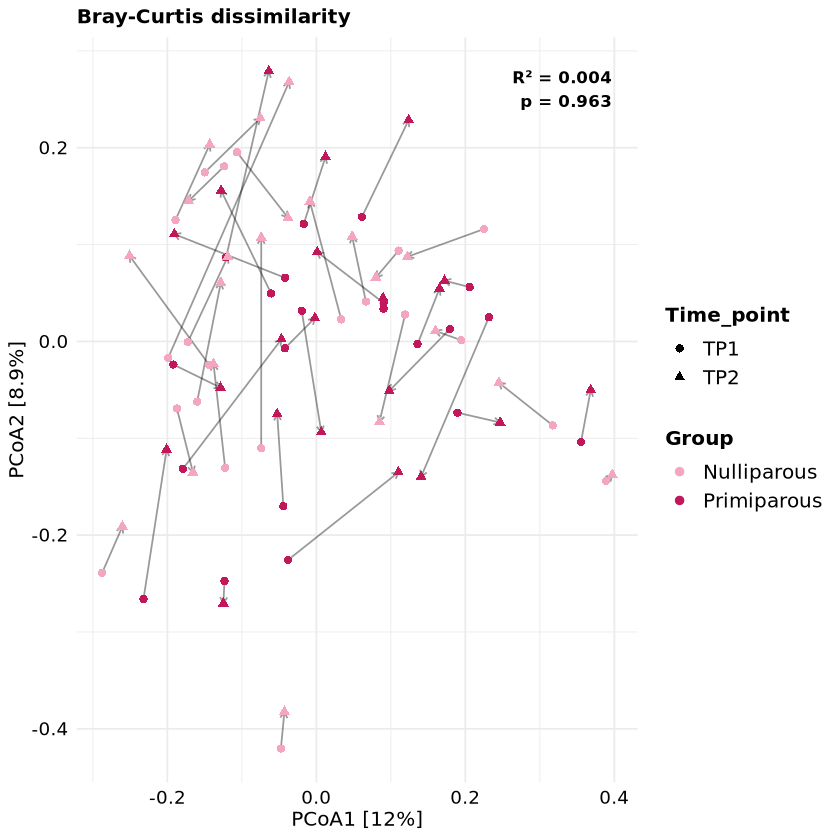

In [314]:
plot_bc_tp1_tp2

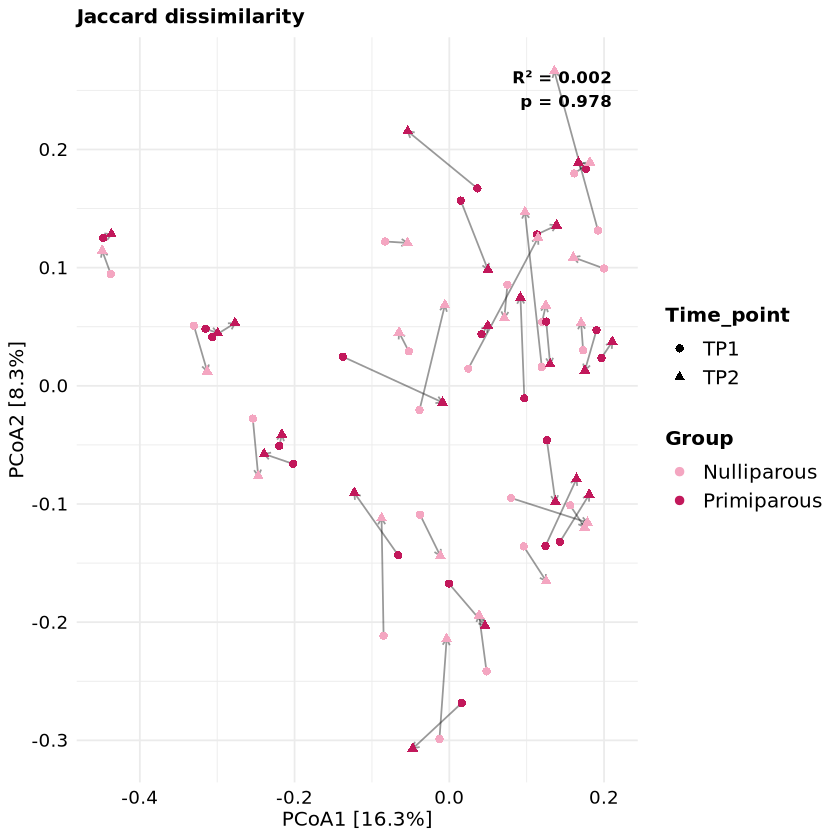

In [315]:
plot_jac_tp1_tp2

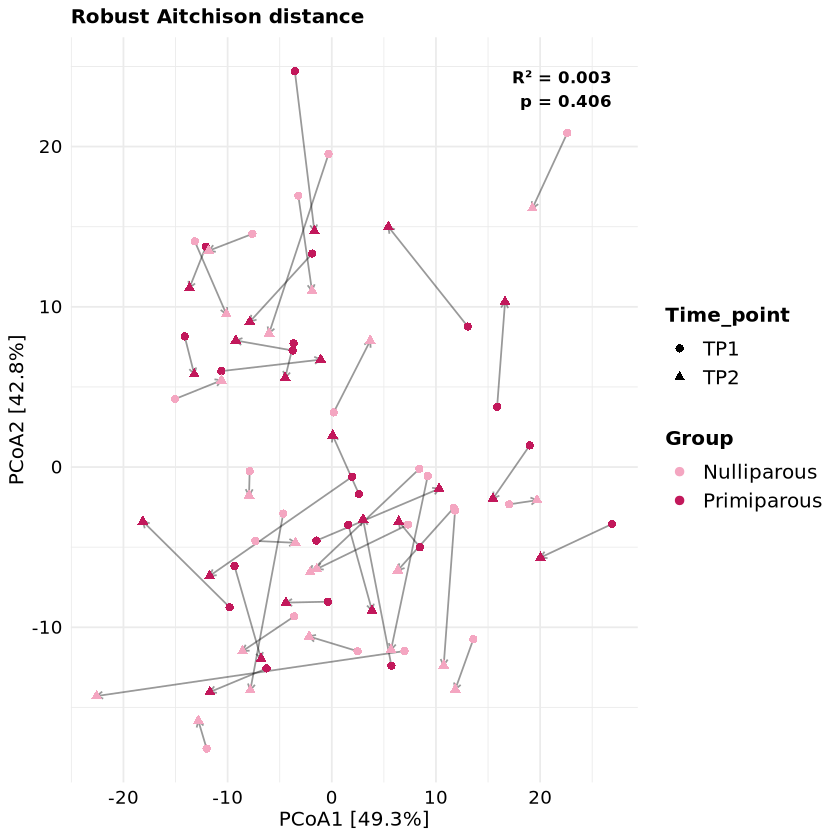

In [316]:
plot_ait_tp1_tp2

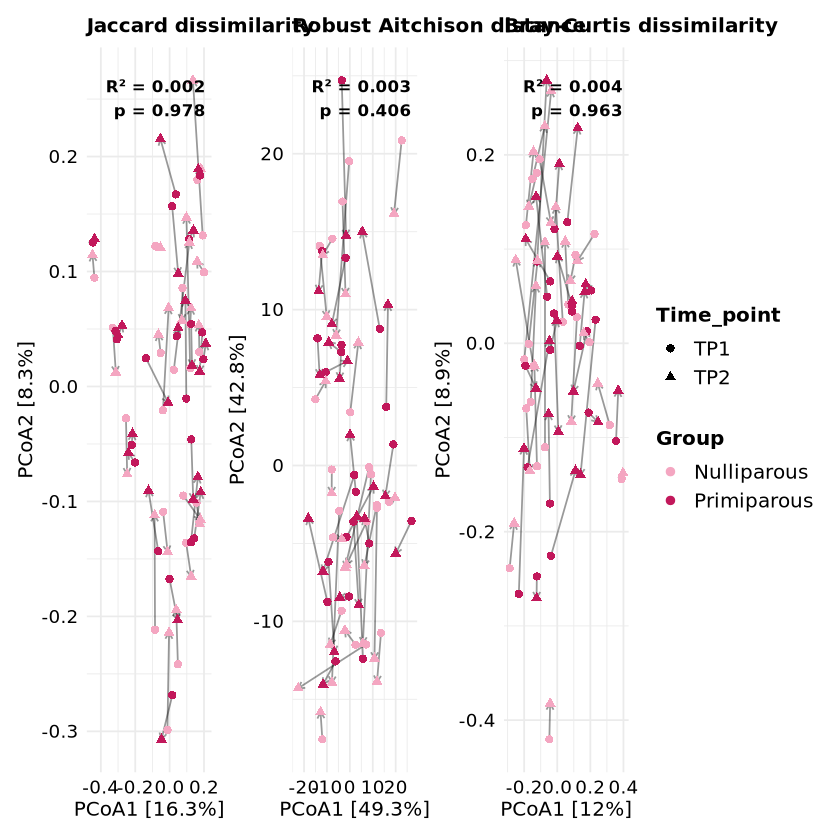

In [317]:
Figure_pcoa_combined <- (plot_jac_tp1_tp2| plot_ait_tp1_tp2 | plot_bc_tp1_tp2) +
  plot_layout(guides = "collect") &
  theme(legend.position = "right")

Figure_pcoa_combined

In [318]:
heading <- function(text, size = 14, face = "bold", hjust = 0) {
  ggplot() +
    annotate("text", x = hjust, y = 0.5, label = text,
             size = size / .pt, fontface = face, hjust = hjust) +
    scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
    scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
    theme_void()
}

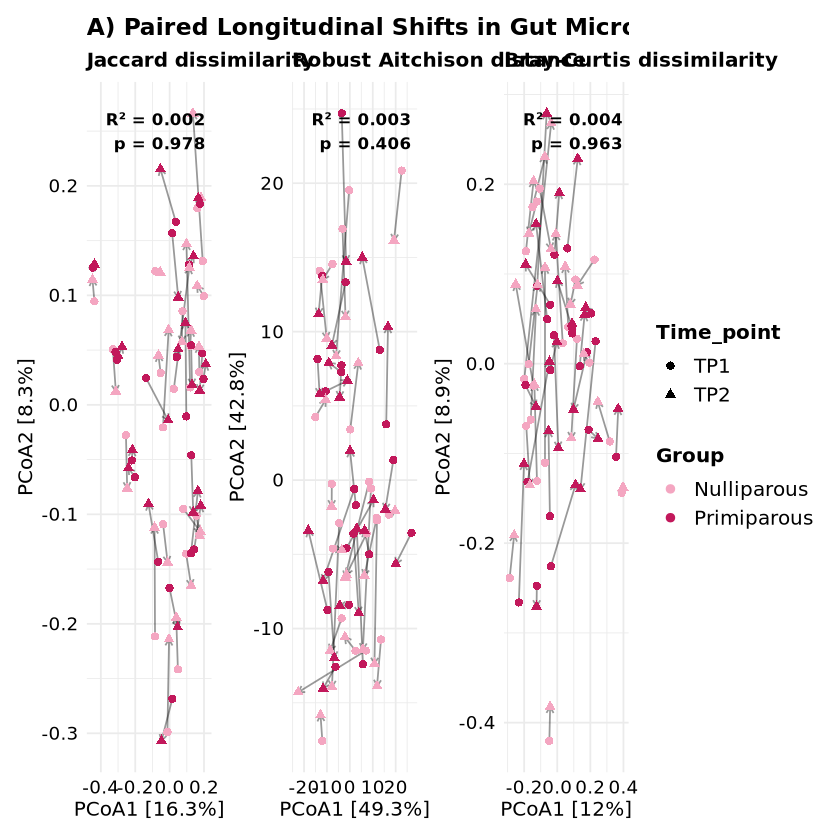

In [335]:

row1_heading_pcoa <- heading("A) Paired Longitudinal Shifts in Gut Microbial Community Composition")
Figure_part_A_s3 <- (row1_heading_pcoa /Figure_pcoa_combined ) +
 plot_layout(heights = c(0.05, 1), guides = "collect") &
  theme(legend.position = "right")

Figure_part_A_s3

In [336]:
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Gut/data/S3_A_delta_beta.pdf"),
      Figure_part_A_s3,
       width  = 300,
       height = 150,
       units  = "mm",
       device = cairo_pdf)
# Later, combine with the Vaginal microbiome